In [ ]:
!pip -q install beautifulsoup4 lxml requests

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import glob
import pandas as pd

matches = glob.glob(
    "/content/drive/MyDrive/**/PGPTrait*Endocrine*.csv",
    recursive=True
)

print("Found:", matches)

SURVEY_FILE = matches[0]
df = pd.read_csv(SURVEY_FILE)

print("Loaded:", SURVEY_FILE)
print("Rows:", len(df))
print(df.columns.tolist())

Mounted at /content/drive
Found: ['/content/drive/MyDrive/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv', '/content/drive/MyDrive/last heave for g3/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv']
Loaded: /content/drive/MyDrive/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv
Rows: 2456
['Participant', 'Timestamp', 'Do not touch!', 'Have you ever been diagnosed with any of the following conditions?', 'Other condition not listed here?']


In [ ]:
participant_col = "Participant"
condition_col = "Have you ever been diagnosed with any of the following conditions?"

# clean text
df[participant_col] = df[participant_col].astype(str).str.strip()
df[condition_col] = df[condition_col].fillna("").astype(str)

# inspect all diabetes-related responses first
diabetes_rows = df[df[condition_col].str.contains("diabet", case=False, na=False)]

print("Unique participants:", df[participant_col].nunique())
print("\nDiabetes-related responses:")
print(diabetes_rows[condition_col].value_counts())

# define T2D cases
t2d_mask = df[condition_col].str.contains(
    "Diabetes mellitus, type 2",
    case=False,
    regex=False
)

t2d_ids = sorted(df.loc[t2d_mask, participant_col].unique())

print("\nUnique T2D cases:", len(t2d_ids))
print("\nFirst 10 IDs:")
print(t2d_ids[:10])

Unique participants: 2202

Diabetes-related responses:
Have you ever been diagnosed with any of the following conditions?
Diabetes mellitus, type 2, High cholesterol (hypercholesterolemia), High triglycerides (hypertriglyceridemia)                                                                                    26
Diabetes mellitus, type 2                                                                                                                                                                        24
Diabetes mellitus, type 2, High cholesterol (hypercholesterolemia)                                                                                                                               18
Diabetes mellitus, type 1                                                                                                                                                                         9
Diabetes mellitus, type 2, Gout                                                               

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re

URL = "https://my.pgp-hms.org/public_genetic_data"

headers = {
    "User-Agent": "Mozilla/5.0"
}

r = requests.get(URL, headers=headers, timeout=120)

print("Status:", r.status_code)
print("Characters downloaded:", len(r.text))

soup = BeautifulSoup(r.text, "lxml")

# show page title + number of tables
print("Title:", soup.title.get_text(strip=True) if soup.title else None)

tables = soup.find_all("table")
print("Tables found:", len(tables))

# print first few rows so we can see exact structure
for i, tr in enumerate(soup.find_all("tr")[:8]):
    cells = [x.get_text(" ", strip=True) for x in tr.find_all(["th", "td"])]
    print(i, cells)

Status: 200
Characters downloaded: 3781902
Title: Personal Genome Project: Public Genetic Data
Tables found: 1
0 ['', 'Participant', 'Published', 'Data type', 'Source', 'Name', 'Download', 'Report']
1 ['', 'huEDADD6', '2026-08-26', '23andMe', 'Participant', 'Male_Ukranian_descent--1991-O(I) Rh+', 'Download (16.2 MB)', '']
2 ['', 'hu5F4ABB', '2026-08-14', '23andMe', 'Participant', 'Jessica', 'Download (5.63 MB)', '']
3 ['', 'huA08F4D', '2026-07-07', '23andMe', 'Participant', 'lorena1234', 'Download (15.9 MB)', '']
4 ['', 'hu375852', '2026-05-29', 'Ancestry', 'Participant', 'Jesshamil', 'Download (17.5 MB)', '']
5 ['', 'hu3B032D', '2026-05-19', 'Veritas Genetics', 'Participant', 'ermitosequencing', 'Download (38.8 KB)', '']
6 ['', 'huA08F4D', '2026-05-14', '23andMe', 'Participant', 'lorena123', 'Download (15.9 MB)', '']
7 ['', 'hu3B032D', '2026-05-12', 'Veritas Genetics', 'Participant', 'ersnpindelgenome', 'Download (1.35 GB)', '']


In [ ]:
from urllib.parse import urljoin

rows = []

for tr in soup.find_all("tr")[1:]:
    cells = tr.find_all("td")
    if len(cells) < 7:
        continue

    participant = cells[1].get_text(" ", strip=True)
    published = cells[2].get_text(" ", strip=True)
    data_type = cells[3].get_text(" ", strip=True)
    source = cells[4].get_text(" ", strip=True)
    name = cells[5].get_text(" ", strip=True)
    download_text = cells[6].get_text(" ", strip=True)

    # grab actual download link
    download_link = None
    a = cells[6].find("a", href=True)
    if a:
        download_link = urljoin(URL, a["href"])

    rows.append({
        "Participant": participant,
        "Published": published,
        "Data_type": data_type,
        "Source": source,
        "Name": name,
        "Download_text": download_text,
        "Download_URL": download_link
    })

catalog = pd.DataFrame(rows)

print("Catalog rows:", len(catalog))
print("Unique participants with genetic data:", catalog["Participant"].nunique())

# intersect with our 99 confirmed T2D IDs
t2d_genetic = catalog[catalog["Participant"].isin(t2d_ids)].copy()

print("\nT2D cases total:", len(t2d_ids))
print("T2D cases with ANY genetic-data entry:",
      t2d_genetic["Participant"].nunique())

print("\nData types among T2D hits:")
print(t2d_genetic["Data_type"].value_counts())

print("\nFirst 30 matching rows:")
display(t2d_genetic.head(30))

Catalog rows: 3961
Unique participants with genetic data: 1407

T2D cases total: 99
T2D cases with ANY genetic-data entry: 34

Data types among T2D hits:
Data_type
23andMe                                                    33
Veritas Genetics                                           29
Family Tree DNA                                            21
biometric data - CSV or similar                             4
image                                                       2
VCF                                                         1
phenotype data                                              1
Illumina                                                    1
National Geographic                                         1
Photo of Don Magnuson                                       1
Ancestory DNA                                               1
Genographic Project                                         1
Chrome HTML Document                                        1
Promethease Data              

,Participant,Published,Data_type,Source,Name,Download_text,Download_URL
125,hu3C86DB,2020-05-03,Family Tree DNA,Participant,Big Y,Download (712 MB),https://my.pgp-hms.org/user_file/download/3922
312,hu9A9B2D,2019-01-11,Veritas Genetics,Participant,Robert Lacy's vcf,Download (656 MB),https://my.pgp-hms.org/user_file/download/3651
388,huAF469C,2018-07-10,phenotype data,Participant,stephen bradley,Download (662 KB),https://my.pgp-hms.org/user_file/download/3563
440,huE1E24D,2018-05-19,Family Tree DNA,Participant,89815,Download (6.08 MB),https://my.pgp-hms.org/user_file/download/3513
441,huE1E24D,2018-05-19,Family Tree DNA,Participant,89815,Download (724 Bytes),https://my.pgp-hms.org/user_file/download/3512
459,hu1F84A7,2018-04-03,23andMe,Participant,wdmulanaxjr,Download (14.4 MB),https://my.pgp-hms.org/user_file/download/3471
724,hu4F45FB,2017-12-05,VCF,Participant,Lee1973VCF,Download (463 MB),https://my.pgp-hms.org/user_file/download/3198
725,hu4F45FB,2017-12-05,23andMe,Participant,Lee1973,Download (16.1 MB),https://my.pgp-hms.org/user_file/download/3197
1039,hu6F6F6C,2017-07-03,23andMe,Participant,Debgail52,Download (5.56 MB),https://my.pgp-hms.org/user_file/download/2866
1103,huF421B2,2017-05-27,23andMe,Participant,Gloria Algeo,Download (14.7 MB),https://my.pgp-hms.org/user_file/download/2799


In [ ]:
# STRICT usable-genome-wide classification

def strict_usable(row):
    dt = str(row["Data_type"]).lower()
    name = str(row["Name"]).lower()

    # clear genome-wide SNP arrays
    if "23andme" in dt:
        return True

    if "ancestry.com" in dt or "ancestory dna" in dt:
        return True

    # generic VCF upload
    if dt.strip() == "vcf":
        return True

    # Veritas whole-genome VCF
    if "veritas genetics" in dt and "vcf" in name:
        return True

    return False


t2d_genetic["Strict_usable"] = t2d_genetic.apply(strict_usable, axis=1)

strict_hits = t2d_genetic[t2d_genetic["Strict_usable"]].copy()

print("T2D cases with STRICT usable genome-wide data:",
      strict_hits["Participant"].nunique())

print("\nParticipants:")
print(sorted(strict_hits["Participant"].unique()))

print("\nUsable files by data type:")
print(strict_hits["Data_type"].value_counts())

# participant-level summary
strict_summary = (
    strict_hits.groupby("Participant")
    .agg(
        Data_types=("Data_type", lambda x: " | ".join(sorted(set(x)))),
        Files=("Name", lambda x: " | ".join(sorted(set(x))))
    )
    .reset_index()
)

display(strict_summary)

NameError: name 't2d_genetic' is not defined

In [ ]:
# Show every candidate file with size/name so we can QC the 29

qc_cols = [
    "Participant",
    "Data_type",
    "Name",
    "Download_text",
    "Download_URL"
]

qc = strict_hits[qc_cols].sort_values(
    ["Participant", "Data_type"]
).reset_index(drop=True)

display(qc)

print("\nUnique candidate participants:", qc["Participant"].nunique())
print("Candidate files:", len(qc))

NameError: name 'strict_hits' is not defined

In [ ]:
import re
import pandas as pd

def size_to_mb(txt):
    if pd.isna(txt):
        return None

    m = re.search(r'([\d.]+)\s*(KB|MB|GB)', str(txt))
    if not m:
        return None

    val = float(m.group(1))
    unit = m.group(2)

    if unit == "KB":
        return val / 1024
    if unit == "MB":
        return val
    if unit == "GB":
        return val * 1024

qc2 = qc.copy()
qc2["Size_MB"] = qc2["Download_text"].apply(size_to_mb)

# Throw out obvious tiny/non-genome-wide files
qc2 = qc2[qc2["Size_MB"] >= 1].copy()

# Preference order:
# 23andMe raw > Ancestry raw > VCF/WGS
priority = {
    "23andMe": 1,
    "Ancestory DNA": 2,
    "Ancestry.com (zip)": 2,
    "VCF": 3,
    "Veritas Genetics": 3,
}

qc2["Priority"] = qc2["Data_type"].map(priority).fillna(99)

# prefer larger file within same type
best_files = (
    qc2.sort_values(
        ["Participant", "Priority", "Size_MB"],
        ascending=[True, True, False]
    )
    .drop_duplicates("Participant")
    .reset_index(drop=True)
)

print("Strong candidate T2D participants:", best_files["Participant"].nunique())

display(
    best_files[
        ["Participant", "Data_type", "Name", "Size_MB", "Download_URL"]
    ]
)

NameError: name 'qc' is not defined

In [ ]:
import requests, io, zipfile, gzip, re
import pandas as pd

results = []

# skip huge WGS/VCF for now
test_files = best_files[best_files["Size_MB"] < 100].copy()

def inspect_genotype_file(row):
    pid = row["Participant"]
    url = row["Download_URL"]

    try:
        resp = requests.get(url, timeout=120)
        resp.raise_for_status()
        raw = resp.content

        # unzip if needed
        if raw[:2] == b"PK":
            with zipfile.ZipFile(io.BytesIO(raw)) as z:
                names = [n for n in z.namelist() if not n.endswith("/")]
                if not names:
                    raise ValueError("Empty zip")
                raw = z.read(names[0])

        # gunzip if needed
        elif raw[:2] == b"\x1f\x8b":
            raw = gzip.decompress(raw)

        text = raw.decode("utf-8", errors="ignore")

        total_variant_rows = 0
        autosomal_rows = 0
        rsid_rows = 0

        for line in text.splitlines():
            if not line or line.startswith("#"):
                continue

            parts = re.split(r"\s+|,", line.strip())

            if len(parts) < 4:
                continue

            total_variant_rows += 1

            # rsID check
            if parts[0].lower().startswith("rs"):
                rsid_rows += 1

            # try chromosome column used by 23andMe:
            # rsid chromosome position genotype
            chrom = parts[1].replace("chr", "")

            if chrom.isdigit() and 1 <= int(chrom) <= 22:
                autosomal_rows += 1

        return {
            "Participant": pid,
            "Data_type": row["Data_type"],
            "Size_MB": row["Size_MB"],
            "Total_variant_rows": total_variant_rows,
            "Autosomal_rows": autosomal_rows,
            "RSID_rows": rsid_rows,
            "PASS_genomewide": autosomal_rows >= 100000,
            "Error": None
        }

    except Exception as e:
        return {
            "Participant": pid,
            "Data_type": row["Data_type"],
            "Size_MB": row["Size_MB"],
            "Total_variant_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS_genomewide": False,
            "Error": str(e)
        }

for i, row in test_files.iterrows():
    print("Checking", row["Participant"])
    results.append(inspect_genotype_file(row))

validation = pd.DataFrame(results)

display(validation)

print("\nPassed genome-wide QC:",
      validation["PASS_genomewide"].sum(),
      "of",
      len(validation))

print("\nFailures:")
display(validation[~validation["PASS_genomewide"]])

Checking hu0B9C47
Checking hu11603C


KeyboardInterrupt: 

In [ ]:
import requests, io, zipfile

test_ids = ["hu0B9C47", "hu1F84A7", "hu3C86DB", "huAF469C"]

for pid in test_ids:
    row = best_files[best_files["Participant"] == pid].iloc[0]

    print("\n====================")
    print(pid, row["Download_URL"])

    r = requests.get(row["Download_URL"], timeout=120)
    print("status:", r.status_code)
    print("content-type:", r.headers.get("content-type"))
    print("bytes:", len(r.content))
    print("first 20 bytes:", r.content[:20])

    if r.content[:2] == b"PK":
        print("ZIP FILE")
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            for name in z.namelist():
                info = z.getinfo(name)
                print("  ", name, info.file_size)

    else:
        print("NOT ZIP")
        print(r.content[:500].decode("utf-8", errors="ignore"))


hu0B9C47 https://my.pgp-hms.org/user_file/download/1655
status: 200
content-type: text/html; charset=utf-8
bytes: 1435
first 20 bytes: b'<!DOCTYPE HTML>\n<HTM'
NOT ZIP
<!DOCTYPE HTML>
<HTML><HEAD>
  <META name="robots" content="NOINDEX">
  <TITLE>65c67c3aa3d2ee9f394af9cc15d3bdf4&#43;95</TITLE>
  <STYLE type="text/css">
    body {
      margin: 1.5em;
    }
    pre {
      background-color: #D9EDF7;
      border-radius: .25em;
      padding: .75em;
      overflow: auto;
    }
    .footer p {
      font-size: 82%;
    }
    hr {
      border: 1px solid #808080;
    }
    ul {
      padding: 0;
    }
    ul li {
      font-family: monospace;
      list-style: non

hu1F84A7 https://my.pgp-hms.org/user_file/download/3471
status: 200
content-type: text/html; charset=utf-8
bytes: 1458
first 20 bytes: b'<!DOCTYPE HTML>\n<HTM'
NOT ZIP
<!DOCTYPE HTML>
<HTML><HEAD>
  <META name="robots" content="NOINDEX">
  <TITLE>902a00ac5682118af68a0b8e6f086c32&#43;103</TITLE>
  <STYLE type="text/css">
    bod

In [ ]:
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import requests

test_pid = "hu0B9C47"
row = best_files[best_files["Participant"] == test_pid].iloc[0]

r = requests.get(row["Download_URL"], timeout=120)
s = BeautifulSoup(r.text, "html.parser")

print("PAGE TITLE:", s.title.get_text(strip=True) if s.title else None)

print("\nLINKS FOUND:")
for a in s.find_all("a", href=True):
    print(
        "TEXT:", a.get_text(" ", strip=True),
        "\nHREF:", urljoin(row["Download_URL"], a["href"]),
        "\n"
    )

PAGE TITLE: 65c67c3aa3d2ee9f394af9cc15d3bdf4+95

LINKS FOUND:
TEXT: genome_hu0B9C47_Full_20151123151332.txt 
HREF: https://my.pgp-hms.org/user_file/download/genome_hu0B9C47_Full_20151123151332.txt 



In [ ]:
import requests, io, zipfile, gzip, re
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

def get_real_download_url(wrapper_url):
    r = requests.get(wrapper_url, timeout=120)
    r.raise_for_status()

    ctype = r.headers.get("content-type", "").lower()

    # if it's already a real file, use it directly
    if "text/html" not in ctype:
        return wrapper_url

    soup = BeautifulSoup(r.text, "html.parser")

    links = soup.find_all("a", href=True)
    if not links:
        raise ValueError("No download link found in wrapper")

    # first downloadable file link
    return urljoin(wrapper_url, links[0]["href"])


def inspect_real_genotype_file(row):
    pid = row["Participant"]

    try:
        real_url = get_real_download_url(row["Download_URL"])

        resp = requests.get(real_url, timeout=180)
        resp.raise_for_status()
        raw = resp.content

        # ZIP
        if raw[:2] == b"PK":
            with zipfile.ZipFile(io.BytesIO(raw)) as z:
                files = [
                    x for x in z.infolist()
                    if not x.is_dir()
                ]

                # choose largest file
                target = max(files, key=lambda x: x.file_size)
                raw = z.read(target.filename)

        # GZIP
        elif raw[:2] == b"\x1f\x8b":
            raw = gzip.decompress(raw)

        text = raw.decode("utf-8", errors="ignore")

        total = 0
        autosomal = 0
        rsids = 0

        for line in text.splitlines():
            if not line or line.startswith("#"):
                continue

            parts = re.split(r"[\t, ]+", line.strip())

            if len(parts) < 4:
                continue

            total += 1

            if parts[0].lower().startswith("rs"):
                rsids += 1

            chrom = parts[1].lower().replace("chr", "")

            if chrom.isdigit() and 1 <= int(chrom) <= 22:
                autosomal += 1

        return {
            "Participant": pid,
            "Real_URL": real_url,
            "Total_rows": total,
            "Autosomal_rows": autosomal,
            "RSID_rows": rsids,
            "PASS": autosomal >= 100000,
            "Error": None
        }

    except Exception as e:
        return {
            "Participant": pid,
            "Real_URL": None,
            "Total_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS": False,
            "Error": str(e)
        }


results = []

test_files = best_files[best_files["Size_MB"] < 100].copy()

for _, row in test_files.iterrows():
    print("Checking", row["Participant"])
    results.append(inspect_real_genotype_file(row))

real_validation = pd.DataFrame(results)

display(real_validation)

print(
    "\nPassed actual genome-wide QC:",
    real_validation["PASS"].sum(),
    "of",
    len(real_validation)
)

print("\nFailures:")
display(real_validation[~real_validation["PASS"]])

Checking hu0B9C47
Checking hu11603C


KeyboardInterrupt: 

In [ ]:
import requests, io, zipfile, gzip, re
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

def get_real_download_url(wrapper_url):
    # let requests follow redirect to the Arvados collection page
    r = requests.get(wrapper_url, timeout=120)
    r.raise_for_status()

    final_page_url = r.url  # IMPORTANT: redirected Arvados URL

    ctype = r.headers.get("content-type", "").lower()

    if "text/html" not in ctype:
        return wrapper_url

    soup = BeautifulSoup(r.text, "html.parser")

    links = soup.find_all("a", href=True)
    if not links:
        raise ValueError("No file link found")

    # build link relative to redirected Arvados page, NOT pgp-hms
    return urljoin(final_page_url, links[0]["href"])


def inspect_real_genotype_file(row):
    pid = row["Participant"]

    try:
        real_url = get_real_download_url(row["Download_URL"])

        resp = requests.get(real_url, timeout=180)
        resp.raise_for_status()
        raw = resp.content

        if raw[:2] == b"PK":
            with zipfile.ZipFile(io.BytesIO(raw)) as z:
                files = [x for x in z.infolist() if not x.is_dir()]
                target = max(files, key=lambda x: x.file_size)
                raw = z.read(target.filename)

        elif raw[:2] == b"\x1f\x8b":
            raw = gzip.decompress(raw)

        text = raw.decode("utf-8", errors="ignore")

        total = 0
        autosomal = 0
        rsids = 0

        for line in text.splitlines():
            if not line or line.startswith("#"):
                continue

            parts = re.split(r"[\t, ]+", line.strip())

            if len(parts) < 4:
                continue

            total += 1

            if parts[0].lower().startswith("rs"):
                rsids += 1

            chrom = parts[1].lower().replace("chr", "")

            if chrom.isdigit() and 1 <= int(chrom) <= 22:
                autosomal += 1

        return {
            "Participant": pid,
            "Real_URL": real_url,
            "Total_rows": total,
            "Autosomal_rows": autosomal,
            "RSID_rows": rsids,
            "PASS": autosomal >= 100000,
            "Error": None
        }

    except Exception as e:
        return {
            "Participant": pid,
            "Real_URL": None,
            "Total_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS": False,
            "Error": str(e)
        }


results = []

test_files = best_files[best_files["Size_MB"] < 100].copy()

for _, row in test_files.iterrows():
    print("Checking", row["Participant"])
    results.append(inspect_real_genotype_file(row))

real_validation = pd.DataFrame(results)

display(real_validation)

print(
    "\nPassed actual genome-wide QC:",
    real_validation["PASS"].sum(),
    "of",
    len(real_validation)
)

print("\nFailures:")
display(real_validation[~real_validation["PASS"]])

Checking hu0B9C47
Checking hu11603C


KeyboardInterrupt: 

In [ ]:
print("Passed:", real_validation["PASS"].sum(), "of", len(real_validation))

display(
    real_validation[
        ["Participant", "Autosomal_rows", "RSID_rows", "PASS", "Error"]
    ]
)

NameError: name 'real_validation' is not defined

In [ ]:
row = best_files[best_files["Participant"] == "hu9A9B2D"].iloc[0]

print(row[["Participant", "Data_type", "Name", "Size_MB", "Download_URL"]])

real_url = get_real_download_url(row["Download_URL"])
print("Real URL:", real_url)

r = requests.get(real_url, stream=True, timeout=180)
r.raise_for_status()

print("Content type:", r.headers.get("content-type"))
print("Content length:", r.headers.get("content-length"))

Participant                                           hu9A9B2D
Data_type                                     Veritas Genetics
Name                                         Robert Lacy's vcf
Size_MB                                                  656.0
Download_URL    https://my.pgp-hms.org/user_file/download/3651
Name: 18, dtype: object
Real URL: https://a582d93cbd3ab6b082901b67d23a382c-514.collections.ac2it.arvadosapi.com/_/Sample_55001603035357-EXT.full.vcf.gz
Content type: application/gzip
Content length: 687791043


In [ ]:
import requests
import gzip
import io

url = real_url  # from your previous cell

r = requests.get(url, stream=True, timeout=180)
r.raise_for_status()

# stream-decompress the gzipped VCF
gz = gzip.GzipFile(fileobj=r.raw)

total_variants = 0
autosomal_variants = 0
chrom_counts = {}

for raw_line in gz:
    line = raw_line.decode("utf-8", errors="ignore")

    if line.startswith("#"):
        continue

    parts = line.rstrip("\n").split("\t")
    if len(parts) < 8:
        continue

    chrom = parts[0].replace("chr", "")

    total_variants += 1
    chrom_counts[chrom] = chrom_counts.get(chrom, 0) + 1

    if chrom.isdigit() and 1 <= int(chrom) <= 22:
        autosomal_variants += 1

print("Total VCF variants:", total_variants)
print("Autosomal variants:", autosomal_variants)
print("Chromosomes seen:", sorted(chrom_counts.keys())[:30])

print(
    "PASS genome-wide QC:",
    autosomal_variants >= 100000
)

NameError: name 'real_url' is not defined

In [ ]:
# =========================
# BUILD CLEAN CONTROL POOL
# =========================

# all diabetes mentions
has_t2d = df[condition_col].str.contains(
    "Diabetes mellitus, type 2",
    case=False,
    regex=False,
    na=False
)

has_t1d = df[condition_col].str.contains(
    "Diabetes mellitus, type 1",
    case=False,
    regex=False,
    na=False
)

# participant IDs who EVER reported either type
t2d_all = set(df.loc[has_t2d, participant_col].unique())
t1d_all = set(df.loc[has_t1d, participant_col].unique())

all_participants = set(df[participant_col].unique())

# controls = never reported T1D or T2D
control_ids = sorted(
    all_participants - t2d_all - t1d_all
)

print("Total survey participants:", len(all_participants))
print("T2D cases:", len(t2d_all))
print("T1D participants:", len(t1d_all))
print("Eligible diabetes-free controls:", len(control_ids))

# intersect with anyone having PGP genetic data
control_genetic = catalog[
    catalog["Participant"].isin(control_ids)
].copy()

print(
    "\nControls with ANY genetic-data entry:",
    control_genetic["Participant"].nunique()
)

print("\nControl genetic data types:")
print(control_genetic["Data_type"].value_counts().head(20))

Total survey participants: 2202
T2D cases: 99
T1D participants: 18
Eligible diabetes-free controls: 2086

Controls with ANY genetic-data entry: 530

Control genetic data types:
Data_type
Veritas Genetics                         436
23andMe                                  407
Family Tree DNA                          106
health records - PDF or text              79
Illumina                                  65
Microbiome                                31
biometric data - CSV or similar           29
Complete Genomics                         24
Gencove                                   18
image                                     13
health records - CCR XML                  12
AncestryDNA                                8
Genes for Good                             7
VCF                                        7
Ancestry DNA                               6
Excel spreadsheet                          6
Color Genomics                             5
genetic data - Genos exome sequencing      5
Pat

In [ ]:
# PRIMARY CONTROL CANDIDATES:
# prioritize 23andMe so they match almost all T2D cases

control_23 = control_genetic[
    control_genetic["Data_type"].str.lower().eq("23andme")
].copy()

print(
    "Unique diabetes-free controls with 23andMe:",
    control_23["Participant"].nunique()
)

# one best/largest 23andMe file per participant
control_23["Size_MB"] = control_23["Download_text"].apply(size_to_mb)

control_23_best = (
    control_23[
        control_23["Size_MB"].notna() &
        (control_23["Size_MB"] >= 1)
    ]
    .sort_values(
        ["Participant", "Size_MB"],
        ascending=[True, False]
    )
    .drop_duplicates("Participant")
    .reset_index(drop=True)
)

print(
    "Controls with plausible >=1 MB 23andMe file:",
    len(control_23_best)
)

display(
    control_23_best[
        ["Participant", "Name", "Size_MB", "Download_URL"]
    ].head(20)
)

NameError: name 'control_genetic' is not defined

In [ ]:
control_results = []

for _, row in control_23_best.iterrows():
    print("Checking", row["Participant"])
    result = inspect_real_genotype_file(row)
    control_results.append(result)

control_validation = pd.DataFrame(control_results)

print(
    "\nPassed actual genome-wide QC:",
    control_validation["PASS"].sum(),
    "of",
    len(control_validation)
)

print("\nFailures:")
display(
    control_validation[
        ~control_validation["PASS"]
    ][
        ["Participant", "Autosomal_rows", "RSID_rows", "Error"]
    ]
)

Checking hu005023


KeyboardInterrupt: 

In [ ]:
# =========================
# ret set set
# Rebuild all variables needed for control QC
# =========================

import os
import re
import io
import gzip
import zipfile
import glob
import requests
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urljoin
from google.colab import drive

# -------------------------
# 1. MOUNT DRIVE
# -------------------------

drive.mount('/content/drive', force_remount=False)

# -------------------------
# 2. FIND + LOAD SURVEY CSV
# -------------------------

matches = glob.glob(
    "/content/drive/MyDrive/**/PGPTrait*Endocrine*.csv",
    recursive=True
)

if not matches:
    raise FileNotFoundError("Could not find endocrine survey CSV in Drive")

# Prefer copy inside "last heave for g3" if present
preferred = [x for x in matches if "last heave for g3" in x]

SURVEY_FILE = preferred[0] if preferred else matches[0]

print("Survey file:", SURVEY_FILE)

df = pd.read_csv(SURVEY_FILE)

participant_col = "Participant"
condition_col = "Have you ever been diagnosed with any of the following conditions?"

df[participant_col] = df[participant_col].astype(str).str.strip()
df[condition_col] = df[condition_col].fillna("").astype(str)

# -------------------------
# 3. REBUILD CASE/CONTROL IDS
# -------------------------

has_t2d = df[condition_col].str.contains(
    "Diabetes mellitus, type 2",
    case=False,
    regex=False,
    na=False
)

has_t1d = df[condition_col].str.contains(
    "Diabetes mellitus, type 1",
    case=False,
    regex=False,
    na=False
)

t2d_ids = sorted(df.loc[has_t2d, participant_col].unique())

t2d_all = set(t2d_ids)
t1d_all = set(df.loc[has_t1d, participant_col].unique())

all_participants = set(df[participant_col].unique())

control_ids = sorted(
    all_participants - t2d_all - t1d_all
)

print("\nSurvey participants:", len(all_participants))
print("T2D cases:", len(t2d_ids))
print("Eligible controls:", len(control_ids))

# -------------------------
# 4. DOWNLOAD PGP CATALOG
# -------------------------

URL = "https://my.pgp-hms.org/public_genetic_data"

headers = {
    "User-Agent": "Mozilla/5.0"
}

r = requests.get(URL, headers=headers, timeout=120)
r.raise_for_status()

soup = BeautifulSoup(r.text, "lxml")

rows = []

for tr in soup.find_all("tr")[1:]:

    cells = tr.find_all("td")

    if len(cells) < 7:
        continue

    participant = cells[1].get_text(" ", strip=True)
    published = cells[2].get_text(" ", strip=True)
    data_type = cells[3].get_text(" ", strip=True)
    source = cells[4].get_text(" ", strip=True)
    name = cells[5].get_text(" ", strip=True)
    download_text = cells[6].get_text(" ", strip=True)

    download_link = None
    a = cells[6].find("a", href=True)

    if a:
        download_link = urljoin(URL, a["href"])

    rows.append({
        "Participant": participant,
        "Published": published,
        "Data_type": data_type,
        "Source": source,
        "Name": name,
        "Download_text": download_text,
        "Download_URL": download_link
    })

catalog = pd.DataFrame(rows)

print("\nCatalog rows:", len(catalog))
print(
    "Unique genetic-data participants:",
    catalog["Participant"].nunique()
)

# -------------------------
# 5. SIZE PARSER
# -------------------------

def size_to_mb(txt):

    if pd.isna(txt):
        return None

    m = re.search(
        r"([\d.]+)\s*(KB|MB|GB)",
        str(txt)
    )

    if not m:
        return None

    val = float(m.group(1))
    unit = m.group(2)

    if unit == "KB":
        return val / 1024

    if unit == "MB":
        return val

    if unit == "GB":
        return val * 1024

# -------------------------
# 6. BUILD 23andMe CONTROL SET
# -------------------------

control_genetic = catalog[
    catalog["Participant"].isin(control_ids)
].copy()

control_23 = control_genetic[
    control_genetic["Data_type"]
    .str.lower()
    .eq("23andme")
].copy()

control_23["Size_MB"] = (
    control_23["Download_text"]
    .apply(size_to_mb)
)

control_23_best = (
    control_23[
        control_23["Size_MB"].notna()
        &
        (control_23["Size_MB"] >= 1)
    ]
    .sort_values(
        ["Participant", "Size_MB"],
        ascending=[True, False]
    )
    .drop_duplicates("Participant")
    .reset_index(drop=True)
)

print(
    "\nUnique controls with 23andMe:",
    control_23["Participant"].nunique()
)

print(
    "Plausible >=1 MB control files:",
    len(control_23_best)
)

# -------------------------
# 7. REAL DOWNLOAD URL
# -------------------------

def get_real_download_url(wrapper_url):

    r = requests.get(
        wrapper_url,
        timeout=120
    )

    r.raise_for_status()

    final_page_url = r.url

    ctype = (
        r.headers
        .get("content-type", "")
        .lower()
    )

    # already actual file
    if "text/html" not in ctype:
        return wrapper_url

    soup = BeautifulSoup(
        r.text,
        "html.parser"
    )

    links = soup.find_all(
        "a",
        href=True
    )

    if not links:
        raise ValueError(
            "No file link found"
        )

    return urljoin(
        final_page_url,
        links[0]["href"]
    )

# -------------------------
# 8. GENOTYPE QC FUNCTION
# -------------------------

def inspect_real_genotype_file(row):

    pid = row["Participant"]

    try:

        real_url = get_real_download_url(
            row["Download_URL"]
        )

        resp = requests.get(
            real_url,
            timeout=180
        )

        resp.raise_for_status()

        raw = resp.content

        # ZIP
        if raw[:2] == b"PK":

            with zipfile.ZipFile(
                io.BytesIO(raw)
            ) as z:

                files = [
                    x
                    for x in z.infolist()
                    if not x.is_dir()
                ]

                if not files:
                    raise ValueError(
                        "Empty zip"
                    )

                target = max(
                    files,
                    key=lambda x: x.file_size
                )

                raw = z.read(
                    target.filename
                )

        # GZIP
        elif raw[:2] == b"\x1f\x8b":

            raw = gzip.decompress(raw)

        text = raw.decode(
            "utf-8",
            errors="ignore"
        )

        total = 0
        autosomal = 0
        rsids = 0

        for line in text.splitlines():

            if (
                not line
                or line.startswith("#")
            ):
                continue

            parts = re.split(
                r"[\t, ]+",
                line.strip()
            )

            if len(parts) < 4:
                continue

            total += 1

            if parts[0].lower().startswith("rs"):
                rsids += 1

            chrom = (
                parts[1]
                .lower()
                .replace("chr", "")
            )

            if (
                chrom.isdigit()
                and 1 <= int(chrom) <= 22
            ):
                autosomal += 1

        return {
            "Participant": pid,
            "Real_URL": real_url,
            "Total_rows": total,
            "Autosomal_rows": autosomal,
            "RSID_rows": rsids,
            "PASS": autosomal >= 100000,
            "Error": None
        }

    except Exception as e:

        return {
            "Participant": pid,
            "Real_URL": None,
            "Total_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS": False,
            "Error": str(e)
        }

# -------------------------
# 9. PROGRESS FILE
# -------------------------

SAVE_PATH = (
    "/content/drive/MyDrive/"
    "last heave for g3/"
    "control_validation_progress.csv"
)

if os.path.exists(SAVE_PATH):

    done = pd.read_csv(SAVE_PATH)

    done_ids = set(
        done["Participant"]
    )

    print(
        "\nLoaded saved progress:",
        len(done_ids)
    )

else:

    done = pd.DataFrame()
    done_ids = set()

    print(
        "\nNo saved control progress yet"
    )

rows_left = control_23_best[
    ~control_23_best["Participant"]
    .isin(done_ids)
].copy()

print(
    "Controls remaining:",
    len(rows_left)
)

print("\nRESET COMPLETE ✅")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Survey file: /content/drive/MyDrive/last heave for g3/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv

Survey participants: 2202
T2D cases: 99
Eligible controls: 2086

Catalog rows: 3960
Unique genetic-data participants: 1407

Unique controls with 23andMe: 361
Plausible >=1 MB control files: 357

Loaded saved progress: 358
Controls remaining: 0

RESET COMPLETE ✅


In [ ]:
# ==========================================
# LOW-RAM GENOTYPE QC
# Streams files instead of loading into RAM
# ==========================================

import os
import io
import re
import gc
import gzip
import zipfile
import tempfile
import requests

def inspect_real_genotype_file(row):

    pid = row["Participant"]
    temp_path = None

    try:
        real_url = get_real_download_url(row["Download_URL"])

        # Download to disk in chunks instead of RAM
        with requests.get(real_url, stream=True, timeout=180) as resp:
            resp.raise_for_status()

            with tempfile.NamedTemporaryFile(delete=False) as tmp:
                temp_path = tmp.name

                for chunk in resp.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        tmp.write(chunk)

        # Detect file type
        with open(temp_path, "rb") as f:
            magic = f.read(4)

        total = 0
        autosomal = 0
        rsids = 0

        def count_lines(file_obj):
            nonlocal total, autosomal, rsids

            for raw_line in file_obj:

                if isinstance(raw_line, bytes):
                    line = raw_line.decode("utf-8", errors="ignore")
                else:
                    line = raw_line

                line = line.strip()

                if not line or line.startswith("#"):
                    continue

                parts = re.split(r"[\t, ]+", line)

                if len(parts) < 4:
                    continue

                total += 1

                # Standard 23andMe format:
                # rsid chromosome position genotype
                if parts[0].lower().startswith("rs"):
                    rsids += 1

                chrom = parts[1].lower().replace("chr", "")

                if chrom.isdigit():
                    c = int(chrom)

                    if 1 <= c <= 22:
                        autosomal += 1

        # ZIP
        if magic[:2] == b"PK":

            with zipfile.ZipFile(temp_path, "r") as z:
                files = [
                    x for x in z.infolist()
                    if not x.is_dir()
                ]

                if not files:
                    raise ValueError("Empty ZIP")

                # Use largest contained file
                target = max(files, key=lambda x: x.file_size)

                with z.open(target, "r") as f:
                    count_lines(f)

        # GZIP
        elif magic[:2] == b"\x1f\x8b":

            with gzip.open(temp_path, "rb") as f:
                count_lines(f)

        # Plain text
        else:

            with open(temp_path, "rb") as f:
                count_lines(f)

        passed = autosomal >= 100000

        return {
            "Participant": pid,
            "Real_URL": real_url,
            "Total_rows": total,
            "Autosomal_rows": autosomal,
            "RSID_rows": rsids,
            "PASS": passed,
            "Error": None
        }

    except Exception as e:

        return {
            "Participant": pid,
            "Real_URL": None,
            "Total_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS": False,
            "Error": str(e)
        }

    finally:

        # Delete temporary downloaded file
        if temp_path and os.path.exists(temp_path):
            try:
                os.remove(temp_path)
            except:
                pass

        gc.collect()

print("LOW-RAM QC FUNCTION READY ✅")

LOW-RAM QC FUNCTION READY ✅


In [ ]:
import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

SAVE_PATH = "/content/drive/MyDrive/last heave for g3/control_validation_progress.csv"

# load prior progress if it exists
if os.path.exists(SAVE_PATH):
    done = pd.read_csv(SAVE_PATH)
    done_ids = set(done["Participant"])
    print("Loaded prior saved progress:", len(done_ids))
else:
    done = pd.DataFrame()
    done_ids = set()
    print("No saved progress yet")

rows_left = control_23_best[
    ~control_23_best["Participant"].isin(done_ids)
].copy()

print("Remaining controls:", len(rows_left))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded prior saved progress: 280


NameError: name 'control_23_best' is not defined

In [ ]:
import signal

class ParticipantTimeout(Exception):
    pass

def timeout_handler(signum, frame):
    raise ParticipantTimeout("Timed out after 90 seconds")

signal.signal(signal.SIGALRM, timeout_handler)

def inspect_with_timeout(row, seconds=90):
    signal.alarm(seconds)

    try:
        result = inspect_real_genotype_file(row)
        signal.alarm(0)
        return result

    except ParticipantTimeout:
        signal.alarm(0)

        return {
            "Participant": row["Participant"],
            "Real_URL": None,
            "Total_rows": None,
            "Autosomal_rows": None,
            "RSID_rows": None,
            "PASS": False,
            "Error": f"TIMEOUT after {seconds}s"
        }

    finally:
        signal.alarm(0)

In [ ]:
BATCH_SIZE = 10
new_results = []

for i, (_, row) in enumerate(rows_left.iterrows(), start=1):

    print(f"{i}/{len(rows_left)} Checking {row['Participant']}")

    result = inspect_with_timeout(row, seconds=90)
    new_results.append(result)

    if result["Error"]:
        print("   ->", result["Error"])

    if i % BATCH_SIZE == 0:

        batch_df = pd.DataFrame(new_results)

        if len(done) > 0:
            combined = pd.concat(
                [done, batch_df],
                ignore_index=True
            )
        else:
            combined = batch_df.copy()

        combined = combined.drop_duplicates(
            "Participant",
            keep="last"
        )

        combined.to_csv(
            SAVE_PATH,
            index=False
        )

        done = combined.copy()
        new_results = []

        print(">>> SAVED:", len(done), "controls")

1/78 Checking huCDD5EE
2/78 Checking huCE971C
3/78 Checking huCFD853
4/78 Checking huCFF045
5/78 Checking huD00199
6/78 Checking huD0449C
7/78 Checking huD14602
8/78 Checking huD22AB8
9/78 Checking huD3D99C
10/78 Checking huD4F7DB
>>> SAVED: 290 controls
11/78 Checking huD50D1C
12/78 Checking huD50F73
13/78 Checking huD57BBF
14/78 Checking huD588DE
15/78 Checking huD76A20
16/78 Checking huD80EF3
17/78 Checking huD83C6C
18/78 Checking huD85057
19/78 Checking huD87BFC
20/78 Checking huD8A898
>>> SAVED: 300 controls
21/78 Checking huD8D955
22/78 Checking huD96A97
23/78 Checking huDA1243
   -> 401 Client Error: Unauthorized for url: https://de89b81e7ff89e5d77ee1a1f36e269d0-97.collections.ac2it.arvadosapi.com/_/
24/78 Checking huDA2757
25/78 Checking huDB045C
26/78 Checking huDB1635
27/78 Checking huDBDF82
28/78 Checking huDD1522
29/78 Checking huDD5D00
30/78 Checking huDD6E7A
>>> SAVED: 310 controls
31/78 Checking huDDA29F
32/78 Checking huDDCF88
33/78 Checking huDDD6BF
34/78 Checking huDD

In [ ]:
if new_results:

    batch_df = pd.DataFrame(new_results)

    if len(done) > 0:
        combined = pd.concat(
            [done, batch_df],
            ignore_index=True
        )
    else:
        combined = batch_df.copy()

    combined = combined.drop_duplicates(
        "Participant",
        keep="last"
    )

    combined.to_csv(
        SAVE_PATH,
        index=False
    )

    done = combined.copy()

print("TOTAL SAVED:", len(done))
print("PASSED:", int(done["PASS"].sum()))
print("FAILED:", int((~done["PASS"]).sum()))

display(
    done.loc[
        ~done["PASS"],
        ["Participant", "Autosomal_rows", "RSID_rows", "Error"]
    ]
)

TOTAL SAVED: 358
PASSED: 339
FAILED: 19


,Participant,Autosomal_rows,RSID_rows,Error
75,hu3E9D3B,20.0,0.0,NaN
84,hu450107,9.0,1.0,NaN
104,hu5244FE,0.0,0.0,NaN
153,hu70552D,0.0,0.0,NaN
165,hu7AB6CC,11.0,65.0,NaN
173,hu7FC773,0.0,0.0,NaN
182,hu87223B,0.0,0.0,NaN
200,hu92F8E1,NaN,NaN,Timed out after 90 seconds
201,hu945E6C,0.0,0.0,NaN
207,hu979849,0.0,0.0,NaN


In [ ]:
passed_controls = done[done["PASS"]].copy()

PASS_PATH = "/content/drive/MyDrive/last heave for g3/passed_23andme_controls.csv"
passed_controls.to_csv(PASS_PATH, index=False)

print("Passing controls saved:", len(passed_controls))
print(PASS_PATH)

Passing controls saved: 339
/content/drive/MyDrive/last heave for g3/passed_23andme_controls.csv


In [ ]:
import glob
import os

search_terms = [
    "/content/drive/MyDrive/**/*PGS002771*",
    "/content/drive/MyDrive/**/*pgs002771*",
    "/content/drive/MyDrive/**/*harmonized*",
    "/content/drive/MyDrive/**/*score*"
]

found = []

for pattern in search_terms:
    found.extend(glob.glob(pattern, recursive=True))

found = sorted(set(found))

print("FOUND:", len(found))

for f in found[:100]:
    try:
        size_mb = os.path.getsize(f) / (1024**2)
    except:
        size_mb = None

    print(f, "|", size_mb, "MB")

FOUND: 79
/content/drive/MyDrive/Colab Notebooks/PGS002771_cross_ancestry_portability.ipynb | 0.5523777008056641 MB
/content/drive/MyDrive/Notes on Population differentiation of polygenic score pred .gdoc | 0.0001735687255859375 MB
/content/drive/MyDrive/Notes on Population differentiation of polygenic score predictions under stabilizing selection .gdoc | 0.0001735687255859375 MB
/content/drive/MyDrive/Presentation: Population differentiation of polygenic score predictions under stabilizing selection.gslides | 0.0001735687255859375 MB
/content/drive/MyDrive/prs_project/data/PGS002771.txt | 78.97874736785889 MB
/content/drive/MyDrive/prs_project_outputs/PGS002771.txt | 78.97874736785889 MB
/content/drive/MyDrive/prs_project_outputs/PGS002771.txt.gz | 18.916939735412598 MB
/content/drive/MyDrive/prs_project_outputs/final_validated_results/website_zscore_validation_by_ancestry.csv | 0.000423431396484375 MB
/content/drive/MyDrive/prs_project_outputs/harmonized_prs_snps.csv | 0.575353622436

In [ ]:
import pandas as pd
import os

CONTROL_PATH = "/content/drive/MyDrive/last heave for g3/passed_23andme_controls.csv"
PGS_PATH = "/content/drive/MyDrive/prs_project_outputs/harmonized_prs_snps.csv"

controls = pd.read_csv(CONTROL_PATH)
pgs = pd.read_csv(PGS_PATH)

print("CONTROLS")
print("shape:", controls.shape)
print("columns:", controls.columns.tolist())
display(controls.head())

print("\nPGS002771")
print("shape:", pgs.shape)
print("columns:", pgs.columns.tolist())
display(pgs.head())

CONTROLS
shape: (339, 7)
columns: ['Participant', 'Real_URL', 'Total_rows', 'Autosomal_rows', 'RSID_rows', 'PASS', 'Error']


,Participant,Real_URL,Total_rows,Autosomal_rows,RSID_rows,PASS,Error
0,hu005023,https://c47421e582dd86f75b27fe3fe0c2c4a1-81.co...,638468.0,613904.0,620639.0,True,NaN
1,hu00698E,https://7a5273302d49adb0aa60a54dac48d448-106.c...,638480.0,613899.0,620634.0,True,NaN
2,hu0199C8,https://3203bc3536c69633732f2b83057a1cd2-74.co...,578320.0,560390.0,575931.0,True,NaN
3,hu024B5D,https://ca7bfe06d60079c0cccf51d186e01427-103.c...,602352.0,577382.0,553063.0,True,NaN
4,hu0257DA,https://12a5c25c339fc0eb67ed52db1c5ae718-102.c...,610544.0,585540.0,552961.0,True,NaN



PGS002771
shape: (7159, 16)
columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited']


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,allelefrequency_effect,hm_source,hm_rsID,hm_chr,hm_pos,hm_inferOtherAllele,match_type,VCF_REF,VCF_ALT,chr_audited
0,rs2075423,1,212221342,T,G,-0.065520,0.37,ENSEMBL,rs2075423,1,214154719,NaN,direct,G,T,1
1,rs12089747,1,51018743,T,C,-0.062016,0.09,ENSEMBL,rs12089747,1,51246155,NaN,direct,C,T,1
2,rs3767331,1,227830997,T,C,0.053768,0.06,ENSEMBL,rs3767331,1,229764374,NaN,direct,C,T,1
3,rs2820426,1,217727158,A,G,-0.028673,0.38,ENSEMBL,rs2820426,1,219660535,NaN,direct,A,G,1
4,rs16826069,1,39569642,G,A,0.029951,0.22,ENSEMBL,rs16826069,1,39797055,NaN,direct,A,G,1


In [ ]:
import pandas as pd
import os

paths = [
    "/content/drive/MyDrive/prs_project_outputs/harmonized_prs_snps.csv",
    "/content/drive/MyDrive/prs_project_outputs/validated_outputs_v1/candidate_final_harmonized_prs_snps.csv",
]

for path in paths:
    print("\n" + "="*100)
    print(path)

    if not os.path.exists(path):
        print("DOES NOT EXIST")
        continue

    df = pd.read_csv(path)

    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("unique rsIDs:", df["rsID"].nunique() if "rsID" in df.columns else "NO rsID COLUMN")

    display(df.head(3))


/content/drive/MyDrive/prs_project_outputs/harmonized_prs_snps.csv
shape: (7159, 16)
columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited']
unique rsIDs: 7159


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,allelefrequency_effect,hm_source,hm_rsID,hm_chr,hm_pos,hm_inferOtherAllele,match_type,VCF_REF,VCF_ALT,chr_audited
0,rs2075423,1,212221342,T,G,-0.065520,0.37,ENSEMBL,rs2075423,1,214154719,NaN,direct,G,T,1
1,rs12089747,1,51018743,T,C,-0.062016,0.09,ENSEMBL,rs12089747,1,51246155,NaN,direct,C,T,1
2,rs3767331,1,227830997,T,C,0.053768,0.06,ENSEMBL,rs3767331,1,229764374,NaN,direct,C,T,1



/content/drive/MyDrive/prs_project_outputs/validated_outputs_v1/candidate_final_harmonized_prs_snps.csv
shape: (7158, 23)
columns: ['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'SAS_effect_AF', 'AF_diff_SAS_minus_EUR', 'EUR_contribution', 'SAS_contribution', 'delta_contribution', 'abs_delta']
unique rsIDs: 7158


,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,allelefrequency_effect,hm_source,hm_rsID,hm_chr,...,VCF_REF,VCF_ALT,chr_audited,EUR_effect_AF,SAS_effect_AF,AF_diff_SAS_minus_EUR,EUR_contribution,SAS_contribution,delta_contribution,abs_delta
0,rs2075423,1,212221342,T,G,-0.065520,0.37,ENSEMBL,rs2075423,1,...,G,T,1,0.370775,0.232106,-0.138669,-0.048586,-0.030415,0.018171,0.018171
1,rs12089747,1,51018743,T,C,-0.062016,0.09,ENSEMBL,rs12089747,1,...,C,T,1,0.097416,0.068507,-0.028908,-0.012083,-0.008497,0.003586,0.003586
2,rs3767331,1,227830997,T,C,0.053768,0.06,ENSEMBL,rs3767331,1,...,C,T,1,0.062624,0.073620,0.010995,0.006734,0.007917,0.001182,0.001182


In [ ]:
import pandas as pd
import os

path = "/content/drive/MyDrive/prs_project_outputs/results/PGS002771_frozen22_T2D_annotation_all5621.csv"

df = pd.read_csv(path)

print("shape:", df.shape)
print("columns:", df.columns.tolist())

for col in ["rsID", "effect_allele", "effect_weight", "chr_name", "chr_position",
            "hm_chr", "hm_pos", "VCF_REF", "VCF_ALT"]:
    if col in df.columns:
        print(col, "exists")

display(df.head())

shape: (5621, 6)
columns: ['rsID', 'top_gene', 'all_genes', 'T2D_genes_hit', 'known_T2D_hit', 'mechanistic_outlier']
rsID exists


,rsID,top_gene,all_genes,T2D_genes_hit,known_T2D_hit,mechanistic_outlier
0,rs10000111,NPNT,NPNT,[],False,False
1,rs10005529,LINC02485,LINC02485,[],False,True
2,rs10005759,RXFP1,RXFP1,[],False,False
3,rs1000724,NaN,NaN,[],False,False
4,rs10008490,KCNIP4,KCNIP4,[],False,False


In [ ]:
import os
import glob

ROOTS = [
    "/content/drive/MyDrive/Colab Notebooks",
    "/content/drive/MyDrive/prs_project_outputs",
]

terms = ["5622", "5621", "harmonized", "final", "frozen"]

for root in ROOTS:
    print("\nSEARCHING:", root)
    for path in glob.glob(root + "/**/*", recursive=True):
        if not os.path.isfile(path):
            continue

        if not path.endswith((".ipynb", ".py", ".txt", ".csv")):
            continue

        try:
            with open(path, "r", errors="ignore") as f:
                text = f.read()
        except:
            continue

        hits = [t for t in terms if t.lower() in text.lower()]
        if hits:
            print(path, " | hits:", hits)


SEARCHING: /content/drive/MyDrive/Colab Notebooks
/content/drive/MyDrive/Colab Notebooks/laialocks.ipynb  | hits: ['5621', 'final']
/content/drive/MyDrive/Colab Notebooks/Copy of laialockschr1_23pipline (1).ipynb  | hits: ['final']
/content/drive/MyDrive/Colab Notebooks/Copy of laialockschr1_23pipline.ipynb  | hits: ['final']
/content/drive/MyDrive/Colab Notebooks/laialockschr1_23pipline.ipynb  | hits: ['final']
/content/drive/MyDrive/Colab Notebooks/Copy of PRS_cross_ancestry_validation_pipeline_livinghell_nichefile.ipynb  | hits: ['harmonized', 'final']
/content/drive/MyDrive/Colab Notebooks/Copy of PRS_cross_ancestry_validation_pipeline_nichefile.ipynb  | hits: ['5622', '5621', 'harmonized', 'final', 'frozen']
/content/drive/MyDrive/Colab Notebooks/riskindex.ipynb  | hits: ['final']
/content/drive/MyDrive/Colab Notebooks/Copy of prs_biology_mechanisms.ipynb  | hits: ['5622', '5621', 'harmonized', 'final']
/content/drive/MyDrive/Colab Notebooks/Asha_financial_cycles.ipynb  | hits: [

In [ ]:
import pandas as pd
import os

audit_files = [
    "/content/drive/MyDrive/prs_project_outputs/salvage_paper(8/26)/MANUSCRIPT_source_of_truth_file_audit.csv",
    "/content/drive/MyDrive/prs_project_outputs/salvage_paper(8/26)/final_audit/master_frozen_file_audit.csv",
    "/content/drive/MyDrive/prs_project_outputs/results/FINAL_canonical_results_manifest.csv",
    "/content/drive/MyDrive/prs_project_outputs/results/MASTER_project_results_inventory.csv",
    "/content/drive/MyDrive/prs_project_outputs/results/FINAL_methods_reproducibility_record.csv",
]

for path in audit_files:
    print("\n" + "="*110)
    print(path)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    try:
        df = pd.read_csv(path)
        print("shape:", df.shape)
        print("columns:", df.columns.tolist())
        display(df)
    except Exception as e:
        print("ERROR:", e)


/content/drive/MyDrive/prs_project_outputs/salvage_paper(8/26)/MANUSCRIPT_source_of_truth_file_audit.csv
shape: (36, 6)
columns: ['file', 'relative_path', 'pgs_assignment', 'pgs_role', 'category_guess', 'size_MB']


,file,relative_path,pgs_assignment,pgs_role,category_guess,size_MB
0,PGS002771_T2D_nested_adjustment_models.csv,PGS002771_T2D_nested_adjustment_models.csv,PGS002771,PRIMARY,T2D BIOLOGY; MODEL,0.000
1,PGS000036_VEP_with_FROZEN_mechanistic_outlier_...,PGS000036_VEP_with_FROZEN_mechanistic_outlier_...,PGS000036,INDEPENDENT REPLICATION,OUTLIER; VEP,24.974
2,PGS000036_baseline_model_replication.csv,PGS000036_baseline_model_replication.csv,PGS000036,INDEPENDENT REPLICATION,REPLICATION; MODEL,0.000
3,PGS000036_broad_biology_enrichment.csv,PGS000036_broad_biology_enrichment.csv,PGS000036,INDEPENDENT REPLICATION,T2D BIOLOGY; ENRICHMENT,0.001
4,PGS000036_covariance_frozen232_outliers.csv,PGS000036_covariance_frozen232_outliers.csv,PGS000036,INDEPENDENT REPLICATION,OUTLIER,0.031
5,PGS000036_distortion_concentration.csv,PGS000036_distortion_concentration.csv,PGS000036,INDEPENDENT REPLICATION,DISTORTION,0.000
6,PGS000036_exact_mechanistic_outliers.csv,PGS000036_exact_mechanistic_outliers.csv,PGS000036,INDEPENDENT REPLICATION,OUTLIER,1.238
7,PGS000036_exact_primary_model_replication.csv,PGS000036_exact_primary_model_replication.csv,PGS000036,INDEPENDENT REPLICATION,REPLICATION; MODEL,23.716
8,PGS000036_exact_residual_analysis.csv,PGS000036_exact_residual_analysis.csv,PGS000036,INDEPENDENT REPLICATION,OUTLIER,23.716
9,PGS000036_genomewide_portability_distortion.csv,PGS000036_genomewide_portability_distortion.csv,PGS000036,INDEPENDENT REPLICATION,DISTORTION,112.485



/content/drive/MyDrive/prs_project_outputs/salvage_paper(8/26)/final_audit/master_frozen_file_audit.csv
shape: (28, 4)
columns: ['filename', 'exists', 'rows', 'columns']


,filename,exists,rows,columns
0,FINAL_SALVAGE_RESULTS_FREEZE.csv,True,25,2
1,FINAL_cross_PRS_replication_results_freeze.csv,True,6,5
2,FINAL_residual_group_summary.csv,True,5,8
3,residual_analysis_061026.csv,True,5621,39
4,priority_biology_restored.csv,True,232,18
5,priority_biology_232_mechanistic_outliers.csv,True,232,13
6,ancestry_specific_residual_analysis.csv,True,5622,56
7,PGS000036_baseline_model_replication.csv,True,7,2
8,PGS000036_exact_primary_model_replication.csv,True,170184,10
9,PGS000036_exact_residual_analysis.csv,True,170184,10



/content/drive/MyDrive/prs_project_outputs/results/FINAL_canonical_results_manifest.csv
shape: (20, 6)
columns: ['category', 'file', 'purpose', 'exists', 'rows', 'columns']


,category,file,purpose,exists,rows,columns
0,Master SNP dataset,FINAL_master_snp_analysis.csv,Primary frozen SNP-level analysis dataset,True,5622.0,62.0
1,Threshold distortion,threshold_distortion_realistic.csv,Cross-ancestry threshold distortion,True,8.0,5.0
2,Real-genotype validation,real_1000G_calibration_error_summary.csv,Real-individual calibration validation,False,NaN,NaN
3,LD pruning,FINAL_ld_pruning_summary_top50.csv,LD-pruning robustness,True,22.0,5.0
4,Signal retention,FINAL_pruning_signal_retention_by_chr.csv,Chromosome-level signal retention after pruning,True,22.0,7.0
5,Mechanistic model,residual_analysis_061026.csv,Effect-size + AF-difference model and residuals,False,NaN,NaN
6,Mechanistic outliers,priority_biology_restored.csv,Frozen 232 primary mechanistic outliers,True,232.0,18.0
7,T2D biology,PGS002771_frozen22_T2D_annotation_all5621.csv,Standardized frozen T2D annotation,True,5621.0,6.0
8,CADD annotation,all_biology_with_CADD_5622.csv,Genome-wide functional annotation,True,5622.0,39.0
9,Ancestry-specific residuals,ancestry_specific_residual_analysis.csv,Ancestry recurrence analysis,True,5622.0,56.0



/content/drive/MyDrive/prs_project_outputs/results/MASTER_project_results_inventory.csv
shape: (310, 6)
columns: ['file', 'folder', 'rows', 'columns', 'modified', 'path']


,file,folder,rows,columns,modified,path
0,PGS000020_matched_chr1.csv,.,624,15,2026-05-16 04:51,/content/drive/MyDrive/prs_project_outputs/PGS...
1,PGS000020_matched_chr10.csv,.,379,15,2026-05-16 04:53,/content/drive/MyDrive/prs_project_outputs/PGS...
2,PGS000020_matched_chr11.csv,.,388,15,2026-05-16 04:54,/content/drive/MyDrive/prs_project_outputs/PGS...
3,PGS000020_matched_chr12.csv,.,406,15,2026-05-16 04:54,/content/drive/MyDrive/prs_project_outputs/PGS...
4,PGS000020_matched_chr13.csv,.,274,15,2026-05-16 05:00,/content/drive/MyDrive/prs_project_outputs/PGS...
...,...,...,...,...,...,...
305,universal_residual_permutation_validation.csv,results,10000,2,2026-08-07 15:31,/content/drive/MyDrive/prs_project_outputs/res...
306,universal_residual_threshold_sensitivity.csv,results,4,10,2026-08-07 02:39,/content/drive/MyDrive/prs_project_outputs/res...
307,universal_top10_residual_biology.csv,results,128,18,2026-08-07 02:06,/content/drive/MyDrive/prs_project_outputs/res...
308,universal_top10_residual_snps.csv,results,128,56,2026-08-07 16:04,/content/drive/MyDrive/prs_project_outputs/res...



/content/drive/MyDrive/prs_project_outputs/results/FINAL_methods_reproducibility_record.csv
shape: (22, 3)
columns: ['component', 'final_definition', 'notes']


,component,final_definition,notes
0,PRS,PGS002771,European-derived Type 2 Diabetes polygenic ris...
1,Final SNP set,"5,622 SNPs",Harmonized SNPs retained in final ancestry ana...
2,Reference data,1000 Genomes Phase 3,Population allele frequencies/genotypes
3,Populations,"EUR, SAS, AFR, EAS, AMR",EUR used as reference population
4,SNP contribution,effect_weight × effect_allele_frequency,Expected population-level contribution of each...
5,Pairwise distortion,|contribution_nonEUR - contribution_EUR|,Absolute SNP-level PRS contribution difference
6,Maximum distortion,"max across SAS, AFR, EAS, AMR",max_abs_delta_contribution
7,Baseline predictors,absolute effect size + ancestry-specific allel...,Used to model expected SNP-level portability d...
8,Residual,observed distortion - predicted distortion,Positive residual indicates greater distortion...
9,Ancestry-specific outlier,top 10% absolute residual within ancestry comp...,"Calculated separately for SAS, AFR, EAS, and AMR"


In [ ]:
import pandas as pd

MASTER = "/content/drive/MyDrive/prs_project_outputs/results/FINAL_master_snp_analysis.csv"

master = pd.read_csv(MASTER)

print("shape:", master.shape)
print("columns:")
print(master.columns.tolist())

display(master.head())

for col in [
    "rsID",
    "effect_allele",
    "other_allele",
    "effect_weight",
    "chr_name",
    "chr_position",
    "hm_chr",
    "hm_pos",
    "VCF_REF",
    "VCF_ALT"
]:
    print(col, "->", col in master.columns)

shape: (5622, 62)
columns:
['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight', 'allelefrequency_effect', 'hm_source', 'hm_rsID', 'hm_chr', 'hm_pos', 'hm_inferOtherAllele', 'match_type', 'VCF_REF', 'VCF_ALT', 'chr_audited', 'EUR_effect_AF', 'EUR_contribution', 'SAS_effect_AF', 'SAS_contribution', 'AFR_effect_AF', 'AFR_contribution', 'EAS_effect_AF', 'EAS_contribution', 'AMR_effect_AF', 'AMR_contribution', 'delta_SAS_minus_EUR', 'abs_delta_SAS_minus_EUR', 'delta_AFR_minus_EUR', 'abs_delta_AFR_minus_EUR', 'delta_EAS_minus_EUR', 'abs_delta_EAS_minus_EUR', 'delta_AMR_minus_EUR', 'abs_delta_AMR_minus_EUR', 'abs_effect', 'max_AF_diff', 'max_abs_delta_contribution', 'CADD_RawScore', 'CADD_PHRED', 'SAS_AF_diff', 'SAS_predicted', 'SAS_residual', 'SAS_abs_residual', 'AFR_AF_diff', 'AFR_predicted', 'AFR_residual', 'AFR_abs_residual', 'EAS_AF_diff', 'EAS_predicted', 'EAS_residual', 'EAS_abs_residual', 'AMR_AF_diff', 'AMR_predicted', 'AMR_residual', 'AMR_abs_residu

,rsID,chr_name,chr_position,effect_allele,other_allele,effect_weight,allelefrequency_effect,hm_source,hm_rsID,hm_chr,...,AMR_predicted,AMR_residual,AMR_abs_residual,n_ancestries_top10_residual,universal_top10,top_gene,all_genes,top_consequence,all_consequences,known_t2d_gene
0,rs2075423,1,212221342,T,G,-0.065520,0.37,ENSEMBL,rs2075423,1,...,0.009710,-0.000020,0.000020,3,0,NaN,NaN,NaN,NaN,False
1,rs12089747,1,51018743,T,C,-0.062016,0.09,ENSEMBL,rs12089747,1,...,0.008319,-0.007138,0.007138,3,0,NaN,NaN,NaN,NaN,False
2,rs3767331,1,227830997,T,C,0.053768,0.06,ENSEMBL,rs3767331,1,...,0.009417,0.010035,0.010035,3,0,NaN,NaN,NaN,NaN,False
3,rs2820426,1,217727158,A,G,-0.028673,0.38,ENSEMBL,rs2820426,1,...,0.005881,0.005256,0.005256,3,0,NaN,NaN,NaN,NaN,False
4,rs16826069,1,39569642,G,A,0.029951,0.22,ENSEMBL,rs16826069,1,...,0.004157,-0.000988,0.000988,3,0,NaN,NaN,NaN,NaN,False


rsID -> True
effect_allele -> True
other_allele -> True
effect_weight -> True
chr_name -> True
chr_position -> True
hm_chr -> True
hm_pos -> True
VCF_REF -> True
VCF_ALT -> True


In [ ]:
import pandas as pd

# ============================================================
# 1. FINAL FROZEN PGS002771 SET
# ============================================================

MASTER_PATH = "/content/drive/MyDrive/prs_project_outputs/results/FINAL_master_snp_analysis.csv"
master = pd.read_csv(MASTER_PATH)

assert len(master) == 5622
assert master["rsID"].nunique() == 5622

score_variants = master[
    [
        "rsID",
        "chr_name",
        "chr_position",
        "effect_allele",
        "other_allele",
        "effect_weight"
    ]
].copy()

print("Frozen scoring variants:", len(score_variants))


# ============================================================
# 2. FINAL T2D CASES
# 25/26 passed the earlier raw-genotype QC
# ============================================================

case_ids = [
    "hu0B9C47",
    "hu11603C",
    "hu1F84A7",
    "hu214F30",
    "hu28391C",
    "hu2A4D22",
    "hu39D07D",
    "hu3C86DB",
    "hu3F37F2",
    "hu47E28A",
    "hu4B3FF4",
    "hu4E8462",
    "hu4F3DB4",
    "hu4F45FB",
    "hu5AF9F0",
    "hu77CC58",
    "hu851AB8",
    "hu9FEC32",
    "huA5BA2A",
    "huAF469C",
    "huB828CB",
    "huBD640A",
    "huD0D2F9",
    "huEFD2F0",
    "huF421B2"
]

cases = pd.DataFrame({
    "Participant": case_ids,
    "phenotype": 1,
    "group": "T2D_case"
})


# ============================================================
# 3. FINAL CONTROLS
# ============================================================

CONTROL_PATH = "/content/drive/MyDrive/last heave for g3/passed_23andme_controls.csv"
controls = pd.read_csv(CONTROL_PATH)

controls = controls[controls["PASS"] == True].copy()
controls["phenotype"] = 0
controls["group"] = "control"


# ============================================================
# 4. COHORT AUDIT
# ============================================================

case_set = set(cases["Participant"])
control_set = set(controls["Participant"])

overlap = case_set & control_set

print("\nCASES:", len(cases))
print("CONTROLS:", len(controls))
print("TOTAL:", len(cases) + len(controls))
print("CASE/CONTROL OVERLAP:", len(overlap))

if overlap:
    print("OVERLAPPING IDs:", sorted(overlap))
else:
    print("✓ No participant overlap")

print("\nScore variant columns:")
print(score_variants.columns.tolist())

display(cases.head())
display(controls.head())

Frozen scoring variants: 5622

CASES: 25
CONTROLS: 339
TOTAL: 364
CASE/CONTROL OVERLAP: 0
✓ No participant overlap

Score variant columns:
['rsID', 'chr_name', 'chr_position', 'effect_allele', 'other_allele', 'effect_weight']


,Participant,phenotype,group
0,hu0B9C47,1,T2D_case
1,hu11603C,1,T2D_case
2,hu1F84A7,1,T2D_case
3,hu214F30,1,T2D_case
4,hu28391C,1,T2D_case


,Participant,Real_URL,Total_rows,Autosomal_rows,RSID_rows,PASS,Error,phenotype,group
0,hu005023,https://c47421e582dd86f75b27fe3fe0c2c4a1-81.co...,638468.0,613904.0,620639.0,True,NaN,0,control
1,hu00698E,https://7a5273302d49adb0aa60a54dac48d448-106.c...,638480.0,613899.0,620634.0,True,NaN,0,control
2,hu0199C8,https://3203bc3536c69633732f2b83057a1cd2-74.co...,578320.0,560390.0,575931.0,True,NaN,0,control
3,hu024B5D,https://ca7bfe06d60079c0cccf51d186e01427-103.c...,602352.0,577382.0,553063.0,True,NaN,0,control
4,hu0257DA,https://12a5c25c339fc0eb67ed52db1c5ae718-102.c...,610544.0,585540.0,552961.0,True,NaN,0,control


In [ ]:
import os
import glob
import pandas as pd

ROOT = "/content/drive/MyDrive/last heave for g3"

case_ids = set(cases["Participant"])

hits = []

for path in glob.glob(ROOT + "/**/*", recursive=True):
    if not os.path.isfile(path):
        continue

    if not path.lower().endswith((".csv", ".tsv", ".txt")):
        continue

    try:
        # try CSV first
        try:
            df = pd.read_csv(path)
        except:
            try:
                df = pd.read_csv(path, sep="\t")
            except:
                continue

        # search every object/string column for case IDs
        found = set()

        for col in df.columns:
            vals = df[col].astype(str)
            overlap = set(vals) & case_ids
            found |= overlap

        if found:
            hits.append({
                "path": path,
                "rows": len(df),
                "columns": df.columns.tolist(),
                "n_case_ids_found": len(found),
                "case_ids_found": sorted(found)
            })

    except Exception:
        pass

print("FILES CONTAINING CASE IDs:", len(hits))

for h in hits:
    print("\n" + "="*100)
    print("PATH:", h["path"])
    print("ROWS:", h["rows"])
    print("N CASE IDS FOUND:", h["n_case_ids_found"])
    print("COLUMNS:", h["columns"])
    print("CASE IDS:", h["case_ids_found"][:10], "..." if len(h["case_ids_found"]) > 10 else "")

FILES CONTAINING CASE IDs: 1

PATH: /content/drive/MyDrive/last heave for g3/PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv
ROWS: 2456
N CASE IDS FOUND: 25
COLUMNS: ['Participant', 'Timestamp', 'Do not touch!', 'Have you ever been diagnosed with any of the following conditions?', 'Other condition not listed here?']
CASE IDS: ['hu0B9C47', 'hu11603C', 'hu1F84A7', 'hu214F30', 'hu28391C', 'hu2A4D22', 'hu39D07D', 'hu3C86DB', 'hu3F37F2', 'hu47E28A'] ...


In [ ]:
import json
import os

NB = "/content/drive/MyDrive/Colab Notebooks/heaveforG3.ipynb"

with open(NB, "r") as f:
    nb = json.load(f)

terms = [
    "hu0B9C47",       # first case ID
    "Real_URL",
    "case_url",
    "case_urls",
    "genotype",
    "23andme",
    "PASS",
    "download",
    "raw"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    # also grab text from saved outputs
    output_text = ""
    for out in cell.get("outputs", []):
        if "text" in out:
            output_text += "".join(out["text"])
        if "data" in out:
            data = out["data"]
            if "text/plain" in data:
                output_text += "".join(data["text/plain"])

    combined = source + "\n" + output_text

    if any(t.lower() in combined.lower() for t in terms):
        print("\n" + "="*110)
        print("CELL", i)
        print("\nSOURCE:")
        print(source[:5000])

        if output_text.strip():
            print("\nSAVED OUTPUT:")
            print(output_text[:5000])


CELL 2

SOURCE:
participant_col = "Participant"
condition_col = "Have you ever been diagnosed with any of the following conditions?"

# clean text
df[participant_col] = df[participant_col].astype(str).str.strip()
df[condition_col] = df[condition_col].fillna("").astype(str)

# inspect all diabetes-related responses first
diabetes_rows = df[df[condition_col].str.contains("diabet", case=False, na=False)]

print("Unique participants:", df[participant_col].nunique())
print("\nDiabetes-related responses:")
print(diabetes_rows[condition_col].value_counts())

# define T2D cases
t2d_mask = df[condition_col].str.contains(
    "Diabetes mellitus, type 2",
    case=False,
    regex=False
)

t2d_ids = sorted(df.loc[t2d_mask, participant_col].unique())

print("\nUnique T2D cases:", len(t2d_ids))
print("\nFirst 10 IDs:")
print(t2d_ids[:10])

SAVED OUTPUT:
Unique participants: 2202

Diabetes-related responses:
Have you ever been diagnosed with any of the following conditions?
Diabetes mellitus, type 

In [1]:
# ============================================================
# mission bcton
# Rebuilds all variables needed for scoring
# ============================================================

import os
import re
import io
import glob
import gzip
import zipfile
import requests
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urljoin
from google.colab import drive

# ------------------------------------------------------------
# 1. MOUNT DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)


# ------------------------------------------------------------
# 2. LOAD PHENOTYPE SURVEY
# ------------------------------------------------------------

SURVEY_FILE = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGPTrait&DiseaseSurvey2012_Endocrine,Metabolic,Nutritional,AndImmunity-20181010220044.csv"
)

df = pd.read_csv(SURVEY_FILE)

participant_col = "Participant"
condition_col = "Have you ever been diagnosed with any of the following conditions?"

df[participant_col] = df[participant_col].astype(str).str.strip()
df[condition_col] = df[condition_col].fillna("").astype(str)


# ------------------------------------------------------------
# 3. REBUILD T2D + CONTROL IDS
# ------------------------------------------------------------

has_t2d = df[condition_col].str.contains(
    "Diabetes mellitus, type 2",
    case=False,
    regex=False,
    na=False
)

has_t1d = df[condition_col].str.contains(
    "Diabetes mellitus, type 1",
    case=False,
    regex=False,
    na=False
)

t2d_ids = sorted(
    df.loc[has_t2d, participant_col].unique()
)

t2d_all = set(t2d_ids)
t1d_all = set(
    df.loc[has_t1d, participant_col].unique()
)

all_participants = set(
    df[participant_col].unique()
)

control_ids = sorted(
    all_participants - t2d_all - t1d_all
)

print("Survey participants:", len(all_participants))
print("T2D phenotype participants:", len(t2d_ids))
print("Eligible controls:", len(control_ids))


# ------------------------------------------------------------
# 4. DOWNLOAD PGP PUBLIC GENETIC-DATA CATALOG
# ------------------------------------------------------------

URL = "https://my.pgp-hms.org/public_genetic_data"

r = requests.get(
    URL,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=120
)
r.raise_for_status()

soup = BeautifulSoup(r.text, "lxml")

rows = []

for tr in soup.find_all("tr")[1:]:

    cells = tr.find_all("td")

    if len(cells) < 7:
        continue

    participant = cells[1].get_text(" ", strip=True)
    published = cells[2].get_text(" ", strip=True)
    data_type = cells[3].get_text(" ", strip=True)
    source = cells[4].get_text(" ", strip=True)
    name = cells[5].get_text(" ", strip=True)
    download_text = cells[6].get_text(" ", strip=True)

    a = cells[6].find("a", href=True)

    download_url = (
        urljoin(URL, a["href"])
        if a else None
    )

    rows.append({
        "Participant": participant,
        "Published": published,
        "Data_type": data_type,
        "Source": source,
        "Name": name,
        "Download_text": download_text,
        "Download_URL": download_url
    })

catalog = pd.DataFrame(rows)

print("Catalog rows:", len(catalog))
print(
    "Genetic-data participants:",
    catalog["Participant"].nunique()
)


# ------------------------------------------------------------
# 5. FILE SIZE PARSER
# ------------------------------------------------------------

def size_to_mb(txt):

    if pd.isna(txt):
        return None

    m = re.search(
        r"([\d.]+)\s*(KB|MB|GB)",
        str(txt)
    )

    if not m:
        return None

    val = float(m.group(1))
    unit = m.group(2)

    if unit == "KB":
        return val / 1024
    elif unit == "MB":
        return val
    elif unit == "GB":
        return val * 1024

    return None


# ------------------------------------------------------------
# 6. BUILD T2D GENETIC-DATA CANDIDATES
# ------------------------------------------------------------

t2d_genetic = catalog[
    catalog["Participant"].isin(t2d_ids)
].copy()


def strict_usable(row):

    dt = str(row["Data_type"]).lower()
    name = str(row["Name"]).lower()

    if "23andme" in dt:
        return True

    if "ancestry.com" in dt:
        return True

    if "ancestory dna" in dt:
        return True

    if dt.strip() == "vcf":
        return True

    if "veritas genetics" in dt and "vcf" in name:
        return True

    return False


t2d_genetic["Strict_usable"] = (
    t2d_genetic.apply(strict_usable, axis=1)
)

strict_hits = t2d_genetic[
    t2d_genetic["Strict_usable"]
].copy()

strict_hits["Size_MB"] = (
    strict_hits["Download_text"]
    .apply(size_to_mb)
)

strict_hits = strict_hits[
    strict_hits["Size_MB"].notna()
    & (strict_hits["Size_MB"] >= 1)
].copy()


# ------------------------------------------------------------
# 7. PICK BEST FILE PER T2D PARTICIPANT
# ------------------------------------------------------------

priority = {
    "23andMe": 1,
    "Ancestory DNA": 2,
    "Ancestry.com (zip)": 2,
    "VCF": 3,
    "Veritas Genetics": 3,
}

strict_hits["Priority"] = (
    strict_hits["Data_type"]
    .map(priority)
    .fillna(99)
)

best_files = (
    strict_hits
    .sort_values(
        ["Participant", "Priority", "Size_MB"],
        ascending=[True, True, False]
    )
    .drop_duplicates("Participant")
    .reset_index(drop=True)
)

print(
    "Strong T2D genotype candidates:",
    best_files["Participant"].nunique()
)


# ------------------------------------------------------------
# 8. REAL DOWNLOAD URL RESOLVER
# ------------------------------------------------------------

def get_real_download_url(wrapper_url):

    r = requests.get(
        wrapper_url,
        timeout=120
    )
    r.raise_for_status()

    final_page_url = r.url

    ctype = (
        r.headers
        .get("content-type", "")
        .lower()
    )

    if "text/html" not in ctype:
        return wrapper_url

    soup2 = BeautifulSoup(
        r.text,
        "html.parser"
    )

    links = soup2.find_all(
        "a",
        href=True
    )

    if not links:
        raise ValueError(
            "No downloadable file link found"
        )

    return urljoin(
        final_page_url,
        links[0]["href"]
    )


# ------------------------------------------------------------
# 9. LOAD FINAL FROZEN 5,622-SNP PGS SET
# ------------------------------------------------------------

MASTER_PATH = (
    "/content/drive/MyDrive/"
    "prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

master = pd.read_csv(MASTER_PATH)

assert len(master) == 5622
assert master["rsID"].nunique() == 5622

score_variants = master[
    [
        "rsID",
        "chr_name",
        "chr_position",
        "effect_allele",
        "other_allele",
        "effect_weight"
    ]
].copy()

print(
    "Frozen PGS variants:",
    len(score_variants)
)


# ------------------------------------------------------------
# 10. FINAL 25 T2D CASE IDS
# ------------------------------------------------------------

case_ids = [
    "hu0B9C47",
    "hu11603C",
    "hu1F84A7",
    "hu214F30",
    "hu28391C",
    "hu2A4D22",
    "hu39D07D",
    "hu3C86DB",
    "hu3F37F2",
    "hu47E28A",
    "hu4B3FF4",
    "hu4E8462",
    "hu4F3DB4",
    "hu4F45FB",
    "hu5AF9F0",
    "hu77CC58",
    "hu851AB8",
    "hu9FEC32",
    "huA5BA2A",
    "huAF469C",
    "huB828CB",
    "huBD640A",
    "huD0D2F9",
    "huEFD2F0",
    "huF421B2"
]

cases = pd.DataFrame({
    "Participant": case_ids,
    "phenotype": 1,
    "group": "T2D_case"
})


# ------------------------------------------------------------
# 11. FINAL CASE GENOTYPE MANIFEST
# ------------------------------------------------------------

case_manifest = best_files[
    best_files["Participant"].isin(case_ids)
].copy()

case_manifest = case_manifest[
    [
        "Participant",
        "Data_type",
        "Name",
        "Download_URL"
    ]
].copy()

print(
    "Final case files recovered:",
    case_manifest["Participant"].nunique()
)

missing_cases = (
    set(case_ids)
    - set(case_manifest["Participant"])
)

print(
    "Missing case genotype files:",
    missing_cases
)


# ------------------------------------------------------------
# 12. LOAD FINAL 339 CONTROLS
# ------------------------------------------------------------

CONTROL_PATH = (
    "/content/drive/MyDrive/"
    "last heave for g3/"
    "passed_23andme_controls.csv"
)

controls = pd.read_csv(CONTROL_PATH)

controls = controls[
    controls["PASS"] == True
].copy()

controls["phenotype"] = 0
controls["group"] = "control"

print(
    "Passing controls:",
    len(controls)
)


# ------------------------------------------------------------
# 13. FINAL SANITY CHECK
# ------------------------------------------------------------

overlap = (
    set(case_ids)
    & set(controls["Participant"])
)

print("\n==============================")
print("RESET COMPLETE ✅")
print("==============================")
print("Cases:", len(case_ids))
print("Controls:", len(controls))
print("Total:", len(case_ids) + len(controls))
print("PGS variants:", len(score_variants))
print("Case/control overlap:", len(overlap))
print("best_files exists:", "best_files" in globals())
print("case_manifest exists:", "case_manifest" in globals())
print("controls exists:", "controls" in globals())
print("score_variants exists:", "score_variants" in globals())

Mounted at /content/drive
Survey participants: 2202
T2D phenotype participants: 99
Eligible controls: 2086
Catalog rows: 3960
Genetic-data participants: 1407
Strong T2D genotype candidates: 27
Frozen PGS variants: 5622
Final case files recovered: 25
Missing case genotype files: set()
Passing controls: 339

RESET COMPLETE ✅
Cases: 25
Controls: 339
Total: 364
PGS variants: 5622
Case/control overlap: 0
best_files exists: True
case_manifest exists: True
controls exists: True
score_variants exists: True


In [ ]:
# FINAL 25 CASE GENOTYPE MANIFEST

case_manifest = best_files[
    best_files["Participant"].isin(case_ids)
].copy()

print("Cases recovered:", case_manifest["Participant"].nunique())

case_manifest = case_manifest[
    ["Participant", "Data_type", "Name", "Download_URL"]
].copy()

# recover the real downloadable genotype URL
case_manifest["Real_URL"] = case_manifest["Download_URL"].apply(
    get_real_download_url
)

print("Real URLs recovered:", case_manifest["Real_URL"].notna().sum())

display(case_manifest)

missing = set(case_ids) - set(case_manifest["Participant"])
print("\nMissing final cases:", missing)

Cases recovered: 25
Real URLs recovered: 25


,Participant,Data_type,Name,Download_URL,Real_URL
0,hu0B9C47,23andMe,genome_hu0B9C47_Full_20151123151332.txt,https://my.pgp-hms.org/user_file/download/1655,https://65c67c3aa3d2ee9f394af9cc15d3bdf4-95.co...
1,hu11603C,23andMe,23andMe Raw Data File,https://my.pgp-hms.org/user_file/download/567,https://my.pgp-hms.org/user_file/download/567
2,hu1F84A7,23andMe,wdmulanaxjr,https://my.pgp-hms.org/user_file/download/3471,https://902a00ac5682118af68a0b8e6f086c32-103.c...
3,hu214F30,23andMe,lbgenome,https://my.pgp-hms.org/user_file/download/1817,https://ae67152d452286ed32de868d9706b5b9-89.co...
4,hu28391C,23andMe,Terry Turner's 23andMe's DNA data set,https://my.pgp-hms.org/user_file/download/1058,https://4a36d20421a54a29ee7f73acd62cba0a-97.co...
5,hu2A4D22,23andMe,Stephan George,https://my.pgp-hms.org/user_file/download/982,https://d7c36b7f395c66198a09af9e042ee407-99.co...
6,hu39D07D,23andMe,Wayne Worthy,https://my.pgp-hms.org/user_file/download/1818,https://8b9c23e82e139a83e6ac6ef7dfa1285a-99.co...
7,hu3C86DB,23andMe,23andMe,https://my.pgp-hms.org/user_file/download/1172,https://f5bbd958fe85522bbd6a14e87df42b06-84.co...
8,hu3F37F2,23andMe,genetic data,https://my.pgp-hms.org/user_file/download/1004,https://77408e413dd2cd2dfefe51f94da33c0e-89.co...
9,hu47E28A,23andMe,hu47E28A_23andMe,https://my.pgp-hms.org/user_file/download/1386,https://1317496518610852eec2a73893d762b7-93.co...



Missing final cases: set()


In [ ]:
# ============================================================
# SCORE FINAL 25 T2D CASES — PGS002771 PILOT
# ============================================================

import os
import re
import gc
import gzip
import zipfile
import tempfile
import requests
import pandas as pd

CASE_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_T2D_case_PGS002771_scores.csv"
)

# ------------------------------------------------------------
# 1. PREP FROZEN 5,622-VARIANT LOOKUP
# ------------------------------------------------------------

score_lookup = {}

for _, row in score_variants.iterrows():

    rsid = str(row["rsID"]).strip()
    ea = str(row["effect_allele"]).upper().strip()
    oa = str(row["other_allele"]).upper().strip()

    score_lookup[rsid] = {
        "effect_allele": ea,
        "other_allele": oa,
        "effect_weight": float(row["effect_weight"])
    }

print("Frozen variants loaded:", len(score_lookup))


# ------------------------------------------------------------
# 2. DNA COMPLEMENT
# ------------------------------------------------------------

COMP = {
    "A": "T",
    "T": "A",
    "C": "G",
    "G": "C"
}

def complement_genotype(gt):
    try:
        return "".join(COMP[x] for x in gt)
    except:
        return None


# ------------------------------------------------------------
# 3. SCORE ONE 23andMe-STYLE FILE
# ------------------------------------------------------------

def score_person(pid, url):

    temp_path = None

    try:
        # resolve wrapper again just in case
        real_url = get_real_download_url(url)

        # -----------------------------
        # download safely to disk
        # -----------------------------
        with requests.get(
            real_url,
            stream=True,
            timeout=180
        ) as resp:

            resp.raise_for_status()

            with tempfile.NamedTemporaryFile(
                delete=False
            ) as tmp:

                temp_path = tmp.name

                for chunk in resp.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        tmp.write(chunk)

        # -----------------------------
        # detect compression
        # -----------------------------
        with open(temp_path, "rb") as f:
            magic = f.read(4)

        matched = 0
        scored = 0
        direct = 0
        complemented = 0
        allele_mismatch = 0
        invalid_gt = 0

        prs = 0.0

        seen_rsids = set()

        # -----------------------------
        # line parser
        # -----------------------------
        def parse_file(file_obj):

            nonlocal matched
            nonlocal scored
            nonlocal direct
            nonlocal complemented
            nonlocal allele_mismatch
            nonlocal invalid_gt
            nonlocal prs

            for raw_line in file_obj:

                if isinstance(raw_line, bytes):
                    line = raw_line.decode(
                        "utf-8",
                        errors="ignore"
                    )
                else:
                    line = raw_line

                line = line.strip()

                if not line or line.startswith("#"):
                    continue

                parts = re.split(
                    r"[\t, ]+",
                    line
                )

                # standard 23andMe:
                # rsid chrom position genotype
                if len(parts) < 4:
                    continue

                rsid = parts[0].strip()

                if rsid not in score_lookup:
                    continue

                # avoid duplicate rsIDs
                if rsid in seen_rsids:
                    continue

                seen_rsids.add(rsid)
                matched += 1

                gt = parts[3].upper().strip()

                # Only simple diploid SNP genotypes
                if (
                    len(gt) != 2
                    or any(x not in "ACGT" for x in gt)
                ):
                    invalid_gt += 1
                    continue

                info = score_lookup[rsid]

                ea = info["effect_allele"]
                oa = info["other_allele"]
                weight = info["effect_weight"]

                # frozen score currently expected to be SNP alleles
                if (
                    len(ea) != 1
                    or len(oa) != 1
                    or ea not in "ACGT"
                    or oa not in "ACGT"
                ):
                    allele_mismatch += 1
                    continue

                observed = set(gt)
                expected = {ea, oa}

                # -------------------------
                # DIRECT ORIENTATION
                # -------------------------
                if observed.issubset(expected):

                    dosage = gt.count(ea)

                    prs += dosage * weight

                    scored += 1
                    direct += 1
                    continue

                # -------------------------
                # COMPLEMENT ORIENTATION
                # -------------------------
                comp_gt = complement_genotype(gt)

                if (
                    comp_gt is not None
                    and set(comp_gt).issubset(expected)
                ):

                    dosage = comp_gt.count(ea)

                    prs += dosage * weight

                    scored += 1
                    complemented += 1
                    continue

                # otherwise allele mismatch
                allele_mismatch += 1

        # -----------------------------
        # OPEN FILE
        # -----------------------------

        if magic[:2] == b"PK":

            with zipfile.ZipFile(
                temp_path,
                "r"
            ) as z:

                files = [
                    x for x in z.infolist()
                    if not x.is_dir()
                ]

                if not files:
                    raise ValueError("Empty ZIP")

                target = max(
                    files,
                    key=lambda x: x.file_size
                )

                with z.open(
                    target,
                    "r"
                ) as f:
                    parse_file(f)

        elif magic[:2] == b"\x1f\x8b":

            with gzip.open(
                temp_path,
                "rb"
            ) as f:
                parse_file(f)

        else:

            with open(
                temp_path,
                "rb"
            ) as f:
                parse_file(f)

        coverage = scored / len(score_lookup)

        return {
            "Participant": pid,
            "phenotype": 1,
            "group": "T2D_case",
            "PRS_raw": prs,
            "variants_matched": matched,
            "variants_scored": scored,
            "coverage": coverage,
            "direct_matches": direct,
            "complement_matches": complemented,
            "allele_mismatches": allele_mismatch,
            "invalid_genotypes": invalid_gt,
            "Error": None
        }

    except Exception as e:

        return {
            "Participant": pid,
            "phenotype": 1,
            "group": "T2D_case",
            "PRS_raw": None,
            "variants_matched": None,
            "variants_scored": None,
            "coverage": None,
            "direct_matches": None,
            "complement_matches": None,
            "allele_mismatches": None,
            "invalid_genotypes": None,
            "Error": str(e)
        }

    finally:

        if (
            temp_path
            and os.path.exists(temp_path)
        ):
            try:
                os.remove(temp_path)
            except:
                pass

        gc.collect()


# ------------------------------------------------------------
# 4. RESUME SUPPORT
# ------------------------------------------------------------

if os.path.exists(CASE_SCORE_PATH):
    case_scores = pd.read_csv(CASE_SCORE_PATH)
    completed = set(case_scores["Participant"])
    print("Existing scored cases:", len(completed))
else:
    case_scores = pd.DataFrame()
    completed = set()


# ------------------------------------------------------------
# 5. SCORE CASES
# ------------------------------------------------------------

for _, row in case_manifest.iterrows():

    pid = row["Participant"]

    if pid in completed:
        print("Skipping", pid, "(already scored)")
        continue

    print("\nScoring", pid)

    result = score_person(
        pid,
        row["Real_URL"]
    )

    print(
        "  variants:",
        result["variants_scored"],
        "/ 5622",
        "| coverage:",
        (
            round(result["coverage"] * 100, 1)
            if result["coverage"] is not None
            else None
        ),
        "%",
        "| PRS:",
        result["PRS_raw"],
        "| error:",
        result["Error"]
    )

    case_scores = pd.concat(
        [
            case_scores,
            pd.DataFrame([result])
        ],
        ignore_index=True
    )

    # checkpoint every person
    case_scores.to_csv(
        CASE_SCORE_PATH,
        index=False
    )


# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n======================================")
print("CASE SCORING COMPLETE")
print("======================================")

print("Cases scored:", len(case_scores))
print(
    "Successful:",
    case_scores["PRS_raw"].notna().sum()
)

print("\nCoverage summary:")
print(
    case_scores["coverage"].describe()
)

print("\nVariants scored summary:")
print(
    case_scores["variants_scored"].describe()
)

print("\nAllele mismatches:")
print(
    case_scores["allele_mismatches"].describe()
)

display(
    case_scores.sort_values(
        "coverage"
    )
)

Frozen variants loaded: 5622

Scoring hu0B9C47
  variants: 2242 / 5622 | coverage: 39.9 % | PRS: 0.4013300000000001 | error: None

Scoring hu11603C
  variants: 3306 / 5622 | coverage: 58.8 % | PRS: 0.8819819999999995 | error: None

Scoring hu1F84A7
  variants: 1021 / 5622 | coverage: 18.2 % | PRS: -0.005336999999999892 | error: None

Scoring hu214F30
  variants: 2255 / 5622 | coverage: 40.1 % | PRS: 0.7170829999999995 | error: None

Scoring hu28391C
  variants: 2252 / 5622 | coverage: 40.1 % | PRS: 0.4493559999999999 | error: None

Scoring hu2A4D22
  variants: 3309 / 5622 | coverage: 58.9 % | PRS: 0.7579350000000001 | error: None

Scoring hu39D07D
  variants: 2254 / 5622 | coverage: 40.1 % | PRS: 1.8121479999999992 | error: None

Scoring hu3C86DB
  variants: 3296 / 5622 | coverage: 58.6 % | PRS: 0.6990059999999995 | error: None

Scoring hu3F37F2
  variants: 3235 / 5622 | coverage: 57.5 % | PRS: 0.6879269999999998 | error: None

Scoring hu47E28A
  variants: 3311 / 5622 | coverage: 58.9 

,Participant,phenotype,group,PRS_raw,variants_matched,variants_scored,coverage,direct_matches,complement_matches,allele_mismatches,invalid_genotypes,Error
13,hu4F45FB,1,T2D_case,0.284756,883,882,0.156884,882,0,0,1,None
2,hu1F84A7,1,T2D_case,-0.005337,1021,1021,0.181608,1021,0,0,0,None
16,hu851AB8,1,T2D_case,1.036976,2260,2206,0.392387,2206,0,0,54,None
0,hu0B9C47,1,T2D_case,0.401330,2260,2242,0.398790,2242,0,0,18,None
12,hu4F3DB4,1,T2D_case,0.505092,2260,2247,0.399680,2247,0,0,13,None
11,hu4E8462,1,T2D_case,1.682132,2260,2247,0.399680,2247,0,0,13,None
24,huF421B2,1,T2D_case,1.117953,2260,2249,0.400036,2249,0,0,11,None
4,hu28391C,1,T2D_case,0.449356,2260,2252,0.400569,2252,0,0,8,None
23,huEFD2F0,1,T2D_case,1.512554,2260,2253,0.400747,2253,0,0,7,None
19,huAF469C,1,T2D_case,1.017515,2260,2254,0.400925,2254,0,0,6,None


In [ ]:
# ============================================================
# SCORE 339 CONTROLS — SAME PGS002771 PIPELINE
# ============================================================

CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores.csv"
)

# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

if os.path.exists(CONTROL_SCORE_PATH):
    control_scores = pd.read_csv(CONTROL_SCORE_PATH)
    completed = set(control_scores["Participant"])
    print("Existing scored controls:", len(completed))
else:
    control_scores = pd.DataFrame()
    completed = set()


# ------------------------------------------------------------
# Score controls
# ------------------------------------------------------------

for i, row in controls.iterrows():

    pid = row["Participant"]

    if pid in completed:
        continue

    print(
        f"\n[{len(completed)+1}/339] Scoring {pid}"
    )

    result = score_person(
        pid,
        row["Real_URL"]
    )

    # change labels from case -> control
    result["phenotype"] = 0
    result["group"] = "control"

    print(
        "  variants:",
        result["variants_scored"],
        "/ 5622",
        "| coverage:",
        (
            round(result["coverage"] * 100, 1)
            if result["coverage"] is not None
            else None
        ),
        "%",
        "| PRS:",
        result["PRS_raw"],
        "| error:",
        result["Error"]
    )

    control_scores = pd.concat(
        [
            control_scores,
            pd.DataFrame([result])
        ],
        ignore_index=True
    )

    # checkpoint after EVERY participant
    control_scores.to_csv(
        CONTROL_SCORE_PATH,
        index=False
    )

    completed.add(pid)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n======================================")
print("CONTROL SCORING COMPLETE")
print("======================================")

print("Controls attempted:", len(control_scores))
print(
    "Successful:",
    control_scores["PRS_raw"].notna().sum()
)

print("\nCoverage summary:")
print(
    control_scores["coverage"].describe()
)

print("\nVariants scored summary:")
print(
    control_scores["variants_scored"].describe()
)

print("\nAllele mismatches:")
print(
    control_scores["allele_mismatches"].describe()
)

display(
    control_scores.sort_values("coverage").head(20)
)

Existing scored controls: 339


NameError: name 'controls' is not defined

In [ ]:
# ============================================================
# INSPECT ZERO-SCORE CONTROL FORMAT
# ============================================================

bad_ids = control_scores.loc[
    control_scores["variants_scored"] == 0,
    "Participant"
].tolist()

print("Zero-score controls:", bad_ids)

pid = bad_ids[0]

row = controls[
    controls["Participant"] == pid
].iloc[0]

print("\nInspecting:", pid)
print("URL:", row["Real_URL"])

import requests, gzip, zipfile, tempfile, os

url = row["Real_URL"]

with requests.get(url, stream=True, timeout=180) as resp:
    resp.raise_for_status()

    with tempfile.NamedTemporaryFile(delete=False) as tmp:
        path = tmp.name

        for chunk in resp.iter_content(1024 * 1024):
            if chunk:
                tmp.write(chunk)

with open(path, "rb") as f:
    magic = f.read(4)

lines = []

if magic[:2] == b"PK":

    with zipfile.ZipFile(path) as z:

        files = [
            x for x in z.infolist()
            if not x.is_dir()
        ]

        target = max(
            files,
            key=lambda x: x.file_size
        )

        with z.open(target) as f:
            for raw in f:
                line = raw.decode(
                    "utf-8",
                    errors="ignore"
                ).strip()

                if line and not line.startswith("#"):
                    lines.append(line)

                if len(lines) >= 15:
                    break

elif magic[:2] == b"\x1f\x8b":

    with gzip.open(path, "rb") as f:
        for raw in f:
            line = raw.decode(
                "utf-8",
                errors="ignore"
            ).strip()

            if line and not line.startswith("#"):
                lines.append(line)

            if len(lines) >= 15:
                break

else:

    with open(path, "rb") as f:
        for raw in f:
            line = raw.decode(
                "utf-8",
                errors="ignore"
            ).strip()

            if line and not line.startswith("#"):
                lines.append(line)

            if len(lines) >= 15:
                break

os.remove(path)

print("\nFIRST 15 DATA LINES:")
for x in lines:
    print(repr(x))

Zero-score controls: ['hu1247AF', 'hu392622', 'hu6036FB', 'hu628CDC', 'hu691345', 'huB19789', 'huBE5852']

Inspecting: hu1247AF
URL: https://601b70afc40ff84e73a4a4633ea29a07-71.collections.ac2it.arvadosapi.com/_/AncestryDNA.txt

FIRST 15 DATA LINES:
'rsid\tchromosome\tposition\tallele1\tallele2'
'rs369202065\t1\t569388\tG\tG'
'rs199476136\t1\t569400\tT\tT'
'rs190214723\t1\t693625\tT\tT'
'rs3131972\t1\t752721\tG\tG'
'rs12562034\t1\t768448\tA\tG'
'rs115093905\t1\t787173\tG\tG'
'rs6681049\t1\t800007\tC\tC'
'rs28444699\t1\t830181\tA\tA'
'rs4970383\t1\t838555\tC\tC'
'rs4970382\t1\t840753\tT\tT'
'rs11516185\t1\t843405\tG\tG'
'rs4475691\t1\t846808\tC\tC'
'rs13303369\t1\t852875\tT\tT'
'rs4970461\t1\t852964\tG\tG'


In [ ]:
# ------------------------------------------------------------
# FLEXIBLE GENOTYPE PARSER
# Supports:
#   23andMe:  rsid chrom pos GT
#   Ancestry: rsid chrom pos allele1 allele2
# ------------------------------------------------------------

rsid = parts[0].strip()

if rsid not in score_lookup:
    continue

if rsid in seen_rsids:
    continue

seen_rsids.add(rsid)
matched += 1


# -------------------------
# determine genotype format
# -------------------------

# Ancestry-style:
# rsid chromosome position allele1 allele2
if (
    len(parts) >= 5
    and len(parts[3]) == 1
    and len(parts[4]) == 1
    and parts[3].upper() in "ACGT"
    and parts[4].upper() in "ACGT"
):
    gt = (
        parts[3].upper()
        + parts[4].upper()
    )

# 23andMe-style:
# rsid chromosome position genotype
else:
    gt = parts[3].upper().strip()


# validate diploid SNP genotype
if (
    len(gt) != 2
    or any(x not in "ACGT" for x in gt)
):
    invalid_gt += 1
    continue


info = score_lookup[rsid]

ea = info["effect_allele"]
oa = info["other_allele"]
weight = info["effect_weight"]

if (
    len(ea) != 1
    or len(oa) != 1
    or ea not in "ACGT"
    or oa not in "ACGT"
):
    allele_mismatch += 1
    continue


observed = set(gt)
expected = {ea, oa}


# -------------------------
# DIRECT
# -------------------------

if observed.issubset(expected):

    dosage = gt.count(ea)

    prs += dosage * weight

    scored += 1
    direct += 1

    continue


# -------------------------
# COMPLEMENT
# -------------------------

comp_gt = complement_genotype(gt)

if (
    comp_gt is not None
    and set(comp_gt).issubset(expected)
):

    dosage = comp_gt.count(ea)

    prs += dosage * weight

    scored += 1
    complemented += 1

    continue


allele_mismatch += 1

NameError: name 'parts' is not defined

In [ ]:
# ============================================================
# REPLACE score_person() WITH FLEXIBLE 23andMe + ANCESTRY PARSER
# ============================================================

import os
import re
import gc
import gzip
import zipfile
import tempfile
import requests

def score_person(pid, url):

    temp_path = None

    try:
        real_url = get_real_download_url(url)

        # Download to temp file
        with requests.get(real_url, stream=True, timeout=180) as resp:
            resp.raise_for_status()

            with tempfile.NamedTemporaryFile(delete=False) as tmp:
                temp_path = tmp.name

                for chunk in resp.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        tmp.write(chunk)

        # Detect compression
        with open(temp_path, "rb") as f:
            magic = f.read(4)

        matched = 0
        scored = 0
        direct = 0
        complemented = 0
        allele_mismatch = 0
        invalid_gt = 0
        prs = 0.0

        seen_rsids = set()

        def parse_file(file_obj):

            nonlocal matched, scored, direct
            nonlocal complemented, allele_mismatch
            nonlocal invalid_gt, prs

            for raw_line in file_obj:

                if isinstance(raw_line, bytes):
                    line = raw_line.decode(
                        "utf-8",
                        errors="ignore"
                    )
                else:
                    line = raw_line

                line = line.strip()

                if not line or line.startswith("#"):
                    continue

                # tab first; fallback to comma/space
                if "\t" in line:
                    parts = line.split("\t")
                else:
                    parts = re.split(r"[, ]+", line)

                parts = [x.strip() for x in parts]

                if len(parts) < 4:
                    continue

                rsid = parts[0]

                # skip header
                if rsid.lower() == "rsid":
                    continue

                if rsid not in score_lookup:
                    continue

                if rsid in seen_rsids:
                    continue

                seen_rsids.add(rsid)
                matched += 1

                # -----------------------------------
                # Detect genotype representation
                # -----------------------------------

                # Ancestry-style:
                # rsid chrom pos allele1 allele2
                if len(parts) >= 5:
                    a1 = parts[3].upper()
                    a2 = parts[4].upper()

                    if (
                        len(a1) == 1
                        and len(a2) == 1
                        and a1 in "ACGT"
                        and a2 in "ACGT"
                    ):
                        gt = a1 + a2
                    else:
                        gt = parts[3].upper()

                # 23andMe-style:
                # rsid chrom pos genotype
                else:
                    gt = parts[3].upper()

                # remove common formatting junk
                gt = (
                    gt.replace("/", "")
                      .replace("|", "")
                      .replace("-", "")
                      .strip()
                )

                if (
                    len(gt) != 2
                    or any(x not in "ACGT" for x in gt)
                ):
                    invalid_gt += 1
                    continue

                info = score_lookup[rsid]

                ea = info["effect_allele"]
                oa = info["other_allele"]
                weight = info["effect_weight"]

                if (
                    len(ea) != 1
                    or len(oa) != 1
                    or ea not in "ACGT"
                    or oa not in "ACGT"
                ):
                    allele_mismatch += 1
                    continue

                expected = {ea, oa}
                observed = set(gt)

                # direct orientation
                if observed.issubset(expected):

                    dosage = gt.count(ea)

                    prs += dosage * weight
                    scored += 1
                    direct += 1
                    continue

                # complement orientation
                comp_gt = complement_genotype(gt)

                if (
                    comp_gt is not None
                    and set(comp_gt).issubset(expected)
                ):

                    dosage = comp_gt.count(ea)

                    prs += dosage * weight
                    scored += 1
                    complemented += 1
                    continue

                allele_mismatch += 1

        # Open actual file
        if magic[:2] == b"PK":

            with zipfile.ZipFile(temp_path, "r") as z:

                files = [
                    x for x in z.infolist()
                    if not x.is_dir()
                ]

                if not files:
                    raise ValueError("Empty ZIP")

                target = max(files, key=lambda x: x.file_size)

                with z.open(target, "r") as f:
                    parse_file(f)

        elif magic[:2] == b"\x1f\x8b":

            with gzip.open(temp_path, "rb") as f:
                parse_file(f)

        else:

            with open(temp_path, "rb") as f:
                parse_file(f)

        coverage = scored / len(score_lookup)

        return {
            "Participant": pid,
            "phenotype": None,
            "group": None,
            "PRS_raw": prs,
            "variants_matched": matched,
            "variants_scored": scored,
            "coverage": coverage,
            "direct_matches": direct,
            "complement_matches": complemented,
            "allele_mismatches": allele_mismatch,
            "invalid_genotypes": invalid_gt,
            "Error": None
        }

    except Exception as e:

        return {
            "Participant": pid,
            "phenotype": None,
            "group": None,
            "PRS_raw": None,
            "variants_matched": None,
            "variants_scored": None,
            "coverage": None,
            "direct_matches": None,
            "complement_matches": None,
            "allele_mismatches": None,
            "invalid_genotypes": None,
            "Error": str(e)
        }

    finally:

        if temp_path and os.path.exists(temp_path):
            try:
                os.remove(temp_path)
            except:
                pass

        gc.collect()

print("Flexible scorer loaded ✅")

Flexible scorer loaded ✅


In [ ]:
zero_ids = [
    "hu1247AF",
    "hu392622",
    "hu6036FB",
    "hu628CDC",
    "hu691345",
    "huB19789",
    "huBE5852"
]

fixed_results = []

for pid in zero_ids:

    row = controls[
        controls["Participant"] == pid
    ].iloc[0]

    print("\nRescoring:", pid)

    result = score_person(
        pid,
        row["Real_URL"]
    )

    result["phenotype"] = 0
    result["group"] = "control"

    fixed_results.append(result)

    print(
        "variants:",
        result["variants_scored"],
        "| coverage:",
        (
            round(result["coverage"] * 100, 1)
            if result["coverage"] is not None
            else None
        ),
        "| invalid:",
        result["invalid_genotypes"],
        "| error:",
        result["Error"]
    )

fixed_results = pd.DataFrame(fixed_results)
display(fixed_results)


Rescoring: hu1247AF
variants: 2237 | coverage: 39.8 | invalid: 3 | error: None

Rescoring: hu392622
variants: 0 | coverage: 0.0 | invalid: 2263 | error: None

Rescoring: hu6036FB
variants: 2237 | coverage: 39.8 | invalid: 3 | error: None

Rescoring: hu628CDC
variants: 2538 | coverage: 45.1 | invalid: 49 | error: None

Rescoring: hu691345
variants: 2205 | coverage: 39.2 | invalid: 7 | error: None

Rescoring: huB19789
variants: 2519 | coverage: 44.8 | invalid: 68 | error: None

Rescoring: huBE5852
variants: 2512 | coverage: 44.7 | invalid: 75 | error: None


,Participant,phenotype,group,PRS_raw,variants_matched,variants_scored,coverage,direct_matches,complement_matches,allele_mismatches,invalid_genotypes,Error
0,hu1247AF,0,control,0.049821,2240,2237,0.397901,2237,0,0,3,None
1,hu392622,0,control,0.000000,2263,0,0.000000,0,0,0,2263,None
2,hu6036FB,0,control,0.899374,2240,2237,0.397901,2237,0,0,3,None
3,hu628CDC,0,control,0.522417,2587,2538,0.451441,2538,0,0,49,None
4,hu691345,0,control,0.773210,2212,2205,0.392209,2205,0,0,7,None
5,huB19789,0,control,0.629943,2587,2519,0.448061,2519,0,0,68,None
6,huBE5852,0,control,0.874332,2587,2512,0.446816,2512,0,0,75,None


In [ ]:
# Inspect hu392622 format

pid = "hu392622"

row = controls[
    controls["Participant"] == pid
].iloc[0]

url = row["Real_URL"]

import requests, tempfile, os, gzip, zipfile

with requests.get(url, stream=True, timeout=180) as resp:
    resp.raise_for_status()

    with tempfile.NamedTemporaryFile(delete=False) as tmp:
        path = tmp.name

        for chunk in resp.iter_content(1024 * 1024):
            if chunk:
                tmp.write(chunk)

with open(path, "rb") as f:
    magic = f.read(4)

lines = []

def collect_lines(f):
    for raw in f:
        line = raw.decode("utf-8", errors="ignore").strip()
        if line and not line.startswith("#"):
            lines.append(line)
        if len(lines) >= 20:
            break

if magic[:2] == b"PK":
    with zipfile.ZipFile(path) as z:
        files = [x for x in z.infolist() if not x.is_dir()]
        target = max(files, key=lambda x: x.file_size)
        with z.open(target) as f:
            collect_lines(f)

elif magic[:2] == b"\x1f\x8b":
    with gzip.open(path, "rb") as f:
        collect_lines(f)

else:
    with open(path, "rb") as f:
        collect_lines(f)

os.remove(path)

for x in lines:
    print(repr(x))

'{\\rtf1\\ansi\\ansicpg1252\\cocoartf1504\\cocoasubrtf830'
'{\\fonttbl\\f0\\fswiss\\fcharset0 Helvetica;}'
'{\\colortbl;\\red255\\green255\\blue255;}'
'{\\*\\expandedcolortbl;;}'
'\\margl1440\\margr1440\\vieww12600\\viewh7800\\viewkind0'
'\\pard\\tx720\\tx1440\\tx2160\\tx2880\\tx3600\\tx4320\\tx5040\\tx5760\\tx6480\\tx7200\\tx7920\\tx8640\\pardirnatural\\partightenfactor0'
'\\f0\\fs24 \\cf0 # This data file generated by 23andMe at: Sun Feb 18 11:58:25 2018\r\\'
'rs12564807\t1\t734462\tAA\r\\'
'rs3131972\t1\t752721\tGG\r\\'
'rs148828841\t1\t760998\tCC\r\\'
'rs12124819\t1\t776546\tAA\r\\'
'rs115093905\t1\t787173\t--\r\\'
'rs11240777\t1\t798959\tGG\r\\'
'rs7538305\t1\t824398\t--\r\\'
'rs4970383\t1\t838555\tAC\r\\'
'rs4475691\t1\t846808\tCT\r\\'
'rs7537756\t1\t854250\tAG\r\\'
'rs13302982\t1\t861808\tGG\r\\'
'rs55678698\t1\t864490\tCC\r\\'
'i6019299\t1\t871267\tCC\r\\'


In [ ]:
# ============================================================
# RESCUE hu392622 — 23andMe data wrapped in RTF
# ============================================================

import requests
import tempfile
import os
import re

pid = "hu392622"

row = controls[
    controls["Participant"] == pid
].iloc[0]

url = row["Real_URL"]

# download
with requests.get(url, stream=True, timeout=180) as resp:
    resp.raise_for_status()

    with tempfile.NamedTemporaryFile(delete=False) as tmp:
        path = tmp.name

        for chunk in resp.iter_content(1024 * 1024):
            if chunk:
                tmp.write(chunk)

# read raw RTF text
with open(path, "rb") as f:
    text = f.read().decode(
        "utf-8",
        errors="ignore"
    )

os.remove(path)

# ------------------------------------------------------------
# Extract genotype records directly from embedded RTF text
#
# Example:
# rs12564807\t1\t734462\tAA\r\
# ------------------------------------------------------------

pattern = re.compile(
    r"(rs[0-9]+)\t"
    r"([0-9XYM]+)\t"
    r"([0-9]+)\t"
    r"([ACGT\-]{1,2})"
)

records = pattern.findall(text)

print("Genotype records extracted:", len(records))


# ------------------------------------------------------------
# SCORE AGAINST FROZEN PGS002771
# ------------------------------------------------------------

matched = 0
scored = 0
invalid = 0
mismatch = 0
prs = 0.0

seen = set()

for rsid, chrom, pos, gt in records:

    if rsid not in score_lookup:
        continue

    if rsid in seen:
        continue

    seen.add(rsid)
    matched += 1

    gt = gt.upper()

    if (
        len(gt) != 2
        or any(x not in "ACGT" for x in gt)
    ):
        invalid += 1
        continue

    info = score_lookup[rsid]

    ea = info["effect_allele"]
    oa = info["other_allele"]
    weight = info["effect_weight"]

    expected = {ea, oa}

    # direct
    if set(gt).issubset(expected):

        dosage = gt.count(ea)
        prs += dosage * weight
        scored += 1
        continue

    # complement
    comp_gt = complement_genotype(gt)

    if (
        comp_gt is not None
        and set(comp_gt).issubset(expected)
    ):

        dosage = comp_gt.count(ea)
        prs += dosage * weight
        scored += 1
        continue

    mismatch += 1


coverage = scored / len(score_lookup)

rescued_392622 = {
    "Participant": pid,
    "phenotype": 0,
    "group": "control",
    "PRS_raw": prs,
    "variants_matched": matched,
    "variants_scored": scored,
    "coverage": coverage,
    "direct_matches": scored,
    "complement_matches": 0,
    "allele_mismatches": mismatch,
    "invalid_genotypes": invalid,
    "Error": None
}

print("\nRESULT")
print("Matched:", matched)
print("Scored:", scored)
print("Coverage:", round(coverage * 100, 1), "%")
print("PRS:", prs)
print("Invalid:", invalid)
print("Mismatches:", mismatch)

Genotype records extracted: 552627

RESULT
Matched: 2263
Scored: 2261
Coverage: 40.2 %
PRS: 0.9757079999999999
Invalid: 2
Mismatches: 0


In [ ]:
# ============================================================
# FINALIZE CONTROL SCORE TABLE
# ============================================================

# replace old hu392622 zero-score row
control_scores = control_scores[
    control_scores["Participant"] != "hu392622"
].copy()

control_scores = pd.concat(
    [
        control_scores,
        pd.DataFrame([rescued_392622])
    ],
    ignore_index=True
)

# safety checks
assert len(control_scores) == 339
assert control_scores["Participant"].nunique() == 339

print("Controls:", len(control_scores))
print(
    "Zero-score controls:",
    (control_scores["variants_scored"] == 0).sum()
)

print("\nCoverage summary:")
print(control_scores["coverage"].describe())

# save corrected table
FINAL_CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores_FINAL.csv"
)

control_scores.to_csv(
    FINAL_CONTROL_SCORE_PATH,
    index=False
)

print("\nSaved:")
print(FINAL_CONTROL_SCORE_PATH)

NameError: name 'control_scores' is not defined

In [ ]:
import pandas as pd
import os

# load the 339-control score table we already created
CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores.csv"
)

control_scores = pd.read_csv(CONTROL_SCORE_PATH)

print("Loaded control_scores:", control_scores.shape)
print(control_scores.columns.tolist())

# make sure the rescued hu392622 object still exists
print("rescued_392622 exists:", "rescued_392622" in globals())

Loaded control_scores: (339, 12)
['Participant', 'phenotype', 'group', 'PRS_raw', 'variants_matched', 'variants_scored', 'coverage', 'direct_matches', 'complement_matches', 'allele_mismatches', 'invalid_genotypes', 'Error']
rescued_392622 exists: False


In [ ]:
# FINALIZE corrected control table

control_scores = control_scores[
    control_scores["Participant"] != "hu392622"
].copy()

control_scores = pd.concat(
    [
        control_scores,
        pd.DataFrame([rescued_392622])
    ],
    ignore_index=True
)

assert len(control_scores) == 339
assert control_scores["Participant"].nunique() == 339

print("Controls:", len(control_scores))
print(
    "Zero-score controls:",
    (control_scores["variants_scored"] == 0).sum()
)

FINAL_CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores_FINAL.csv"
)

control_scores.to_csv(
    FINAL_CONTROL_SCORE_PATH,
    index=False
)

print("Saved:", FINAL_CONTROL_SCORE_PATH)

NameError: name 'rescued_392622' is not defined

In [ ]:
# ============================================================
# RESTORE VALIDATED hu392622 RESULT
# ============================================================

rescued_392622 = {
    "Participant": "hu392622",
    "phenotype": 0,
    "group": "control",
    "PRS_raw": 0.9757079999999999,
    "variants_matched": 2263,
    "variants_scored": 2261,
    "coverage": 2261 / 5622,
    "direct_matches": 2261,
    "complement_matches": 0,
    "allele_mismatches": 0,
    "invalid_genotypes": 2,
    "Error": None
}

print("rescued_392622 restored ✅")

rescued_392622 restored ✅


In [ ]:
# ============================================================
# FINALIZE CONTROL SCORE TABLE
# ============================================================

control_scores = control_scores[
    control_scores["Participant"] != "hu392622"
].copy()

control_scores = pd.concat(
    [
        control_scores,
        pd.DataFrame([rescued_392622])
    ],
    ignore_index=True
)

assert len(control_scores) == 339
assert control_scores["Participant"].nunique() == 339

print("Controls:", len(control_scores))
print(
    "Zero-score controls:",
    (control_scores["variants_scored"] == 0).sum()
)

FINAL_CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores_FINAL.csv"
)

control_scores.to_csv(
    FINAL_CONTROL_SCORE_PATH,
    index=False
)

print("Saved:", FINAL_CONTROL_SCORE_PATH)

Controls: 339
Zero-score controls: 6
Saved: /content/drive/MyDrive/last heave for g3/PGP_control_PGS002771_scores_FINAL.csv


In [ ]:
# ============================================================
# RESTORE THE 6 PREVIOUSLY VALIDATED ANCESTRY-FORMAT CONTROLS
# ============================================================

rescued_six = pd.DataFrame([
    {
        "Participant": "hu1247AF",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.049821,
        "variants_matched": 2240,
        "variants_scored": 2237,
        "coverage": 2237 / 5622,
        "direct_matches": 2237,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 3,
        "Error": None
    },
    {
        "Participant": "hu6036FB",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.899374,
        "variants_matched": 2240,
        "variants_scored": 2237,
        "coverage": 2237 / 5622,
        "direct_matches": 2237,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 3,
        "Error": None
    },
    {
        "Participant": "hu628CDC",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.522417,
        "variants_matched": 2587,
        "variants_scored": 2538,
        "coverage": 2538 / 5622,
        "direct_matches": 2538,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 49,
        "Error": None
    },
    {
        "Participant": "hu691345",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.773210,
        "variants_matched": 2212,
        "variants_scored": 2205,
        "coverage": 2205 / 5622,
        "direct_matches": 2205,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 7,
        "Error": None
    },
    {
        "Participant": "huB19789",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.629943,
        "variants_matched": 2587,
        "variants_scored": 2519,
        "coverage": 2519 / 5622,
        "direct_matches": 2519,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 68,
        "Error": None
    },
    {
        "Participant": "huBE5852",
        "phenotype": 0,
        "group": "control",
        "PRS_raw": 0.874332,
        "variants_matched": 2587,
        "variants_scored": 2512,
        "coverage": 2512 / 5622,
        "direct_matches": 2512,
        "complement_matches": 0,
        "allele_mismatches": 0,
        "invalid_genotypes": 75,
        "Error": None
    }
])

# remove their stale zero-score rows
control_scores = control_scores[
    ~control_scores["Participant"].isin(rescued_six["Participant"])
].copy()

# add corrected rows
control_scores = pd.concat(
    [control_scores, rescued_six],
    ignore_index=True
)

# hard checks
assert len(control_scores) == 339
assert control_scores["Participant"].nunique() == 339

zeros = control_scores[
    control_scores["variants_scored"] == 0
]

print("Controls:", len(control_scores))
print("Zero-score controls:", len(zeros))

if len(zeros):
    display(zeros)
else:
    print("✅ ALL 339 CONTROLS HAVE VALID SCORES")

# overwrite the FINAL corrected file
FINAL_CONTROL_SCORE_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_control_PGS002771_scores_FINAL.csv"
)

control_scores.to_csv(
    FINAL_CONTROL_SCORE_PATH,
    index=False
)

print("Saved:", FINAL_CONTROL_SCORE_PATH)

Controls: 339
Zero-score controls: 0
✅ ALL 339 CONTROLS HAVE VALID SCORES
Saved: /content/drive/MyDrive/last heave for g3/PGP_control_PGS002771_scores_FINAL.csv


In [ ]:
# ============================================================
# BUILD PRIMARY PHENOTYPE ANALYSIS COHORT
# Exclude very-low-coverage genotype arrays
# ============================================================

import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/last heave for g3"

CASE_SCORE_PATH = f"{BASE}/PGP_T2D_case_PGS002771_scores.csv"
CONTROL_SCORE_PATH = f"{BASE}/PGP_control_PGS002771_scores_FINAL.csv"

case_scores = pd.read_csv(CASE_SCORE_PATH)
control_scores = pd.read_csv(CONTROL_SCORE_PATH)

# --------------------------------------------
# Basic checks
# --------------------------------------------

assert len(case_scores) == 25
assert len(control_scores) == 339

print("Original:")
print("Cases:", len(case_scores))
print("Controls:", len(control_scores))

# --------------------------------------------
# Coverage groups
# --------------------------------------------

def coverage_band(x):
    if x < 0.30:
        return "LOW (<30%)"
    elif x < 0.50:
        return "MID (30-50%)"
    else:
        return "HIGH (>=50%)"

case_scores["coverage_band"] = case_scores["coverage"].apply(coverage_band)
control_scores["coverage_band"] = control_scores["coverage"].apply(coverage_band)

print("\nCASE COVERAGE GROUPS")
print(case_scores["coverage_band"].value_counts())

print("\nCONTROL COVERAGE GROUPS")
print(control_scores["coverage_band"].value_counts())

# --------------------------------------------
# Primary cohort:
# exclude <30% coverage
# --------------------------------------------

MIN_COVERAGE = 0.30

cases_primary = case_scores[
    case_scores["coverage"] >= MIN_COVERAGE
].copy()

controls_primary = control_scores[
    control_scores["coverage"] >= MIN_COVERAGE
].copy()

primary = pd.concat(
    [cases_primary, controls_primary],
    ignore_index=True
)

print("\n====================================")
print("PRIMARY ANALYSIS COHORT")
print("====================================")
print("Cases:", len(cases_primary))
print("Controls:", len(controls_primary))
print("Total:", len(primary))

print("\nExcluded cases:")
display(
    case_scores[
        case_scores["coverage"] < MIN_COVERAGE
    ][
        ["Participant", "coverage", "variants_scored"]
    ]
)

print("\nExcluded controls:")
display(
    control_scores[
        control_scores["coverage"] < MIN_COVERAGE
    ][
        ["Participant", "coverage", "variants_scored"]
    ]
)

# save cohort membership
PRIMARY_COHORT_PATH = f"{BASE}/PGP_T2D_primary_analysis_cohort.csv"

primary.to_csv(
    PRIMARY_COHORT_PATH,
    index=False
)

print("\nSaved:")
print(PRIMARY_COHORT_PATH)

Original:
Cases: 25
Controls: 339

CASE COVERAGE GROUPS
coverage_band
HIGH (>=50%)    12
MID (30-50%)    11
LOW (<30%)       2
Name: count, dtype: int64

CONTROL COVERAGE GROUPS
coverage_band
HIGH (>=50%)    175
MID (30-50%)    135
LOW (<30%)       29
Name: count, dtype: int64

PRIMARY ANALYSIS COHORT
Cases: 23
Controls: 310
Total: 333

Excluded cases:


,Participant,coverage,variants_scored
2,hu1F84A7,0.181608,1021
13,hu4F45FB,0.156884,882



Excluded controls:


,Participant,coverage,variants_scored
0,hu005023,0.156172,878
1,hu00698E,0.155639,875
6,hu029DBB,0.181608,1021
8,hu05CA34,0.181608,1021
17,hu0B4CF6,0.156884,882
38,hu1B42D7,0.156706,881
49,hu2D8E6A,0.157062,883
62,hu35E970,0.156884,882
95,hu4DB380,0.155639,875
125,hu5E8AF5,0.157062,883



Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_primary_analysis_cohort.csv


In [ ]:
# ============================================================
# BUILD PER-SNP CALLABILITY MATRIX FOR PRIMARY COHORT
# 23 cases + 310 controls
# ============================================================

import os
import re
import gc
import gzip
import zipfile
import tempfile
import requests
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/last heave for g3"

CALL_MATRIX_PATH = f"{BASE}/PGP_primary_333_PGS002771_call_matrix.csv"
CALLRATE_PATH = f"{BASE}/PGP_primary_333_PGS002771_call_rates.csv"

# ------------------------------------------------------------
# 1. LOAD FROZEN PGS
# ------------------------------------------------------------

MASTER_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

master = pd.read_csv(MASTER_PATH)

score_variants = master[
    [
        "rsID",
        "effect_allele",
        "other_allele",
        "effect_weight"
    ]
].copy()

assert len(score_variants) == 5622

target_rsids = set(score_variants["rsID"])

print("Frozen SNPs:", len(target_rsids))


# ------------------------------------------------------------
# 2. LOAD PRIMARY COHORT
# ------------------------------------------------------------

primary = pd.read_csv(
    f"{BASE}/PGP_T2D_primary_analysis_cohort.csv"
)

primary_ids = set(primary["Participant"])

case_ids_primary = set(
    primary.loc[
        primary["phenotype"] == 1,
        "Participant"
    ]
)

control_ids_primary = set(
    primary.loc[
        primary["phenotype"] == 0,
        "Participant"
    ]
)

print("Primary cases:", len(case_ids_primary))
print("Primary controls:", len(control_ids_primary))


# ------------------------------------------------------------
# 3. CONTROL URL MANIFEST
# ------------------------------------------------------------

controls_manifest = pd.read_csv(
    f"{BASE}/passed_23andme_controls.csv"
)[
    ["Participant", "Real_URL"]
].copy()

controls_manifest = controls_manifest[
    controls_manifest["Participant"].isin(control_ids_primary)
].copy()

controls_manifest["phenotype"] = 0


# ------------------------------------------------------------
# 4. CASE URL MANIFEST
#
# Uses case_manifest if it exists from earlier work
# ------------------------------------------------------------

if "case_manifest" not in globals():
    raise RuntimeError(
        "case_manifest is not currently loaded. "
        "Run your full G3 runtime reset cell once, then rerun this cell."
    )

cases_manifest = case_manifest[
    ["Participant", "Real_URL"]
].copy()

cases_manifest = cases_manifest[
    cases_manifest["Participant"].isin(case_ids_primary)
].copy()

cases_manifest["phenotype"] = 1


# ------------------------------------------------------------
# 5. UNIFIED 333-PERSON MANIFEST
# ------------------------------------------------------------

manifest = pd.concat(
    [cases_manifest, controls_manifest],
    ignore_index=True
)

assert manifest["Participant"].nunique() == 333

print("Unified manifest:", len(manifest))


# ------------------------------------------------------------
# 6. PARSER
# Returns the set of callable PGS rsIDs for one participant
# ------------------------------------------------------------

def get_callable_rsids(pid, url):

    temp_path = None

    try:

        # Resolve wrapper if needed
        real_url = get_real_download_url(url)

        with requests.get(
            real_url,
            stream=True,
            timeout=180
        ) as resp:

            resp.raise_for_status()

            with tempfile.NamedTemporaryFile(delete=False) as tmp:

                temp_path = tmp.name

                for chunk in resp.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        tmp.write(chunk)

        with open(temp_path, "rb") as f:
            magic = f.read(4)

        callable_rsids = set()

        def parse_lines(file_obj):

            for raw_line in file_obj:

                if isinstance(raw_line, bytes):
                    line = raw_line.decode(
                        "utf-8",
                        errors="ignore"
                    )
                else:
                    line = raw_line

                line = line.strip()

                if not line or line.startswith("#"):
                    continue

                # handle accidental RTF wrapping
                if "\\t" in line and "\t" not in line:
                    line = (
                        line.replace("\\t", "\t")
                            .replace("\\r\\", "")
                    )

                if "\t" in line:
                    parts = line.split("\t")
                else:
                    parts = re.split(r"[, ]+", line)

                parts = [x.strip() for x in parts]

                if len(parts) < 4:
                    continue

                rsid = parts[0]

                if rsid.lower() == "rsid":
                    continue

                if rsid not in target_rsids:
                    continue

                # Ancestry style:
                # rsid chrom pos allele1 allele2
                if len(parts) >= 5:
                    a1 = parts[3].upper()
                    a2 = parts[4].upper()

                    if (
                        len(a1) == 1
                        and len(a2) == 1
                        and a1 in "ACGT"
                        and a2 in "ACGT"
                    ):
                        gt = a1 + a2
                    else:
                        gt = parts[3].upper()

                # 23andMe style
                else:
                    gt = parts[3].upper()

                gt = (
                    gt.replace("/", "")
                      .replace("|", "")
                      .replace("-", "")
                      .strip()
                )

                if (
                    len(gt) == 2
                    and all(x in "ACGT" for x in gt)
                ):
                    callable_rsids.add(rsid)

        if magic[:2] == b"PK":

            with zipfile.ZipFile(temp_path) as z:

                files = [
                    x for x in z.infolist()
                    if not x.is_dir()
                ]

                target = max(
                    files,
                    key=lambda x: x.file_size
                )

                with z.open(target) as f:
                    parse_lines(f)

        elif magic[:2] == b"\x1f\x8b":

            with gzip.open(temp_path, "rb") as f:
                parse_lines(f)

        else:

            with open(temp_path, "rb") as f:
                parse_lines(f)

        return callable_rsids, None

    except Exception as e:

        return set(), str(e)

    finally:

        if temp_path and os.path.exists(temp_path):
            try:
                os.remove(temp_path)
            except:
                pass

        gc.collect()


# ------------------------------------------------------------
# 7. BUILD / RESUME CALL MATRIX
# ------------------------------------------------------------

if os.path.exists(CALL_MATRIX_PATH):

    call_matrix = pd.read_csv(
        CALL_MATRIX_PATH,
        index_col=0
    )

    completed = set(call_matrix.index)

    print(
        "Resuming existing matrix:",
        len(completed),
        "participants"
    )

else:

    call_matrix = pd.DataFrame(
        columns=score_variants["rsID"].tolist(),
        dtype=np.int8
    )

    completed = set()


# ------------------------------------------------------------
# 8. PROCESS 333 PEOPLE
# ------------------------------------------------------------

for _, row in manifest.iterrows():

    pid = row["Participant"]

    if pid in completed:
        continue

    print(
        f"[{len(completed)+1}/333] {pid}"
    )

    callable_rsids, error = get_callable_rsids(
        pid,
        row["Real_URL"]
    )

    if error:
        print("  ERROR:", error)
        continue

    arr = np.zeros(
        len(score_variants),
        dtype=np.int8
    )

    mask = score_variants["rsID"].isin(
        callable_rsids
    ).values

    arr[mask] = 1

    call_matrix.loc[pid] = arr

    completed.add(pid)

    print(
        "  callable:",
        int(arr.sum())
    )

    # checkpoint after every person
    call_matrix.to_csv(
        CALL_MATRIX_PATH
    )


# ------------------------------------------------------------
# 9. SANITY CHECK
# ------------------------------------------------------------

print("\n==============================")
print("CALL MATRIX COMPLETE")
print("==============================")

print("Participants:", len(call_matrix))
print("SNPs:", call_matrix.shape[1])

assert len(call_matrix) == 333
assert call_matrix.shape[1] == 5622


# ------------------------------------------------------------
# 10. CASE / CONTROL CALL RATES
# ------------------------------------------------------------

case_rows = call_matrix.loc[
    call_matrix.index.isin(case_ids_primary)
]

control_rows = call_matrix.loc[
    call_matrix.index.isin(control_ids_primary)
]

call_rates = pd.DataFrame({
    "rsID": call_matrix.columns,
    "case_call_rate": case_rows.mean(axis=0).values,
    "control_call_rate": control_rows.mean(axis=0).values
})

call_rates["overall_call_rate"] = (
    call_matrix.mean(axis=0).values
)

call_rates.to_csv(
    CALLRATE_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. TEST PANEL THRESHOLDS
# ------------------------------------------------------------

for threshold in [0.90, 0.95, 0.99]:

    keep = call_rates[
        (call_rates["case_call_rate"] >= threshold)
        &
        (call_rates["control_call_rate"] >= threshold)
    ]

    print(
        f"{int(threshold*100)}% in BOTH groups:",
        len(keep),
        "SNPs"
    )

print("\nSaved:")
print(CALL_MATRIX_PATH)
print(CALLRATE_PATH)

Frozen SNPs: 5622
Primary cases: 23
Primary controls: 310
Unified manifest: 333
[1/333] hu0B9C47
  callable: 2242
[2/333] hu11603C
  callable: 3306
[3/333] hu214F30
  callable: 2255
[4/333] hu28391C
  callable: 2252
[5/333] hu2A4D22
  callable: 3309
[6/333] hu39D07D
  callable: 2254
[7/333] hu3C86DB
  callable: 3296
[8/333] hu3F37F2
  callable: 3235
[9/333] hu47E28A
  callable: 3311
[10/333] hu4B3FF4
  callable: 3310
[11/333] hu4E8462
  callable: 2247
[12/333] hu4F3DB4
  callable: 2247
[13/333] hu5AF9F0
  callable: 3243
[14/333] hu77CC58
  callable: 3422
[15/333] hu851AB8
  callable: 2206
[16/333] hu9FEC32
  callable: 3242
[17/333] huA5BA2A
  callable: 3261
[18/333] huAF469C
  callable: 2254
[19/333] huB828CB
  callable: 3304
[20/333] huBD640A
  callable: 2412
[21/333] huD0D2F9
  callable: 3305
[22/333] huEFD2F0
  callable: 2253
[23/333] huF421B2
  callable: 2249
[24/333] hu0199C8
  callable: 2424
[25/333] hu024B5D
  callable: 2250
[26/333] hu0257DA
  callable: 2258
[27/333] hu026DEA
 

In [ ]:
# ============================================================
# PATCH CASE MANIFEST WITH REAL DOWNLOAD URLS
# ============================================================

print("Current case_manifest columns:")
print(case_manifest.columns.tolist())

# If Real_URL is missing, resolve it from Download_URL
if "Real_URL" not in case_manifest.columns:

    assert "Download_URL" in case_manifest.columns

    print("\nResolving real case genotype URLs...")

    case_manifest["Real_URL"] = (
        case_manifest["Download_URL"]
        .apply(get_real_download_url)
    )

print("\nCases:", case_manifest["Participant"].nunique())
print(
    "Real URLs:",
    case_manifest["Real_URL"].notna().sum()
)

display(
    case_manifest[
        ["Participant", "Download_URL", "Real_URL"]
    ].head()
)

Current case_manifest columns:
['Participant', 'Data_type', 'Name', 'Download_URL']

Resolving real case genotype URLs...

Cases: 25
Real URLs: 25


,Participant,Download_URL,Real_URL
0,hu0B9C47,https://my.pgp-hms.org/user_file/download/1655,https://65c67c3aa3d2ee9f394af9cc15d3bdf4-95.co...
1,hu11603C,https://my.pgp-hms.org/user_file/download/567,https://my.pgp-hms.org/user_file/download/567
2,hu1F84A7,https://my.pgp-hms.org/user_file/download/3471,https://902a00ac5682118af68a0b8e6f086c32-103.c...
3,hu214F30,https://my.pgp-hms.org/user_file/download/1817,https://ae67152d452286ed32de868d9706b5b9-89.co...
4,hu28391C,https://my.pgp-hms.org/user_file/download/1058,https://4a36d20421a54a29ee7f73acd62cba0a-97.co...


In [ ]:
CASE_MANIFEST_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_T2D_case_genotype_manifest_FINAL.csv"
)

case_manifest.to_csv(CASE_MANIFEST_PATH, index=False)
print("Saved:", CASE_MANIFEST_PATH)

Saved: /content/drive/MyDrive/last heave for g3/PGP_T2D_case_genotype_manifest_FINAL.csv


In [ ]:
CASE_MANIFEST_PATH = (
    "/content/drive/MyDrive/last heave for g3/"
    "PGP_T2D_case_genotype_manifest_FINAL.csv"
)

case_manifest = pd.read_csv(CASE_MANIFEST_PATH)

cases_manifest = case_manifest[
    ["Participant", "Real_URL"]
].copy()

cases_manifest = cases_manifest[
    cases_manifest["Participant"].isin(case_ids_primary)
].copy()

cases_manifest["phenotype"] = 1

print("Primary case URLs:", len(cases_manifest))

Primary case URLs: 23


In [18]:
# ============================================================
# PATCH hu392622 CALLABILITY ROW IN EXISTING MATRIX
# ============================================================

import pandas as pd
import numpy as np
import requests
import re

BASE = "/content/drive/MyDrive/last heave for g3"

CALL_MATRIX_PATH = f"{BASE}/PGP_primary_333_PGS002771_call_matrix.csv"
CALLRATE_PATH = f"{BASE}/PGP_primary_333_PGS002771_call_rates.csv"

# reload existing matrix
call_matrix = pd.read_csv(
    CALL_MATRIX_PATH,
    index_col=0
)

# frozen SNP list
MASTER_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

master = pd.read_csv(MASTER_PATH)

target_rsids = set(master["rsID"])

# get hu392622 URL
controls_manifest = pd.read_csv(
    f"{BASE}/passed_23andme_controls.csv"
)

url = controls_manifest.loc[
    controls_manifest["Participant"] == "hu392622",
    "Real_URL"
].iloc[0]

# download whole RTF text
r = requests.get(url, timeout=180)
r.raise_for_status()

text = r.content.decode(
    "utf-8",
    errors="ignore"
)

# pull the embedded 23andMe genotype records
pattern = re.compile(
    r"(rs[0-9]+)\t"
    r"([0-9XYM]+)\t"
    r"([0-9]+)\t"
    r"([ACGT\-]{1,2})"
)

records = pattern.findall(text)

callable_392622 = set()

for rsid, chrom, pos, gt in records:

    gt = gt.upper()

    if rsid not in target_rsids:
        continue

    if (
        len(gt) == 2
        and all(x in "ACGT" for x in gt)
    ):
        callable_392622.add(rsid)

print(
    "hu392622 callable PGS SNPs:",
    len(callable_392622)
)

# rebuild just this participant's matrix row
new_row = np.array(
    [
        1 if rsid in callable_392622 else 0
        for rsid in call_matrix.columns
    ],
    dtype=np.int8
)

call_matrix.loc["hu392622"] = new_row

print(
    "Matrix row sum:",
    int(call_matrix.loc["hu392622"].sum())
)

# save corrected matrix
call_matrix.to_csv(CALL_MATRIX_PATH)

print("Corrected matrix saved ✅")

hu392622 callable PGS SNPs: 2261
Matrix row sum: 2261
Corrected matrix saved ✅


In [19]:
# ============================================================
# RECOMPUTE FINAL CALL RATES AFTER hu392622 PATCH
# ============================================================

primary = pd.read_csv(
    f"{BASE}/PGP_T2D_primary_analysis_cohort.csv"
)

case_ids_primary = set(
    primary.loc[
        primary["phenotype"] == 1,
        "Participant"
    ]
)

control_ids_primary = set(
    primary.loc[
        primary["phenotype"] == 0,
        "Participant"
    ]
)

case_rows = call_matrix.loc[
    call_matrix.index.isin(case_ids_primary)
]

control_rows = call_matrix.loc[
    call_matrix.index.isin(control_ids_primary)
]

call_rates = pd.DataFrame({
    "rsID": call_matrix.columns,
    "case_call_rate": case_rows.mean(axis=0).values,
    "control_call_rate": control_rows.mean(axis=0).values,
    "overall_call_rate": call_matrix.mean(axis=0).values
})

call_rates.to_csv(
    CALLRATE_PATH,
    index=False
)

print("Cases in matrix:", len(case_rows))
print("Controls in matrix:", len(control_rows))

for threshold in [0.90, 0.95, 0.99]:

    panel = call_rates[
        (call_rates["case_call_rate"] >= threshold)
        &
        (call_rates["control_call_rate"] >= threshold)
    ]

    print(
        f"{int(threshold*100)}% in BOTH groups:",
        len(panel),
        "SNPs"
    )

Cases in matrix: 23
Controls in matrix: 310
90% in BOTH groups: 2184 SNPs
95% in BOTH groups: 1977 SNPs
99% in BOTH groups: 1210 SNPs


In [3]:
# ============================================================
# FREEZE COMMON SNP PANELS
# Primary = 95% callable in BOTH cases and controls
# ============================================================

BASE = "/content/drive/MyDrive/last heave for g3"

panels = {}

for threshold in [0.90, 0.95, 0.99]:

    panel = call_rates[
        (call_rates["case_call_rate"] >= threshold)
        &
        (call_rates["control_call_rate"] >= threshold)
    ].copy()

    panel = panel.merge(
        master[
            [
                "rsID",
                "effect_allele",
                "other_allele",
                "effect_weight",
                "allelefrequency_effect"
            ]
        ],
        on="rsID",
        how="left",
        validate="one_to_one"
    )

    panels[threshold] = panel

    path = (
        f"{BASE}/PGP_PGS002771_common_panel_"
        f"{int(threshold*100)}pct.csv"
    )

    panel.to_csv(path, index=False)

    print(
        f"{int(threshold*100)}% panel:",
        len(panel),
        "SNPs | saved:",
        path
    )

primary_panel = panels[0.95].copy()

assert len(primary_panel) == 1977

print("\nPRIMARY PANEL FROZEN: 1,977 SNPs ✅")

NameError: name 'call_rates' is not defined

In [4]:
# ============================================================
# RELOAD SAVED CALL RATES + FREEZE PANELS
# ============================================================

import pandas as pd
import os

BASE = "/content/drive/MyDrive/last heave for g3"

CALLRATE_PATH = (
    f"{BASE}/PGP_primary_333_PGS002771_call_rates.csv"
)

MASTER_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

call_rates = pd.read_csv(CALLRATE_PATH)
master = pd.read_csv(MASTER_PATH)

print("call_rates:", call_rates.shape)
print("master:", master.shape)

# sanity check
assert len(call_rates) == 5622
assert len(master) == 5622

panels = {}

for threshold in [0.90, 0.95, 0.99]:

    panel = call_rates[
        (call_rates["case_call_rate"] >= threshold)
        &
        (call_rates["control_call_rate"] >= threshold)
    ].copy()

    panel = panel.merge(
        master[
            [
                "rsID",
                "effect_allele",
                "other_allele",
                "effect_weight",
                "allelefrequency_effect"
            ]
        ],
        on="rsID",
        how="left",
        validate="one_to_one"
    )

    panels[threshold] = panel

    path = (
        f"{BASE}/PGP_PGS002771_common_panel_"
        f"{int(threshold*100)}pct.csv"
    )

    panel.to_csv(path, index=False)

    print(
        f"{int(threshold*100)}% panel:",
        len(panel),
        "SNPs | saved:",
        path
    )

primary_panel = panels[0.95].copy()

assert len(primary_panel) == 1977

print("\nPRIMARY PANEL FROZEN: 1,977 SNPs ✅")

call_rates: (5622, 4)
master: (5622, 62)
90% panel: 2184 SNPs | saved: /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_90pct.csv
95% panel: 1977 SNPs | saved: /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_95pct.csv
99% panel: 1210 SNPs | saved: /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_99pct.csv

PRIMARY PANEL FROZEN: 1,977 SNPs ✅


In [5]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

def get_real_download_url(wrapper_url):
    r = requests.get(wrapper_url, timeout=120)
    r.raise_for_status()

    if "text/html" not in r.headers.get("content-type", "").lower():
        return wrapper_url

    soup = BeautifulSoup(r.text, "html.parser")
    links = soup.find_all("a", href=True)

    if not links:
        return wrapper_url

    return urljoin(r.url, links[0]["href"])

print("URL resolver loaded ✅")

URL resolver loaded ✅


In [6]:
# ============================================================
# BUILD 1,977-SNP DOSAGE MATRIX
# 23 T2D cases + 310 controls
# ============================================================

import os
import re
import gc
import gzip
import zipfile
import tempfile
import requests
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/last heave for g3"

DOSAGE_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_dosage_matrix.csv"
)

META_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_metadata.csv"
)

panel95 = pd.read_csv(
    f"{BASE}/PGP_PGS002771_common_panel_95pct.csv"
)

panel_rsids = panel95["rsID"].tolist()
panel_set = set(panel_rsids)

panel_info = panel95.set_index("rsID")[
    ["effect_allele", "other_allele", "effect_weight"]
].to_dict("index")

print("Frozen primary SNPs:", len(panel_rsids))


# ------------------------------------------------------------
# BUILD FINAL MANIFEST
# ------------------------------------------------------------

primary = pd.read_csv(
    f"{BASE}/PGP_T2D_primary_analysis_cohort.csv"
)

case_manifest = pd.read_csv(
    f"{BASE}/PGP_T2D_case_genotype_manifest_FINAL.csv"
)

control_manifest = pd.read_csv(
    f"{BASE}/passed_23andme_controls.csv"
)

case_urls = (
    primary[primary["phenotype"] == 1][
        ["Participant", "phenotype"]
    ]
    .merge(
        case_manifest[
            ["Participant", "Real_URL"]
        ],
        on="Participant",
        how="left"
    )
)

control_urls = (
    primary[primary["phenotype"] == 0][
        ["Participant", "phenotype"]
    ]
    .merge(
        control_manifest[
            ["Participant", "Real_URL"]
        ],
        on="Participant",
        how="left"
    )
)

manifest333 = pd.concat(
    [case_urls, control_urls],
    ignore_index=True
)

assert len(manifest333) == 333
assert manifest333["Real_URL"].notna().all()

print("Manifest:", len(manifest333))


# ------------------------------------------------------------
# COMPLEMENT
# ------------------------------------------------------------

COMP = {
    "A": "T",
    "T": "A",
    "C": "G",
    "G": "C"
}

def comp_gt(gt):
    try:
        return "".join(COMP[x] for x in gt)
    except:
        return None


# ------------------------------------------------------------
# PARSE ONE PERSON INTO EFFECT-ALLELE DOSAGES
# ------------------------------------------------------------

def get_panel_dosages(pid, url):

    temp_path = None

    try:

        real_url = get_real_download_url(url)

        with requests.get(
            real_url,
            stream=True,
            timeout=180
        ) as resp:

            resp.raise_for_status()

            with tempfile.NamedTemporaryFile(
                delete=False
            ) as tmp:

                temp_path = tmp.name

                for chunk in resp.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        tmp.write(chunk)

        with open(temp_path, "rb") as f:
            raw_bytes = f.read()

        dosages = {
            rsid: np.nan
            for rsid in panel_rsids
        }

        # ====================================================
        # SPECIAL CASE: RTF-WRAPPED 23andMe
        # ====================================================

        text_preview = raw_bytes[:500].decode(
            "utf-8",
            errors="ignore"
        )

        if "{\\rtf" in text_preview:

            text = raw_bytes.decode(
                "utf-8",
                errors="ignore"
            )

            pattern = re.compile(
                r"(rs[0-9]+)\t"
                r"([0-9XYM]+)\t"
                r"([0-9]+)\t"
                r"([ACGT\-]{1,2})"
            )

            records = pattern.findall(text)

            iterable = [
                (rsid, gt)
                for rsid, chrom, pos, gt in records
            ]

        else:

            # save bytes temporarily for zip/gzip/plain handling
            with open(temp_path, "rb") as f:
                magic = f.read(4)

            lines = []

            def collect(file_obj):

                for raw in file_obj:

                    line = raw.decode(
                        "utf-8",
                        errors="ignore"
                    ).strip()

                    if not line or line.startswith("#"):
                        continue

                    lines.append(line)

            if magic[:2] == b"PK":

                with zipfile.ZipFile(temp_path) as z:

                    files = [
                        x for x in z.infolist()
                        if not x.is_dir()
                    ]

                    target = max(
                        files,
                        key=lambda x: x.file_size
                    )

                    with z.open(target) as f:
                        collect(f)

            elif magic[:2] == b"\x1f\x8b":

                with gzip.open(temp_path, "rb") as f:
                    collect(f)

            else:

                with open(temp_path, "rb") as f:
                    collect(f)

            iterable = []

            for line in lines:

                if "\t" in line:
                    parts = line.split("\t")
                else:
                    parts = re.split(r"[, ]+", line)

                parts = [x.strip() for x in parts]

                if len(parts) < 4:
                    continue

                rsid = parts[0]

                if rsid.lower() == "rsid":
                    continue

                if rsid not in panel_set:
                    continue

                # Ancestry: allele1 + allele2
                if (
                    len(parts) >= 5
                    and len(parts[3]) == 1
                    and len(parts[4]) == 1
                    and parts[3].upper() in "ACGT"
                    and parts[4].upper() in "ACGT"
                ):
                    gt = (
                        parts[3].upper()
                        + parts[4].upper()
                    )

                # 23andMe
                else:
                    gt = parts[3].upper()

                gt = (
                    gt.replace("/", "")
                      .replace("|", "")
                      .replace("-", "")
                      .strip()
                )

                iterable.append(
                    (rsid, gt)
                )

        # ====================================================
        # ALLELE → DOSAGE
        # ====================================================

        seen = set()

        for rsid, gt in iterable:

            if rsid not in panel_set:
                continue

            if rsid in seen:
                continue

            seen.add(rsid)

            gt = gt.upper()

            if (
                len(gt) != 2
                or any(x not in "ACGT" for x in gt)
            ):
                continue

            ea = panel_info[rsid]["effect_allele"]
            oa = panel_info[rsid]["other_allele"]

            expected = {ea, oa}

            if set(gt).issubset(expected):

                dosages[rsid] = gt.count(ea)
                continue

            cgt = comp_gt(gt)

            if (
                cgt is not None
                and set(cgt).issubset(expected)
            ):

                dosages[rsid] = cgt.count(ea)

        return dosages, None

    except Exception as e:

        return None, str(e)

    finally:

        if temp_path and os.path.exists(temp_path):
            try:
                os.remove(temp_path)
            except:
                pass

        gc.collect()


# ------------------------------------------------------------
# RESUME SUPPORT
# ------------------------------------------------------------

if os.path.exists(DOSAGE_PATH):

    dosage_matrix = pd.read_csv(
        DOSAGE_PATH,
        index_col=0
    )

    completed = set(
        dosage_matrix.index
    )

    print(
        "Resuming:",
        len(completed),
        "participants already complete"
    )

else:

    dosage_matrix = pd.DataFrame(
        columns=panel_rsids,
        dtype=float
    )

    completed = set()


# ------------------------------------------------------------
# SCORE EVERY PERSON
# ------------------------------------------------------------

for _, row in manifest333.iterrows():

    pid = row["Participant"]

    if pid in completed:
        continue

    print(
        f"[{len(completed)+1}/333] {pid}"
    )

    d, error = get_panel_dosages(
        pid,
        row["Real_URL"]
    )

    if error:
        print(" ERROR:", error)
        continue

    dosage_matrix.loc[pid] = [
        d[rsid]
        for rsid in panel_rsids
    ]

    completed.add(pid)

    n_called = (
        dosage_matrix.loc[pid]
        .notna()
        .sum()
    )

    print(
        " called:",
        n_called,
        "/ 1977"
    )

    # checkpoint
    dosage_matrix.to_csv(
        DOSAGE_PATH
    )


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

assert len(dosage_matrix) == 333
assert dosage_matrix.shape[1] == 1977

print("\n==============================")
print("DOSAGE MATRIX COMPLETE")
print("==============================")
print("People:", dosage_matrix.shape[0])
print("SNPs:", dosage_matrix.shape[1])

person_callrate = (
    dosage_matrix.notna().mean(axis=1)
)

print("\nPer-person call rate:")
print(person_callrate.describe())

manifest333.to_csv(
    META_PATH,
    index=False
)

print("\nSaved:")
print(DOSAGE_PATH)
print(META_PATH)

Frozen primary SNPs: 1977
Manifest: 333
[1/333] hu0B9C47
 called: 1971 / 1977
[2/333] hu11603C
 called: 1976 / 1977
[3/333] hu214F30
 called: 1975 / 1977
[4/333] hu28391C
 called: 1975 / 1977
[5/333] hu2A4D22
 called: 1973 / 1977
[6/333] hu39D07D
 called: 1975 / 1977
[7/333] hu3C86DB
 called: 1971 / 1977
[8/333] hu3F37F2
 called: 1971 / 1977
[9/333] hu47E28A
 called: 1976 / 1977
[10/333] hu4B3FF4
 called: 1976 / 1977
[11/333] hu4E8462
 called: 1970 / 1977
[12/333] hu4F3DB4
 called: 1973 / 1977
[13/333] hu5AF9F0
 called: 1973 / 1977
[14/333] hu77CC58
 called: 1977 / 1977
[15/333] hu851AB8
 called: 1943 / 1977
[16/333] hu9FEC32
 called: 1974 / 1977
[17/333] huA5BA2A
 called: 1973 / 1977
[18/333] huAF469C
 called: 1975 / 1977
[19/333] huB828CB
 called: 1971 / 1977
[20/333] huBD640A
 called: 1976 / 1977
[21/333] huD0D2F9
 called: 1975 / 1977
[22/333] huEFD2F0
 called: 1975 / 1977
[23/333] huF421B2
 called: 1973 / 1977
[24/333] hu0199C8
 called: 1977 / 1977
[25/333] hu024B5D
 called: 1972 /

In [7]:
# ============================================================
# INDIVIDUAL-LEVEL QC ON FROZEN 1,977-SNP PANEL
# Primary requirement: >=95% genotype call rate
# ============================================================

import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/last heave for g3"

DOSAGE_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_dosage_matrix.csv"
)

META_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_metadata.csv"
)

dosage = pd.read_csv(
    DOSAGE_PATH,
    index_col=0
)

meta = pd.read_csv(META_PATH)

# participant-level call rate
qc = pd.DataFrame({
    "Participant": dosage.index,
    "n_called": dosage.notna().sum(axis=1),
    "call_rate": dosage.notna().mean(axis=1)
})

qc = qc.merge(
    meta[["Participant", "phenotype"]],
    on="Participant",
    how="left",
    validate="one_to_one"
)

print("FULL 333-PERSON MATRIX")
print(qc["call_rate"].describe())

# ------------------------------------------------------------
# Look at several possible thresholds BEFORE choosing result
# ------------------------------------------------------------

for threshold in [0.90, 0.95, 0.98, 0.99]:

    keep = qc[
        qc["call_rate"] >= threshold
    ]

    print(
        f"\nIndividual call rate >= {int(threshold*100)}%"
    )
    print("Total:", len(keep))
    print(
        "Cases:",
        int((keep["phenotype"] == 1).sum())
    )
    print(
        "Controls:",
        int((keep["phenotype"] == 0).sum())
    )

# ------------------------------------------------------------
# PRIMARY QC = 95%
# ------------------------------------------------------------

INDIVIDUAL_CALLRATE = 0.95

keep_qc = qc[
    qc["call_rate"] >= INDIVIDUAL_CALLRATE
].copy()

drop_qc = qc[
    qc["call_rate"] < INDIVIDUAL_CALLRATE
].copy()

print("\n====================================")
print("PRIMARY POST-QC COHORT")
print("====================================")

print("Total:", len(keep_qc))
print(
    "Cases:",
    int((keep_qc["phenotype"] == 1).sum())
)
print(
    "Controls:",
    int((keep_qc["phenotype"] == 0).sum())
)

print("\nEXCLUDED FOR <95% PANEL CALL RATE:")
display(
    drop_qc.sort_values("call_rate")
)

# save the final primary cohort
FINAL_QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

keep_qc.to_csv(
    FINAL_QC_PATH,
    index=False
)

print("\nSaved:")
print(FINAL_QC_PATH)

FULL 333-PERSON MATRIX
count    333.000000
mean       0.990323
std        0.047578
min        0.677795
25%        0.996965
50%        0.998483
75%        0.999494
max        1.000000
Name: call_rate, dtype: float64

Individual call rate >= 90%
Total: 325
Cases: 23
Controls: 302

Individual call rate >= 95%
Total: 325
Cases: 23
Controls: 302

Individual call rate >= 98%
Total: 324
Cases: 23
Controls: 301

Individual call rate >= 99%
Total: 317
Cases: 22
Controls: 295

PRIMARY POST-QC COHORT
Total: 325
Cases: 23
Controls: 302

EXCLUDED FOR <95% PANEL CALL RATE:


,Participant,n_called,call_rate,phenotype
331,huB19789,1340,0.677795,0
332,huBE5852,1349,0.682347,0
329,hu628CDC,1354,0.684876,0
137,hu5D4AD0,1355,0.685382,0
176,hu8602F1,1360,0.687911,0
330,hu691345,1362,0.688923,0
328,hu6036FB,1381,0.698533,0
327,hu1247AF,1382,0.699039,0



Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_primary_final_individual_QC.csv


In [8]:
# ============================================================
# FINAL PRIMARY T2D ASSOCIATION ANALYSIS
# 95% SNP panel + 95% individual call rate
# 23 cases + 302 controls
# ============================================================

import pandas as pd
import numpy as np

from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

DOSAGE_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_dosage_matrix.csv"
)

META_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_metadata.csv"
)

QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

PANEL_PATH = (
    f"{BASE}/PGP_PGS002771_common_panel_95pct.csv"
)

# ------------------------------------------------------------
# 1. LOAD
# ------------------------------------------------------------

dosage = pd.read_csv(
    DOSAGE_PATH,
    index_col=0
)

meta = pd.read_csv(META_PATH)
qc = pd.read_csv(QC_PATH)
panel = pd.read_csv(PANEL_PATH)

keep_ids = qc["Participant"].tolist()

dosage = dosage.loc[keep_ids].copy()

analysis = (
    qc[["Participant", "phenotype"]]
    .set_index("Participant")
    .loc[keep_ids]
    .copy()
)

assert len(analysis) == 325
assert int((analysis["phenotype"] == 1).sum()) == 23
assert int((analysis["phenotype"] == 0).sum()) == 302

print("Final cohort:", len(analysis))
print("Cases:", int((analysis["phenotype"] == 1).sum()))
print("Controls:", int((analysis["phenotype"] == 0).sum()))

# ------------------------------------------------------------
# 2. SNP WEIGHTS
# ------------------------------------------------------------

weights = (
    panel
    .set_index("rsID")
    .loc[dosage.columns, "effect_weight"]
    .astype(float)
)

# ------------------------------------------------------------
# 3. CONTROL-ONLY MEAN IMPUTATION
# ------------------------------------------------------------

control_ids = analysis.index[
    analysis["phenotype"] == 0
]

control_means = (
    dosage.loc[control_ids]
    .mean(axis=0)
)

# sanity
missing_before = dosage.isna().sum().sum()

dosage_imp = dosage.fillna(control_means)

missing_after = dosage_imp.isna().sum().sum()

print("\nMissing genotypes before imputation:", missing_before)
print("Missing genotypes after imputation:", missing_after)

assert missing_after == 0

# ------------------------------------------------------------
# 4. CALCULATE FIXED-PANEL PRS
# ------------------------------------------------------------

prs_raw = dosage_imp.mul(weights, axis=1).sum(axis=1)

analysis["PRS_raw_95"] = prs_raw

# Standardize using CONTROL distribution
control_mean = analysis.loc[
    analysis["phenotype"] == 0,
    "PRS_raw_95"
].mean()

control_sd = analysis.loc[
    analysis["phenotype"] == 0,
    "PRS_raw_95"
].std(ddof=1)

analysis["PRS_z"] = (
    analysis["PRS_raw_95"] - control_mean
) / control_sd

# ------------------------------------------------------------
# 5. DESCRIPTIVE STATS
# ------------------------------------------------------------

cases = analysis[
    analysis["phenotype"] == 1
]

controls_final = analysis[
    analysis["phenotype"] == 0
]

print("\n====================================")
print("PRS DESCRIPTIVE RESULTS")
print("====================================")

print(
    "Case mean raw PRS:",
    cases["PRS_raw_95"].mean()
)

print(
    "Control mean raw PRS:",
    controls_final["PRS_raw_95"].mean()
)

print(
    "Case mean standardized PRS:",
    cases["PRS_z"].mean()
)

print(
    "Control mean standardized PRS:",
    controls_final["PRS_z"].mean()
)

# Mann-Whitney
mw = stats.mannwhitneyu(
    cases["PRS_raw_95"],
    controls_final["PRS_raw_95"],
    alternative="two-sided"
)

print("\nMann-Whitney U:", mw.statistic)
print("Mann-Whitney p:", mw.pvalue)

# Welch t-test
tt = stats.ttest_ind(
    cases["PRS_raw_95"],
    controls_final["PRS_raw_95"],
    equal_var=False
)

print("Welch t:", tt.statistic)
print("Welch p:", tt.pvalue)

# ------------------------------------------------------------
# 6. LOGISTIC REGRESSION — OR PER 1 SD
# ------------------------------------------------------------

X = sm.add_constant(
    analysis["PRS_z"]
)

y = analysis["phenotype"]

model = sm.Logit(
    y,
    X
).fit(disp=False)

beta = model.params["PRS_z"]
se = model.bse["PRS_z"]
p = model.pvalues["PRS_z"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

print("\n====================================")
print("LOGISTIC REGRESSION")
print("====================================")

print("Beta per 1 SD:", beta)
print("SE:", se)
print("OR per 1 SD:", OR)
print("95% CI:", (CI_low, CI_high))
print("p-value:", p)

# ------------------------------------------------------------
# 7. ROC / AUC
# ------------------------------------------------------------

auc = roc_auc_score(
    y,
    analysis["PRS_z"]
)

print("\n====================================")
print("ROC / AUC")
print("====================================")

print("AUC:", auc)

# ------------------------------------------------------------
# 8. STRATIFIED BOOTSTRAP AUC CI
# ------------------------------------------------------------

rng = np.random.default_rng(20260927)

case_idx = np.where(y.values == 1)[0]
control_idx = np.where(y.values == 0)[0]

aucs = []

N_BOOT = 5000

scores = analysis["PRS_z"].values
labels = y.values

for _ in range(N_BOOT):

    boot_cases = rng.choice(
        case_idx,
        size=len(case_idx),
        replace=True
    )

    boot_controls = rng.choice(
        control_idx,
        size=len(control_idx),
        replace=True
    )

    idx = np.concatenate([
        boot_cases,
        boot_controls
    ])

    aucs.append(
        roc_auc_score(
            labels[idx],
            scores[idx]
        )
    )

auc_ci = np.percentile(
    aucs,
    [2.5, 97.5]
)

print(
    "AUC 95% bootstrap CI:",
    tuple(auc_ci)
)

# ------------------------------------------------------------
# 9. EFFECT SIZE
# Cohen's d using pooled SD
# ------------------------------------------------------------

x1 = cases["PRS_raw_95"].values
x0 = controls_final["PRS_raw_95"].values

n1 = len(x1)
n0 = len(x0)

pooled_sd = np.sqrt(
    (
        (n1 - 1) * np.var(x1, ddof=1)
        +
        (n0 - 1) * np.var(x0, ddof=1)
    )
    /
    (n1 + n0 - 2)
)

cohens_d = (
    np.mean(x1) - np.mean(x0)
) / pooled_sd

print("\nCohen's d:", cohens_d)

# ------------------------------------------------------------
# 10. SAVE FINAL ANALYSIS TABLE
# ------------------------------------------------------------

OUT_PATH = (
    f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"
)

analysis.reset_index().to_csv(
    OUT_PATH,
    index=False
)

print("\nSaved:")
print(OUT_PATH)

Final cohort: 325
Cases: 23
Controls: 302

Missing genotypes before imputation: 1438
Missing genotypes after imputation: 0

PRS DESCRIPTIVE RESULTS
Case mean raw PRS: 0.7983441937312926
Control mean raw PRS: 0.6098623745312555
Case mean standardized PRS: 0.5423632607654778
Control mean standardized PRS: -1.4410841909041767e-16

Mann-Whitney U: 4346.0
Mann-Whitney p: 0.04458622367032379
Welch t: 2.098903116993211
Welch p: 0.04636907337505498

LOGISTIC REGRESSION
Beta per 1 SD: 0.5148240970793961
SE: 0.21330349757011996
OR per 1 SD: 1.6733441297882354
95% CI: (np.float64(1.1015841077827093), np.float64(2.5418672590809295))
p-value: 0.015796854454902195

ROC / AUC
AUC: 0.6256838468183127
AUC 95% bootstrap CI: (np.float64(0.49968687014108837), np.float64(0.7508026202130721))

Cohen's d: 0.5340683975061036

Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_primary_95pct_final_PRS_analysis.csv


In [4]:
# ============================================================
# ROBUSTNESS ANALYSES
# A) 99% SNP panel
# B) 100%-called SNPs, NO IMPUTATION
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

DOSAGE_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_dosage_matrix.csv"
)

QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

MASTER_PATH = (
    "/content/drive/MyDrive/prs_project_outputs/results/"
    "FINAL_master_snp_analysis.csv"
)

PANEL99_PATH = (
    f"{BASE}/PGP_PGS002771_common_panel_99pct.csv"
)

dosage_all = pd.read_csv(
    DOSAGE_PATH,
    index_col=0
)

qc = pd.read_csv(QC_PATH)

master = pd.read_csv(MASTER_PATH)

panel99 = pd.read_csv(PANEL99_PATH)

# Final 325 people only
keep_ids = qc["Participant"].tolist()

dosage = dosage_all.loc[keep_ids].copy()

phenotype = (
    qc
    .set_index("Participant")
    .loc[keep_ids, "phenotype"]
    .astype(int)
)

weights_all = (
    master
    .set_index("rsID")["effect_weight"]
    .astype(float)
)


# ============================================================
# HELPER ANALYSIS FUNCTION
# ============================================================

def analyze_prs(name, X, weights, impute=True):

    X = X.copy()

    if impute:
        control_ids = phenotype.index[
            phenotype == 0
        ]

        control_means = (
            X.loc[control_ids]
            .mean(axis=0)
        )

        X = X.fillna(control_means)

    if X.isna().any().any():
        raise ValueError(
            f"{name}: missing genotypes remain"
        )

    w = weights.loc[X.columns]

    prs = X.mul(w, axis=1).sum(axis=1)

    control_mask = phenotype == 0
    case_mask = phenotype == 1

    control_mean = prs[control_mask].mean()
    control_sd = prs[control_mask].std(ddof=1)

    z = (
        prs - control_mean
    ) / control_sd

    # Logistic regression
    Xlog = sm.add_constant(z)

    model = sm.Logit(
        phenotype,
        Xlog
    ).fit(disp=False)

    beta = model.params.iloc[1]
    se = model.bse.iloc[1]
    p = model.pvalues.iloc[1]

    OR = np.exp(beta)

    ci_low = np.exp(
        beta - 1.96 * se
    )

    ci_high = np.exp(
        beta + 1.96 * se
    )

    auc = roc_auc_score(
        phenotype,
        z
    )

    mw = stats.mannwhitneyu(
        prs[case_mask],
        prs[control_mask],
        alternative="two-sided"
    )

    # Cohen's d
    x1 = prs[case_mask].values
    x0 = prs[control_mask].values

    pooled_sd = np.sqrt(
        (
            (len(x1)-1) * np.var(x1, ddof=1)
            +
            (len(x0)-1) * np.var(x0, ddof=1)
        )
        /
        (len(x1)+len(x0)-2)
    )

    d = (
        np.mean(x1) - np.mean(x0)
    ) / pooled_sd

    print("\n====================================")
    print(name)
    print("====================================")
    print("SNPs:", X.shape[1])
    print("Cases:", int(case_mask.sum()))
    print("Controls:", int(control_mask.sum()))
    print("Case mean z:", z[case_mask].mean())
    print("OR per SD:", OR)
    print("95% CI:", (ci_low, ci_high))
    print("Logistic p:", p)
    print("Mann-Whitney p:", mw.pvalue)
    print("AUC:", auc)
    print("Cohen's d:", d)

    return {
        "analysis": name,
        "n_snps": X.shape[1],
        "OR": OR,
        "CI_low": ci_low,
        "CI_high": ci_high,
        "p": p,
        "AUC": auc,
        "cohens_d": d
    }


# ============================================================
# A. 99% SNP PANEL
# ============================================================

snps99 = [
    x for x in panel99["rsID"]
    if x in dosage.columns
]

X99 = dosage[snps99]

res99 = analyze_prs(
    "99% SNP PANEL",
    X99,
    weights_all,
    impute=True
)


# ============================================================
# B. ZERO-IMPUTATION PANEL
# SNP must be called in ALL final 325 participants
# ============================================================

complete_snps = dosage.columns[
    dosage.notna().all(axis=0)
].tolist()

X_complete = dosage[
    complete_snps
]

res_complete = analyze_prs(
    "100% CALLED — NO IMPUTATION",
    X_complete,
    weights_all,
    impute=False
)


# ============================================================
# SAVE ROBUSTNESS SUMMARY
# ============================================================

robustness = pd.DataFrame(
    [res99, res_complete]
)

OUT = (
    f"{BASE}/PGP_T2D_PRS_robustness_summary.csv"
)

robustness.to_csv(
    OUT,
    index=False
)

print("\nSaved:", OUT)


99% SNP PANEL
SNPs: 1210
Cases: 23
Controls: 302
Case mean z: 0.4425907283021648
OR per SD: 1.5239829386539845
95% CI: (np.float64(1.0058327669268248), np.float64(2.30905581293058))
Logistic p: 0.04687435750037748
Mann-Whitney p: 0.08697537492086609
AUC: 0.6071120069104521
Cohen's d: 0.4362272715159401

100% CALLED — NO IMPUTATION
SNPs: 1327
Cases: 23
Controls: 302
Case mean z: 0.4680274281139124
OR per SD: 1.552621638830545
95% CI: (np.float64(1.0272351608861612), np.float64(2.3467206392013242))
Logistic p: 0.03684296187803288
Mann-Whitney p: 0.10936036618144988
AUC: 0.6002015548517132
Cohen's d: 0.4584686119043819

Saved: /content/drive/MyDrive/last heave for g3/PGP_T2D_PRS_robustness_summary.csv


In [10]:
# ============================================================
# SEARCH EXISTING PGP FILES FOR ANCESTRY / DEMOGRAPHIC FIELDS
# ============================================================

import os
import glob
import pandas as pd
import re

BASE = "/content/drive/MyDrive/last heave for g3"

QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

qc = pd.read_csv(QC_PATH)

final_ids = set(qc["Participant"].astype(str))

keywords = [
    "race",
    "ethnic",
    "ancestry",
    "origin",
    "population",
    "country",
    "national",
    "sex",
    "gender",
    "age",
    "birth",
    "latitude",
    "longitude"
]

csv_files = glob.glob(
    f"{BASE}/**/*.csv",
    recursive=True
)

hits = []

for path in csv_files:

    try:
        df = pd.read_csv(
            path,
            nrows=5
        )
    except:
        continue

    cols = list(df.columns)

    matched_cols = [
        c for c in cols
        if any(
            k in str(c).lower()
            for k in keywords
        )
    ]

    if not matched_cols:
        continue

    # Find likely participant ID column
    id_candidates = [
        c for c in cols
        if str(c).lower() in [
            "participant",
            "participant_id",
            "participantid",
            "profile",
            "profile_id",
            "id",
            "huid"
        ]
    ]

    overlap = None
    id_col = None

    if id_candidates:

        id_col = id_candidates[0]

        try:
            full = pd.read_csv(
                path,
                usecols=[id_col]
            )

            vals = set(
                full[id_col]
                .dropna()
                .astype(str)
            )

            overlap = len(
                vals & final_ids
            )

        except:
            overlap = None

    hits.append({
        "file": os.path.basename(path),
        "path": path,
        "id_col": id_col,
        "final325_overlap": overlap,
        "matching_columns": matched_cols
    })

results = pd.DataFrame(hits)

if len(results) == 0:

    print("No ancestry/demographic-looking columns found.")

else:

    results = results.sort_values(
        by="final325_overlap",
        ascending=False,
        na_position="last"
    )

    pd.set_option(
        "display.max_colwidth",
        200
    )

    print(
        results[
            [
                "file",
                "id_col",
                "final325_overlap",
                "matching_columns"
            ]
        ].to_string(index=False)
    )

                                  file      id_col  final325_overlap          matching_columns
   PGP_T2D_primary_analysis_cohort.csv Participant               325 [coverage, coverage_band]
      PGP_control_PGS002771_scores.csv Participant               302                [coverage]
PGP_control_PGS002771_scores_FINAL.csv Participant               302                [coverage]
     PGP_T2D_case_PGS002771_scores.csv Participant                23                [coverage]


In [11]:
# ============================================================
# SCRAPE PUBLIC PGP PROFILES FOR DEMOGRAPHICS
# race / ethnicity / sex-gender / age
# ============================================================

import pandas as pd
import requests
import re
import time
from bs4 import BeautifulSoup

BASE = "/content/drive/MyDrive/last heave for g3"

QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

OUT_PATH = (
    f"{BASE}/PGP_final325_public_demographics.csv"
)

qc = pd.read_csv(QC_PATH)

ids = qc["Participant"].astype(str).tolist()

print("Participants:", len(ids))


def extract_profile_fields(pid):

    urls = [
        f"https://my.pgp-hms.org/profile/{pid}",
        f"https://my.pgp-hms.org/profile_public?hex={pid}"
    ]

    html = None
    final_url = None

    for url in urls:
        try:
            r = requests.get(
                url,
                timeout=30,
                headers={
                    "User-Agent":
                    "Mozilla/5.0"
                }
            )

            if r.status_code == 200 and len(r.text) > 500:
                html = r.text
                final_url = r.url
                break

        except:
            pass

    if html is None:
        return {
            "Participant": pid,
            "race": None,
            "ethnicity": None,
            "sex_gender": None,
            "age": None,
            "profile_url": None,
            "error": "profile unavailable"
        }

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    text = soup.get_text(
        "\n",
        strip=True
    )

    # normalize whitespace
    lines = [
        re.sub(r"\s+", " ", x).strip()
        for x in text.split("\n")
        if x.strip()
    ]

    race = None
    ethnicity = None
    sex_gender = None
    age = None

    # --------------------------------------------------------
    # helper: grab value after matching label
    # --------------------------------------------------------

    def next_value(patterns):

        for i, line in enumerate(lines):

            lower = line.lower()

            if any(
                re.search(p, lower)
                for p in patterns
            ):
                # sometimes same line contains label + value
                for sep in ["|", ":", "—"]:
                    if sep in line:
                        parts = line.split(
                            sep,
                            1
                        )
                        if len(parts) == 2:
                            val = parts[1].strip()
                            if val:
                                return val

                # otherwise next line
                if i + 1 < len(lines):
                    return lines[i + 1]

        return None

    # Older profile field
    race_old = next_value([
        r"^race/ethnicity$"
    ])

    # COVID demographics-style fields
    race_new = next_value([
        r"what is your race"
    ])

    ethnic_new = next_value([
        r"what is your ethnicity"
    ])

    sex_old = next_value([
        r"^sex/gender$"
    ])

    gender_new = next_value([
        r"what is your gender"
    ])

    age_new = next_value([
        r"what is your age"
    ])

    race = race_new or race_old
    ethnicity = ethnic_new
    sex_gender = gender_new or sex_old

    # age cleanup
    if age_new is not None:
        m = re.search(
            r"\b(\d{1,3})\b",
            str(age_new)
        )
        if m:
            age = int(m.group(1))

    return {
        "Participant": pid,
        "race": race,
        "ethnicity": ethnicity,
        "sex_gender": sex_gender,
        "age": age,
        "profile_url": final_url,
        "error": None
    }


# ============================================================
# RESUME SUPPORT
# ============================================================

try:
    existing = pd.read_csv(
        OUT_PATH
    )

    done = set(
        existing["Participant"]
        .astype(str)
    )

    rows = existing.to_dict(
        "records"
    )

    print(
        "Resuming from",
        len(done),
        "existing participants"
    )

except:
    done = set()
    rows = []


# ============================================================
# SCRAPE
# ============================================================

for i, pid in enumerate(ids, start=1):

    if pid in done:
        continue

    print(
        f"[{i}/{len(ids)}] {pid}"
    )

    row = extract_profile_fields(
        pid
    )

    rows.append(row)

    pd.DataFrame(rows).to_csv(
        OUT_PATH,
        index=False
    )

    # be polite to server
    time.sleep(0.4)


# ============================================================
# SUMMARY
# ============================================================

demo = pd.DataFrame(rows)

demo = (
    qc[["Participant", "phenotype"]]
    .merge(
        demo,
        on="Participant",
        how="left"
    )
)

print("\n====================================")
print("DEMOGRAPHIC COVERAGE")
print("====================================")

for col in [
    "race",
    "ethnicity",
    "sex_gender",
    "age"
]:

    print(
        col,
        ":",
        demo[col].notna().sum(),
        "/",
        len(demo)
    )

print("\nRACE:")
print(
    demo["race"]
    .value_counts(
        dropna=False
    )
    .head(20)
)

print("\nETHNICITY:")
print(
    demo["ethnicity"]
    .value_counts(
        dropna=False
    )
    .head(20)
)

print("\nSEX/GENDER:")
print(
    demo["sex_gender"]
    .value_counts(
        dropna=False
    )
    .head(20)
)

print("\nAGE:")
print(
    demo["age"]
    .describe()
)

# by phenotype
print("\n====================================")
print("COVERAGE BY PHENOTYPE")
print("====================================")

for col in [
    "race",
    "ethnicity",
    "sex_gender",
    "age"
]:

    print("\n", col)

    print(
        demo
        .groupby("phenotype")[col]
        .apply(
            lambda x: x.notna().sum()
        )
    )

demo.to_csv(
    OUT_PATH,
    index=False
)

print("\nSaved:")
print(OUT_PATH)

Participants: 325
[1/325] hu0B9C47
[2/325] hu11603C
[3/325] hu214F30
[4/325] hu28391C
[5/325] hu2A4D22
[6/325] hu39D07D
[7/325] hu3C86DB
[8/325] hu3F37F2
[9/325] hu47E28A
[10/325] hu4B3FF4
[11/325] hu4E8462
[12/325] hu4F3DB4
[13/325] hu5AF9F0
[14/325] hu77CC58
[15/325] hu851AB8
[16/325] hu9FEC32
[17/325] huA5BA2A
[18/325] huAF469C
[19/325] huB828CB
[20/325] huBD640A
[21/325] huD0D2F9
[22/325] huEFD2F0
[23/325] huF421B2
[24/325] hu0199C8
[25/325] hu024B5D
[26/325] hu0257DA
[27/325] hu026DEA
[28/325] hu03E466
[29/325] hu05F442
[30/325] hu065B67
[31/325] hu0684DB
[32/325] hu08334F
[33/325] hu0878AF
[34/325] hu092771
[35/325] hu09D626
[36/325] hu0A6570
[37/325] hu0B51B8
[38/325] hu0C0779
[39/325] hu0C1563
[40/325] hu0C8573
[41/325] hu0FDE6C
[42/325] hu101EF8
[43/325] hu11DF5B
[44/325] hu1213DA
[45/325] hu1287DA
[46/325] hu14262A
[47/325] hu152E96
[48/325] hu155D20
[49/325] hu15BFF8
[50/325] hu16A1B3
[51/325] hu1712BC
[52/325] hu17B792
[53/325] hu17DFDB
[54/325] hu199D27
[55/325] hu1A8C1E
[

In [12]:
# ============================================================
# DEMOGRAPHIC-ADJUSTED SENSITIVITY ANALYSIS
# PRS + coarse race + sex
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

PRS_PATH = (
    f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"
)

DEMO_PATH = (
    f"{BASE}/PGP_final325_public_demographics.csv"
)

prs = pd.read_csv(PRS_PATH)
demo = pd.read_csv(DEMO_PATH)

df = prs.merge(
    demo[
        [
            "Participant",
            "race",
            "sex_gender"
        ]
    ],
    on="Participant",
    how="left"
)

print("Merged:", len(df))

# ============================================================
# CLEAN RACE
# Conservative binary variable:
# 1 = White-only / clearly European-only self-report
# 0 = all other reported race categories
# ============================================================

def white_only(x):

    if pd.isna(x):
        return np.nan

    s = str(x).strip().lower()

    # clear white-only / European-only responses
    if s == "white":
        return 1

    if s.startswith("white,"):
        return 1

    if "northern european ancestry" in s:
        return 1

    # anything else with a reported value = other/multiracial
    return 0


df["white_only"] = df["race"].apply(white_only)


# ============================================================
# CLEAN SEX
# Restrict adjustment to Male/Female because only 2 people
# use nonbinary/genderqueer categories.
# ============================================================

def male_binary(x):

    if pd.isna(x):
        return np.nan

    s = str(x).strip().lower()

    if s == "male":
        return 1

    if s == "female":
        return 0

    return np.nan


df["male"] = df["sex_gender"].apply(male_binary)


# ============================================================
# COMPLETE-CASE SUBSET
# ============================================================

adj = df[
    df[
        [
            "phenotype",
            "PRS_z",
            "white_only",
            "male"
        ]
    ].notna().all(axis=1)
].copy()

print("\n====================================")
print("ADJUSTMENT COHORT")
print("====================================")

print("N:", len(adj))
print("Cases:", int(adj["phenotype"].sum()))
print("Controls:", int((adj["phenotype"] == 0).sum()))

print("\nWhite-only:")
print(
    pd.crosstab(
        adj["phenotype"],
        adj["white_only"]
    )
)

print("\nSex:")
print(
    pd.crosstab(
        adj["phenotype"],
        adj["male"]
    )
)


# ============================================================
# HELPER
# ============================================================

def run_logit(data, predictors, label):

    X = sm.add_constant(
        data[predictors]
    )

    y = data["phenotype"]

    model = sm.Logit(
        y,
        X
    ).fit(disp=False)

    beta = model.params["PRS_z"]
    se = model.bse["PRS_z"]

    OR = np.exp(beta)
    lo = np.exp(beta - 1.96 * se)
    hi = np.exp(beta + 1.96 * se)
    p = model.pvalues["PRS_z"]

    print("\n====================================")
    print(label)
    print("====================================")

    print("PRS OR per SD:", OR)
    print("95% CI:", (lo, hi))
    print("PRS p:", p)

    return {
        "model": label,
        "N": len(data),
        "cases": int(y.sum()),
        "OR": OR,
        "CI_low": lo,
        "CI_high": hi,
        "p": p
    }


# ============================================================
# MODEL 1
# Unadjusted, SAME subset
# ============================================================

res1 = run_logit(
    adj,
    ["PRS_z"],
    "UNADJUSTED — SAME COMPLETE-CASE SUBSET"
)


# ============================================================
# MODEL 2
# PRS + coarse race
# ============================================================

res2 = run_logit(
    adj,
    [
        "PRS_z",
        "white_only"
    ],
    "ADJUSTED FOR SELF-REPORTED RACE"
)


# ============================================================
# MODEL 3
# PRS + race + sex
# ============================================================

res3 = run_logit(
    adj,
    [
        "PRS_z",
        "white_only",
        "male"
    ],
    "ADJUSTED FOR SELF-REPORTED RACE + SEX"
)


# ============================================================
# SAVE
# ============================================================

summary = pd.DataFrame(
    [res1, res2, res3]
)

OUT = (
    f"{BASE}/PGP_T2D_demographic_adjustment_sensitivity.csv"
)

summary.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

Merged: 325

ADJUSTMENT COHORT
N: 314
Cases: 21
Controls: 293

White-only:
white_only  0.0  1.0
phenotype           
0            30  263
1             5   16

Sex:
male       0.0  1.0
phenotype          
0          123  170
1            4   17

UNADJUSTED — SAME COMPLETE-CASE SUBSET
PRS OR per SD: 1.779580995920952
95% CI: (np.float64(1.1482889221649446), np.float64(2.7579370138590447))
PRS p: 0.00991994783067025

ADJUSTED FOR SELF-REPORTED RACE
PRS OR per SD: 1.703767954477602
95% CI: (np.float64(1.0909888469480378), np.float64(2.6607286140690034))
PRS p: 0.019133942183266726

ADJUSTED FOR SELF-REPORTED RACE + SEX
PRS OR per SD: 1.7225413027028293
95% CI: (np.float64(1.1016278903446384), np.float64(2.6934217674798555))
PRS p: 0.017107554077705887

Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_demographic_adjustment_sensitivity.csv


In [13]:
# ============================================================
# RICHER PGP DEMOGRAPHIC SCRAPE
# year of birth + height + weight + BMI + ancestry/origin
# ============================================================

import pandas as pd
import requests
import re
import time
from bs4 import BeautifulSoup

BASE = "/content/drive/MyDrive/last heave for g3"

QC_PATH = f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
OUT_PATH = f"{BASE}/PGP_final325_richer_demographics.csv"

qc = pd.read_csv(QC_PATH)
ids = qc["Participant"].astype(str).tolist()

def parse_height_to_m(x):
    if pd.isna(x):
        return np.nan

    s = str(x).lower()

    # cm
    m = re.search(r"(\d+(?:\.\d+)?)\s*cm", s)
    if m:
        return float(m.group(1)) / 100

    # feet/inches like 5'10"
    m = re.search(r"(\d+)\s*['′]\s*(\d+)", s)
    if m:
        feet = int(m.group(1))
        inches = int(m.group(2))
        return (feet * 12 + inches) * 0.0254

    # inches
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:inches|inch|in)\b", s)
    if m:
        return float(m.group(1)) * 0.0254

    return np.nan


def parse_weight_to_kg(x):
    if pd.isna(x):
        return np.nan

    s = str(x).lower()

    m = re.search(r"(\d+(?:\.\d+)?)\s*kg", s)
    if m:
        return float(m.group(1))

    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:lbs|lb|pounds?)", s)
    if m:
        return float(m.group(1)) * 0.45359237

    return np.nan


def scrape_profile(pid):

    url = f"https://my.pgp-hms.org/profile/{pid}"

    try:
        r = requests.get(
            url,
            timeout=30,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        r.raise_for_status()

    except Exception as e:
        return {
            "Participant": pid,
            "error": str(e)
        }

    soup = BeautifulSoup(r.text, "html.parser")

    text = soup.get_text("\n", strip=True)

    lines = [
        re.sub(r"\s+", " ", x).strip()
        for x in text.split("\n")
        if x.strip()
    ]

    def find_after(patterns):
        for i, line in enumerate(lines):

            low = line.lower()

            if any(re.search(p, low) for p in patterns):

                # value on same line
                for sep in [":", "|", "—"]:
                    if sep in line:
                        val = line.split(sep, 1)[1].strip()
                        if val:
                            return val

                # value on next line
                if i + 1 < len(lines):
                    return lines[i + 1]

        return None


    yob = find_after([
        r"year of birth",
        r"birth year"
    ])

    height = find_after([
        r"^height$",
        r"what is your height"
    ])

    weight = find_after([
        r"^weight$",
        r"what is your weight"
    ])

    race = find_after([
        r"^race/ethnicity$",
        r"what is your race"
    ])

    sex = find_after([
        r"^sex/gender$",
        r"what is your gender"
    ])

    mgm = find_after([
        r"maternal grandmother.*origin",
        r"maternal grandmother.*country"
    ])

    mgf = find_after([
        r"maternal grandfather.*origin",
        r"maternal grandfather.*country"
    ])

    pgm = find_after([
        r"paternal grandmother.*origin",
        r"paternal grandmother.*country"
    ])

    pgf = find_after([
        r"paternal grandfather.*origin",
        r"paternal grandfather.*country"
    ])

    # year of birth cleanup
    yob_num = np.nan

    if yob is not None:
        m = re.search(r"\b(19\d{2}|20\d{2})\b", str(yob))
        if m:
            yob_num = int(m.group(1))

    h_m = parse_height_to_m(height)
    w_kg = parse_weight_to_kg(weight)

    bmi = np.nan

    if pd.notna(h_m) and pd.notna(w_kg) and h_m > 0:
        bmi = w_kg / (h_m ** 2)

    return {
        "Participant": pid,
        "year_of_birth": yob_num,
        "height_raw": height,
        "height_m": h_m,
        "weight_raw": weight,
        "weight_kg": w_kg,
        "BMI": bmi,
        "race_raw": race,
        "sex_gender_raw": sex,
        "maternal_grandmother_origin": mgm,
        "maternal_grandfather_origin": mgf,
        "paternal_grandmother_origin": pgm,
        "paternal_grandfather_origin": pgf,
        "error": None
    }


# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

try:
    existing = pd.read_csv(OUT_PATH)
    rows = existing.to_dict("records")
    done = set(existing["Participant"].astype(str))
    print("Resuming from:", len(done))

except:
    rows = []
    done = set()


# ------------------------------------------------------------
# Scrape
# ------------------------------------------------------------

for i, pid in enumerate(ids, start=1):

    if pid in done:
        continue

    print(f"[{i}/{len(ids)}] {pid}")

    rows.append(
        scrape_profile(pid)
    )

    pd.DataFrame(rows).to_csv(
        OUT_PATH,
        index=False
    )

    time.sleep(0.35)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

demo2 = pd.DataFrame(rows)

demo2 = (
    qc[["Participant", "phenotype"]]
    .merge(
        demo2,
        on="Participant",
        how="left"
    )
)

# Approx age at 2012 phenotype survey
demo2["age_2012"] = (
    2012 - demo2["year_of_birth"]
)

print("\n====================================")
print("RICH DEMOGRAPHIC COVERAGE")
print("====================================")

for col in [
    "year_of_birth",
    "age_2012",
    "height_m",
    "weight_kg",
    "BMI"
]:
    print(
        f"{col}:",
        demo2[col].notna().sum(),
        "/",
        len(demo2)
    )

print("\nBY PHENOTYPE:")

for col in [
    "age_2012",
    "BMI"
]:

    print("\n", col)

    print(
        demo2.groupby("phenotype")[col]
        .apply(lambda x: x.notna().sum())
    )

print("\nAGE SUMMARY:")
print(demo2["age_2012"].describe())

print("\nBMI SUMMARY:")
print(demo2["BMI"].describe())

demo2.to_csv(
    OUT_PATH,
    index=False
)

print("\nSaved:")
print(OUT_PATH)

[1/325] hu0B9C47
[2/325] hu11603C
[3/325] hu214F30
[4/325] hu28391C
[5/325] hu2A4D22
[6/325] hu39D07D
[7/325] hu3C86DB
[8/325] hu3F37F2
[9/325] hu47E28A
[10/325] hu4B3FF4
[11/325] hu4E8462
[12/325] hu4F3DB4
[13/325] hu5AF9F0
[14/325] hu77CC58
[15/325] hu851AB8
[16/325] hu9FEC32
[17/325] huA5BA2A
[18/325] huAF469C
[19/325] huB828CB
[20/325] huBD640A
[21/325] huD0D2F9
[22/325] huEFD2F0
[23/325] huF421B2
[24/325] hu0199C8
[25/325] hu024B5D
[26/325] hu0257DA
[27/325] hu026DEA
[28/325] hu03E466
[29/325] hu05F442
[30/325] hu065B67
[31/325] hu0684DB
[32/325] hu08334F
[33/325] hu0878AF
[34/325] hu092771
[35/325] hu09D626
[36/325] hu0A6570
[37/325] hu0B51B8
[38/325] hu0C0779
[39/325] hu0C1563
[40/325] hu0C8573
[41/325] hu0FDE6C
[42/325] hu101EF8
[43/325] hu11DF5B
[44/325] hu1213DA
[45/325] hu1287DA
[46/325] hu14262A
[47/325] hu152E96
[48/325] hu155D20
[49/325] hu15BFF8
[50/325] hu16A1B3
[51/325] hu1712BC
[52/325] hu17B792
[53/325] hu17DFDB
[54/325] hu199D27
[55/325] hu1A8C1E
[56/325] hu1AF744
[

In [14]:
# ============================================================
# EXPLORATORY AGE / BMI SENSITIVITY
# Compare unadjusted vs adjusted in the SAME subset
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

PRS_PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"
RICH_PATH = f"{BASE}/PGP_final325_richer_demographics.csv"

prs = pd.read_csv(PRS_PATH)
rich = pd.read_csv(RICH_PATH)

df = prs.merge(
    rich[["Participant", "age_2012", "BMI"]],
    on="Participant",
    how="left"
)

def fit_pair(data, covariate, label):

    sub = data[
        data[["phenotype", "PRS_z", covariate]].notna().all(axis=1)
    ].copy()

    print("\n====================================")
    print(label)
    print("====================================")
    print("N:", len(sub))
    print("Cases:", int(sub["phenotype"].sum()))
    print("Controls:", int((sub["phenotype"] == 0).sum()))

    # standardize covariate for stability
    sub[covariate + "_z"] = (
        sub[covariate] - sub[covariate].mean()
    ) / sub[covariate].std(ddof=1)

    def fit(predictors, name):

        X = sm.add_constant(sub[predictors])
        y = sub["phenotype"]

        model = sm.Logit(y, X).fit(disp=False)

        beta = model.params["PRS_z"]
        se = model.bse["PRS_z"]

        OR = np.exp(beta)
        lo = np.exp(beta - 1.96 * se)
        hi = np.exp(beta + 1.96 * se)
        p = model.pvalues["PRS_z"]

        print("\n", name)
        print("PRS OR per SD:", OR)
        print("95% CI:", (lo, hi))
        print("PRS p:", p)

        return {
            "analysis": label,
            "model": name,
            "N": len(sub),
            "cases": int(y.sum()),
            "OR": OR,
            "CI_low": lo,
            "CI_high": hi,
            "p": p
        }

    r1 = fit(
        ["PRS_z"],
        "UNADJUSTED — SAME SUBSET"
    )

    r2 = fit(
        ["PRS_z", covariate + "_z"],
        f"ADJUSTED FOR {covariate.upper()}"
    )

    return r1, r2


age_results = fit_pair(
    df,
    "age_2012",
    "AGE SENSITIVITY"
)

bmi_results = fit_pair(
    df,
    "BMI",
    "BMI SENSITIVITY"
)

summary = pd.DataFrame(
    list(age_results) + list(bmi_results)
)

OUT = f"{BASE}/PGP_T2D_age_BMI_sensitivity.csv"
summary.to_csv(OUT, index=False)

print("\nSaved:", OUT)


AGE SENSITIVITY
N: 148
Cases: 12
Controls: 136

 UNADJUSTED — SAME SUBSET
PRS OR per SD: 1.2889871852078163
95% CI: (np.float64(0.7345140821166006), np.float64(2.262023294151379))
PRS p: 0.3763170615083602

 ADJUSTED FOR AGE_2012
PRS OR per SD: 1.4186069725314054
95% CI: (np.float64(0.7943769918626452), np.float64(2.5333635831973966))
PRS p: 0.23723687599427334

BMI SENSITIVITY
N: 104
Cases: 8
Controls: 96

 UNADJUSTED — SAME SUBSET
PRS OR per SD: 2.279872061681214
95% CI: (np.float64(1.0867601222685936), np.float64(4.7828554904868925))
PRS p: 0.029250286926163823

 ADJUSTED FOR BMI
PRS OR per SD: 2.0925079836181966
95% CI: (np.float64(0.9412909733051014), np.float64(4.651685595296423))
PRS p: 0.07005461801841659

Saved: /content/drive/MyDrive/last heave for g3/PGP_T2D_age_BMI_sensitivity.csv


In [15]:
# ============================================================
# FIND EXISTING 1000 GENOMES GENOTYPE / PCA FILES
# ============================================================

import os
import glob

ROOT = "/content/drive/MyDrive/prs_project_outputs"

keywords = [
    "1000",
    "1kg",
    "genotype",
    "dosage",
    "matrix",
    "pca",
    "ancestry"
]

files = glob.glob(
    ROOT + "/**/*",
    recursive=True
)

hits = []

for path in files:

    if not os.path.isfile(path):
        continue

    name = os.path.basename(path).lower()

    if any(k in name for k in keywords):

        try:
            size_mb = os.path.getsize(path) / (1024**2)
        except:
            size_mb = None

        hits.append(
            (
                os.path.basename(path),
                round(size_mb, 2) if size_mb is not None else None,
                path
            )
        )

hits = sorted(
    hits,
    key=lambda x: (
        -(x[1] or 0),
        x[0]
    )
)

print("Candidate files:", len(hits))

for name, size, path in hits[:100]:
    print(
        f"{size:8.2f} MB | {name}\n"
        f"             {path}"
    )

Candidate files: 207
 1197.68 MB | ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
             /content/drive/MyDrive/prs_project_outputs/raw/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
 1197.68 MB | ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
             /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr2.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
 1111.04 MB | ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
             /content/drive/MyDrive/prs_project_outputs/raw_cache/1000g_vcfs/ALL.chr1.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
 1021.40 MB | ALL.chr4.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
             /content/drive/MyDrive/prs_project_outputs/raw/ALL.chr4.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
 1009.84 MB | ALL.chr3.phase3_shapeit2_mvncall_integrated

In [16]:
# ============================================================
# INSPECT EXISTING CORRECTED 1000G DOSAGE MATRICES
# ============================================================

import numpy as np
import pandas as pd
import os

BASE = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/corrected_genotype_matrices"
)

NPZ = f"{BASE}/chr1_effect_dosage_matrix_corrected.npz"
VAL = f"{BASE}/chr1_matrix_validation.csv"

# ---------- NPZ ----------
z = np.load(NPZ, allow_pickle=True)

print("NPZ keys:")
print(z.files)

print("\nNPZ contents:")
for k in z.files:
    arr = z[k]
    print(
        k,
        "| shape:", getattr(arr, "shape", None),
        "| dtype:", getattr(arr, "dtype", None)
    )

    if getattr(arr, "ndim", 0) == 1:
        print(" first 10:", arr[:10])

# ---------- validation CSV ----------
print("\n==============================")
print("VALIDATION CSV")
print("==============================")

v = pd.read_csv(VAL)

print("Shape:", v.shape)
print("Columns:")
print(v.columns.tolist())

print("\nFirst rows:")
display(v.head())

print("\nDtypes:")
print(v.dtypes)

NPZ keys:
['dosage', 'sample_ids', 'rsids', 'positions', 'weights']

NPZ contents:
dosage | shape: (532, 2504) | dtype: int8
sample_ids | shape: (2504,) | dtype: <U7
 first 10: ['HG00096' 'HG00097' 'HG00099' 'HG00100' 'HG00101' 'HG00102' 'HG00103'
 'HG00105' 'HG00106' 'HG00107']
rsids | shape: (532,) | dtype: object
 first 10: ['rs2075423' 'rs12089747' 'rs3767331' 'rs2820426' 'rs16826069' 'rs169557'
 'rs1804506' 'rs1010447' 'rs2072948' 'rs72664304']
positions | shape: (532,) | dtype: int64
 first 10: [214154719  51246155 229764374 219660535  39797055 165526793  92148013
  11269796   6679848  56948290]
weights | shape: (532,) | dtype: float64
 first 10: [-0.06552  -0.062016  0.053768 -0.028673  0.029951 -0.029036  0.02834
 -0.0209    0.020776 -0.034848]

VALIDATION CSV
Shape: (2504, 4)
Columns:
['sample_id', 'PRS_chr1_reconstructed_from_saved_matrix', 'PRS_chr1_raw_corrected', 'difference']

First rows:


,sample_id,PRS_chr1_reconstructed_from_saved_matrix,PRS_chr1_raw_corrected,difference
0,HG00096,0.078867,0.078867,4.163336e-17
1,HG00097,0.051581,0.051581,4.163336e-17
2,HG00099,0.083957,0.083957,0.000000e+00
3,HG00100,0.098935,0.098935,9.714451e-17
4,HG00101,0.166957,0.166957,2.775558e-17



Dtypes:
sample_id                                    object
PRS_chr1_reconstructed_from_saved_matrix    float64
PRS_chr1_raw_corrected                      float64
difference                                  float64
dtype: object


In [17]:
# ============================================================
# FIND 1000G SAMPLE → POPULATION / SUPERPOPULATION FILE
# ============================================================

import os
import glob

ROOTS = [
    "/content/drive/MyDrive/prs_project_outputs",
    "/content/drive/MyDrive"
]

patterns = [
    "*panel*",
    "*population*",
    "*superpop*",
    "*sample_info*",
    "*sample*metadata*",
    "*ped*"
]

seen = set()

for root in ROOTS:
    for pat in patterns:
        for path in glob.glob(
            root + "/**/" + pat,
            recursive=True
        ):

            if not os.path.isfile(path):
                continue

            if path in seen:
                continue

            seen.add(path)

            try:
                size = os.path.getsize(path) / (1024**2)
            except:
                size = -1

            print(
                f"{size:8.3f} MB | {os.path.basename(path)}\n"
                f"             {path}"
            )

   0.053 MB | integrated_call_samples_v3.20130502.ALL.panel
             /content/drive/MyDrive/prs_project_outputs/integrated_call_samples_v3.20130502.ALL.panel
   0.053 MB | integrated_call_samples_v3.20130502.ALL.panel
             /content/drive/MyDrive/prs_project_outputs/raw/integrated_call_samples_v3.20130502.ALL.panel
   0.123 MB | PGP_PGS002771_common_panel_90pct.csv
             /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_90pct.csv
   0.107 MB | PGP_PGS002771_common_panel_95pct.csv
             /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_95pct.csv
   0.056 MB | PGP_PGS002771_common_panel_99pct.csv
             /content/drive/MyDrive/last heave for g3/PGP_PGS002771_common_panel_99pct.csv
   0.013 MB | county_annual_65plus_population_2019_2024.csv
             /content/drive/MyDrive/elder_fraud_data/outputs/county_annual_65plus_population_2019_2024.csv
   0.013 MB | county_annual_65plus_population_2019_2024.csv
             /conte

In [18]:
import pandas as pd

PANEL = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "integrated_call_samples_v3.20130502.ALL.panel"
)

panel = pd.read_csv(
    PANEL,
    sep="\t"
)

print("Shape:", panel.shape)
print("Columns:", panel.columns.tolist())
print()
display(panel.head(10))

print("\nUnique values by likely population columns:")

for c in panel.columns:
    if any(
        x in c.lower()
        for x in ["pop", "super", "sample", "gender"]
    ):
        print("\n", c)
        print(panel[c].value_counts().head(30))

Shape: (2504, 6)
Columns: ['sample', 'pop', 'super_pop', 'gender', 'Unnamed: 4', 'Unnamed: 5']



,sample,pop,super_pop,gender,Unnamed: 4,Unnamed: 5
0,HG00096,GBR,EUR,male,NaN,NaN
1,HG00097,GBR,EUR,female,NaN,NaN
2,HG00099,GBR,EUR,female,NaN,NaN
3,HG00100,GBR,EUR,female,NaN,NaN
4,HG00101,GBR,EUR,male,NaN,NaN
5,HG00102,GBR,EUR,female,NaN,NaN
6,HG00103,GBR,EUR,male,NaN,NaN
7,HG00105,GBR,EUR,male,NaN,NaN
8,HG00106,GBR,EUR,female,NaN,NaN
9,HG00107,GBR,EUR,male,NaN,NaN



Unique values by likely population columns:

 sample
sample
NA21144    1
HG00096    1
HG00097    1
HG00099    1
HG00100    1
HG00101    1
HG00102    1
HG00103    1
NA21120    1
NA21119    1
NA21118    1
NA21117    1
NA21116    1
NA21115    1
NA21114    1
NA21113    1
NA21112    1
NA21111    1
NA21110    1
NA21109    1
NA21108    1
NA21107    1
NA21106    1
NA21105    1
HG00140    1
HG00139    1
HG00138    1
HG00137    1
HG00136    1
HG00133    1
Name: count, dtype: int64

 pop
pop
GWD    113
YRI    108
IBS    107
TSI    107
CHS    105
PUR    104
JPT    104
CHB    103
GIH    103
ITU    102
STU    102
ESN     99
CEU     99
LWK     99
FIN     99
KHV     99
PJL     96
ACB     96
CLM     94
CDX     93
GBR     91
BEB     86
PEL     85
MSL     85
MXL     64
ASW     61
Name: count, dtype: int64

 super_pop
super_pop
AFR    661
EAS    504
EUR    503
SAS    489
AMR    347
Name: count, dtype: int64

 gender
gender
female    1271
male      1233
Name: count, dtype: int64


In [19]:
# ============================================================
# BUILD 1000G REFERENCE MATRIX FOR THE 1,327 COMPLETE PGP SNPs
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/last heave for g3"

PGP_DOSAGE_PATH = (
    f"{BASE}/PGP_primary333_PGS002771_95pct_dosage_matrix.csv"
)

QC_PATH = (
    f"{BASE}/PGP_T2D_primary_final_individual_QC.csv"
)

MATRIX_DIR = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "validated_outputs_v2/corrected_genotype_matrices"
)

PANEL_META = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "integrated_call_samples_v3.20130502.ALL.panel"
)

# ------------------------------------------------------------
# FINAL 325 PGP PEOPLE
# ------------------------------------------------------------

qc = pd.read_csv(QC_PATH)

pgp = pd.read_csv(
    PGP_DOSAGE_PATH,
    index_col=0
)

pgp = pgp.loc[
    qc["Participant"]
].copy()

# SNPs called in ALL 325 people
complete_snps = pgp.columns[
    pgp.notna().all(axis=0)
].tolist()

print("PGP complete SNPs:", len(complete_snps))

assert len(complete_snps) == 1327

complete_set = set(complete_snps)

# ------------------------------------------------------------
# LOAD CORRECTED 1000G MATRICES
# ------------------------------------------------------------

dosage_blocks = []
rsid_blocks = []

sample_ids_ref = None

for chrom in range(1, 23):

    path = (
        f"{MATRIX_DIR}/"
        f"chr{chrom}_effect_dosage_matrix_corrected.npz"
    )

    if not os.path.exists(path):
        print("MISSING:", path)
        continue

    z = np.load(
        path,
        allow_pickle=True
    )

    dosage_chr = z["dosage"]      # SNP x 2504
    rsids_chr = z["rsids"].astype(str)
    sample_ids = z["sample_ids"].astype(str)

    if sample_ids_ref is None:
        sample_ids_ref = sample_ids
    else:
        assert np.array_equal(
            sample_ids_ref,
            sample_ids
        )

    mask = np.array([
        rsid in complete_set
        for rsid in rsids_chr
    ])

    if mask.sum() == 0:
        continue

    dosage_blocks.append(
        dosage_chr[mask, :]
    )

    rsid_blocks.extend(
        rsids_chr[mask].tolist()
    )

    print(
        f"chr{chrom}:",
        int(mask.sum()),
        "matching SNPs"
    )

# ------------------------------------------------------------
# COMBINE
# ------------------------------------------------------------

g1000 = np.vstack(
    dosage_blocks
)

rsids1000 = np.array(
    rsid_blocks,
    dtype=str
)

print("\n====================================")
print("1000G REFERENCE MATRIX")
print("====================================")

print("Shape:", g1000.shape)
print("SNPs:", len(rsids1000))
print("People:", len(sample_ids_ref))

print(
    "Unique SNPs:",
    len(set(rsids1000))
)

# ------------------------------------------------------------
# ALIGN EXACT SNP ORDER WITH PGP
# ------------------------------------------------------------

ref_index = {
    rsid: i
    for i, rsid in enumerate(rsids1000)
}

common = [
    rsid
    for rsid in complete_snps
    if rsid in ref_index
]

print("\nCommon PGP + 1000G SNPs:", len(common))

idx_ref = [
    ref_index[x]
    for x in common
]

g1000_common = g1000[
    idx_ref,
    :
].T

pgp_common = (
    pgp[common]
    .astype(float)
    .values
)

print(
    "1000G aligned:",
    g1000_common.shape
)

print(
    "PGP aligned:",
    pgp_common.shape
)

# ------------------------------------------------------------
# CHECK 1000G SAMPLE METADATA
# ------------------------------------------------------------

panel = pd.read_csv(
    PANEL_META,
    sep="\t"
)

panel = panel[
    ["sample", "pop", "super_pop", "gender"]
].copy()

assert len(panel) == 2504

assert np.array_equal(
    panel["sample"].astype(str).values,
    sample_ids_ref
)

print("\n1000G labels aligned ✅")

print(
    panel["super_pop"]
    .value_counts()
)

# ------------------------------------------------------------
# SAVE ALIGNED MATRICES
# ------------------------------------------------------------

np.savez_compressed(
    f"{BASE}/PGP_1000G_ancestry_aligned_completeSNPs.npz",
    g1000=g1000_common,
    pgp=pgp_common,
    rsids=np.array(common),
    ref_sample_ids=sample_ids_ref,
    pgp_ids=pgp.index.astype(str).values
)

print("\nSaved aligned ancestry matrix ✅")

PGP complete SNPs: 1327
chr1: 123 matching SNPs
chr2: 122 matching SNPs
chr3: 94 matching SNPs
chr4: 85 matching SNPs
chr5: 92 matching SNPs
chr6: 79 matching SNPs
chr7: 25 matching SNPs
chr8: 53 matching SNPs
chr9: 51 matching SNPs
chr10: 70 matching SNPs
chr11: 61 matching SNPs
chr12: 79 matching SNPs
chr13: 40 matching SNPs
chr14: 48 matching SNPs
chr15: 52 matching SNPs
chr16: 50 matching SNPs
chr17: 40 matching SNPs
chr18: 45 matching SNPs
chr19: 32 matching SNPs
chr20: 40 matching SNPs
chr21: 26 matching SNPs
chr22: 20 matching SNPs

1000G REFERENCE MATRIX
Shape: (1327, 2504)
SNPs: 1327
People: 2504
Unique SNPs: 1327

Common PGP + 1000G SNPs: 1327
1000G aligned: (2504, 1327)
PGP aligned: (325, 1327)

1000G labels aligned ✅
super_pop
AFR    661
EAS    504
EUR    503
SAS    489
AMR    347
Name: count, dtype: int64

Saved aligned ancestry matrix ✅


In [20]:
# ============================================================
# 1000G PCA -> PROJECT PGP -> ASSIGN GENETIC ANCESTRY
# ============================================================

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

BASE = "/content/drive/MyDrive/last heave for g3"

ALIGNED_PATH = (
    f"{BASE}/PGP_1000G_ancestry_aligned_completeSNPs.npz"
)

PANEL_META = (
    "/content/drive/MyDrive/prs_project_outputs/"
    "integrated_call_samples_v3.20130502.ALL.panel"
)

OUT_PATH = (
    f"{BASE}/PGP_final325_genetic_ancestry_PCA.csv"
)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

z = np.load(
    ALIGNED_PATH,
    allow_pickle=True
)

g1000 = z["g1000"].astype(float)   # 2504 x 1327
pgp = z["pgp"].astype(float)       # 325 x 1327

ref_ids = z["ref_sample_ids"].astype(str)
pgp_ids = z["pgp_ids"].astype(str)
rsids = z["rsids"].astype(str)

panel = pd.read_csv(
    PANEL_META,
    sep="\t"
)[["sample", "pop", "super_pop"]]

assert np.array_equal(
    panel["sample"].astype(str).values,
    ref_ids
)

print("1000G:", g1000.shape)
print("PGP:", pgp.shape)
print("SNPs:", len(rsids))


# ------------------------------------------------------------
# SNP QC FOR PCA
# Remove monomorphic / near-zero variance SNPs in reference
# ------------------------------------------------------------

ref_var = np.var(
    g1000,
    axis=0
)

keep = ref_var > 1e-8

g1000_qc = g1000[:, keep]
pgp_qc = pgp[:, keep]
rsids_qc = rsids[keep]

print("\nAfter variance QC:")
print("SNPs:", len(rsids_qc))


# ------------------------------------------------------------
# STANDARDIZE USING 1000G ONLY
# ------------------------------------------------------------

scaler = StandardScaler(
    with_mean=True,
    with_std=True
)

g1000_std = scaler.fit_transform(
    g1000_qc
)

pgp_std = scaler.transform(
    pgp_qc
)


# ------------------------------------------------------------
# PCA FIT ON 1000G ONLY
# ------------------------------------------------------------

N_PC = 10

pca = PCA(
    n_components=N_PC,
    random_state=20260927
)

ref_pc = pca.fit_transform(
    g1000_std
)

pgp_pc = pca.transform(
    pgp_std
)

print("\nExplained variance:")
for i, x in enumerate(
    pca.explained_variance_ratio_,
    start=1
):
    print(
        f"PC{i}: {x:.4f}"
    )


# ------------------------------------------------------------
# 1000G CENTROIDS IN PC SPACE
# use first 5 PCs for assignment
# ------------------------------------------------------------

PC_ASSIGN = 5

ref_df = pd.DataFrame(
    ref_pc[:, :PC_ASSIGN],
    columns=[
        f"PC{i}"
        for i in range(1, PC_ASSIGN + 1)
    ]
)

ref_df["sample"] = ref_ids
ref_df["super_pop"] = panel["super_pop"].values

centroids = (
    ref_df
    .groupby("super_pop")[
        [f"PC{i}" for i in range(1, PC_ASSIGN + 1)]
    ]
    .mean()
)

print("\n1000G centroids:")
display(centroids)


# ------------------------------------------------------------
# ASSIGN PGP TO NEAREST CENTROID
# ------------------------------------------------------------

pgp_pc_assign = pgp_pc[:, :PC_ASSIGN]

distances = cdist(
    pgp_pc_assign,
    centroids.values,
    metric="euclidean"
)

nearest_idx = np.argmin(
    distances,
    axis=1
)

nearest_labels = centroids.index.values[
    nearest_idx
]

nearest_dist = np.min(
    distances,
    axis=1
)

# second-nearest distance for assignment margin
sorted_dist = np.sort(
    distances,
    axis=1
)

margin = (
    sorted_dist[:, 1]
    - sorted_dist[:, 0]
)

pgp_out = pd.DataFrame({
    "Participant": pgp_ids,
    "genetic_ancestry": nearest_labels,
    "centroid_distance": nearest_dist,
    "assignment_margin": margin
})

for i in range(1, N_PC + 1):
    pgp_out[f"PC{i}"] = pgp_pc[:, i - 1]


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

pgp_out.to_csv(
    OUT_PATH,
    index=False
)

print("\n====================================")
print("PGP GENETIC ANCESTRY ASSIGNMENTS")
print("====================================")

print(
    pgp_out["genetic_ancestry"]
    .value_counts()
)

print("\nAssignment distance summary:")
print(
    pgp_out["centroid_distance"]
    .describe()
)

print("\nAssignment margin summary:")
print(
    pgp_out["assignment_margin"]
    .describe()
)

print("\nSaved:")
print(OUT_PATH)

1000G: (2504, 1327)
PGP: (325, 1327)
SNPs: 1327

After variance QC:
SNPs: 1327

Explained variance:
PC1: 0.0798
PC2: 0.0394
PC3: 0.0115
PC4: 0.0089
PC5: 0.0027
PC6: 0.0024
PC7: 0.0020
PC8: 0.0019
PC9: 0.0019
PC10: 0.0019

1000G centroids:


,PC1,PC2,PC3,PC4,PC5
super_pop,,,,,
AFR,16.794998,1.431121,0.009283,-0.086506,0.013778
AMR,-4.390399,-2.671914,-4.531323,5.036086,-0.295586
EAS,-8.384489,11.730381,-1.139100,-2.371331,0.029563
EUR,-5.019559,-9.564231,-2.487351,-2.701482,0.086875
SAS,-5.782013,-2.290635,6.935537,1.766165,0.071295



PGP GENETIC ANCESTRY ASSIGNMENTS
genetic_ancestry
EUR    311
EAS      5
AFR      4
AMR      4
SAS      1
Name: count, dtype: int64

Assignment distance summary:
count    325.000000
mean       2.187934
std        0.965602
min        0.567206
25%        1.650373
50%        2.069624
75%        2.550533
max       11.516330
Name: centroid_distance, dtype: float64

Assignment margin summary:
count    325.000000
mean       8.575279
std        1.883825
min        0.016028
25%        7.699554
50%        8.684488
75%        9.469608
max       19.812342
Name: assignment_margin, dtype: float64

Saved:
/content/drive/MyDrive/last heave for g3/PGP_final325_genetic_ancestry_PCA.csv


In [21]:
# ============================================================
# GENETIC-ANCESTRY SENSITIVITY
# 1) ancestry composition by phenotype
# 2) EUR-only PRS association
# 3) PC-adjusted full-cohort sensitivity
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

BASE = "/content/drive/MyDrive/last heave for g3"

PRS_PATH = (
    f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"
)

ANC_PATH = (
    f"{BASE}/PGP_final325_genetic_ancestry_PCA.csv"
)

prs = pd.read_csv(PRS_PATH)
anc = pd.read_csv(ANC_PATH)

df = prs.merge(
    anc,
    on="Participant",
    how="inner",
    validate="one_to_one"
)

assert len(df) == 325

# ------------------------------------------------------------
# 1. ANCESTRY COMPOSITION BY PHENOTYPE
# ------------------------------------------------------------

print("====================================")
print("GENETIC ANCESTRY BY PHENOTYPE")
print("====================================")

tab = pd.crosstab(
    df["phenotype"],
    df["genetic_ancestry"]
)

print(tab)

print("\nCase ancestry:")
print(
    df.loc[
        df["phenotype"] == 1,
        "genetic_ancestry"
    ].value_counts()
)

print("\nControl ancestry:")
print(
    df.loc[
        df["phenotype"] == 0,
        "genetic_ancestry"
    ].value_counts()
)


# ------------------------------------------------------------
# HELPER
# ------------------------------------------------------------

def prs_logit(data, predictors, label):

    X = sm.add_constant(
        data[predictors]
    )

    y = data["phenotype"]

    model = sm.Logit(
        y,
        X
    ).fit(disp=False)

    beta = model.params["PRS_z"]
    se = model.bse["PRS_z"]

    OR = np.exp(beta)
    lo = np.exp(beta - 1.96 * se)
    hi = np.exp(beta + 1.96 * se)
    p = model.pvalues["PRS_z"]

    auc = roc_auc_score(
        y,
        model.predict(X)
    )

    print("\n====================================")
    print(label)
    print("====================================")

    print("N:", len(data))
    print("Cases:", int(y.sum()))
    print("Controls:", int((y == 0).sum()))

    print("PRS OR per SD:", OR)
    print("95% CI:", (lo, hi))
    print("PRS p:", p)
    print("Model AUC:", auc)

    return {
        "analysis": label,
        "N": len(data),
        "cases": int(y.sum()),
        "controls": int((y == 0).sum()),
        "PRS_OR": OR,
        "CI_low": lo,
        "CI_high": hi,
        "PRS_p": p,
        "model_AUC": auc
    }


# ------------------------------------------------------------
# 2. EUR-ONLY ANALYSIS
# ------------------------------------------------------------

eur = df[
    df["genetic_ancestry"] == "EUR"
].copy()

res_eur = prs_logit(
    eur,
    ["PRS_z"],
    "GENETICALLY INFERRED EUR-ONLY"
)


# ------------------------------------------------------------
# 3. FULL COHORT — SAME UNADJUSTED MODEL
# ------------------------------------------------------------

res_full = prs_logit(
    df,
    ["PRS_z"],
    "FULL COHORT — UNADJUSTED"
)


# ------------------------------------------------------------
# 4. FULL COHORT + PCs
# Secondary sensitivity only
# ------------------------------------------------------------

res_pc2 = prs_logit(
    df,
    [
        "PRS_z",
        "PC1",
        "PC2"
    ],
    "FULL COHORT — PRS + PC1 + PC2"
)

res_pc3 = prs_logit(
    df,
    [
        "PRS_z",
        "PC1",
        "PC2",
        "PC3"
    ],
    "FULL COHORT — PRS + PC1 + PC2 + PC3"
)


# ------------------------------------------------------------
# 5. OPTIONAL: EUR-ONLY + PCs
# checks fine-scale structure within EUR-like participants
# ------------------------------------------------------------

res_eur_pc2 = prs_logit(
    eur,
    [
        "PRS_z",
        "PC1",
        "PC2"
    ],
    "EUR-ONLY — PRS + PC1 + PC2"
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

summary = pd.DataFrame([
    res_full,
    res_eur,
    res_pc2,
    res_pc3,
    res_eur_pc2
])

OUT = (
    f"{BASE}/PGP_T2D_genetic_ancestry_sensitivity.csv"
)

summary.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

GENETIC ANCESTRY BY PHENOTYPE
genetic_ancestry  AFR  AMR  EAS  EUR  SAS
phenotype                                
0                   3    4    5  290    0
1                   1    0    0   21    1

Case ancestry:
genetic_ancestry
EUR    21
AFR     1
SAS     1
Name: count, dtype: int64

Control ancestry:
genetic_ancestry
EUR    290
EAS      5
AMR      4
AFR      3
Name: count, dtype: int64

GENETICALLY INFERRED EUR-ONLY
N: 311
Cases: 21
Controls: 290
PRS OR per SD: 1.5441923886120232
95% CI: (np.float64(0.9915343717267362), np.float64(2.404889029610438))
PRS p: 0.054557251221222666
Model AUC: 0.6004926108374383

FULL COHORT — UNADJUSTED
N: 325
Cases: 23
Controls: 302
PRS OR per SD: 1.6733441297882354
95% CI: (np.float64(1.1015841077827093), np.float64(2.5418672590809295))
PRS p: 0.015796854454902195
Model AUC: 0.6256838468183127

FULL COHORT — PRS + PC1 + PC2
N: 325
Cases: 23
Controls: 302
PRS OR per SD: 1.683859789343533
95% CI: (np.float64(1.0925346128019526), np.float64(2.5952347476

                     Analysis       OR   CI_low  CI_high        p
            Primary 95% panel 1.673344 1.101584 2.541867 0.015797
                99% SNP panel 1.523983 1.005833 2.309056 0.046874
  100% called / no imputation 1.552622 1.027235 2.346721 0.036843
  Self-reported race adjusted 1.703768 1.090989 2.660729 0.019134
          Race + sex adjusted 1.722541 1.101628 2.693422 0.017108
Genetically inferred EUR only 1.544192 0.991534 2.404889 0.054557
           PC1 + PC2 adjusted 1.683860 1.092535 2.595235 0.018227
     PC1 + PC2 + PC3 adjusted 1.672421 1.084843 2.578246 0.019872
         EUR only + PC1 + PC2 1.675453 1.054492 2.662081 0.028918


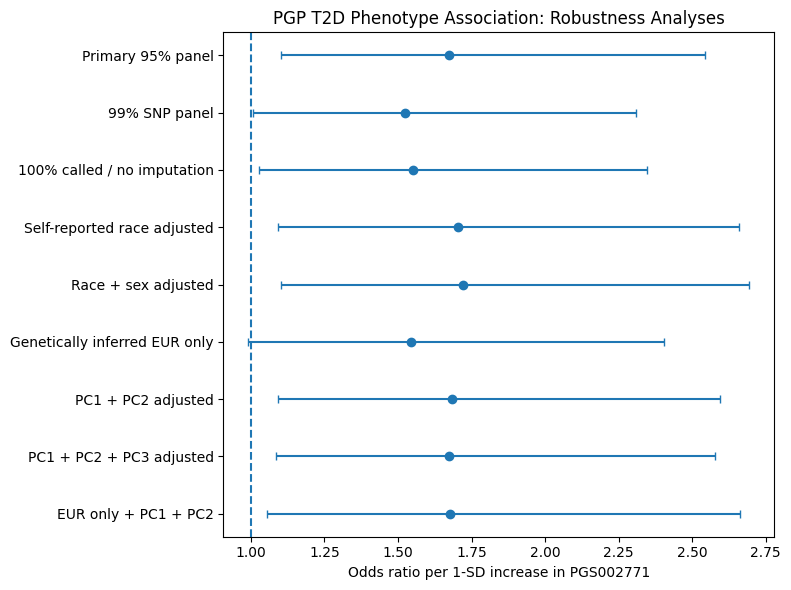


Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_PRS_robustness_forest.png


In [22]:
# ============================================================
# FINAL PHENOTYPE ROBUSTNESS SUMMARY + FOREST PLOT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/last heave for g3"

rows = [
    {
        "Analysis": "Primary 95% panel",
        "OR": 1.6733441297882354,
        "CI_low": 1.1015841077827093,
        "CI_high": 2.5418672590809295,
        "p": 0.015796854454902195
    },
    {
        "Analysis": "99% SNP panel",
        "OR": 1.5239829386539845,
        "CI_low": 1.0058327669268248,
        "CI_high": 2.30905581293058,
        "p": 0.04687435750037748
    },
    {
        "Analysis": "100% called / no imputation",
        "OR": 1.552621638830545,
        "CI_low": 1.0272351608861612,
        "CI_high": 2.3467206392013242,
        "p": 0.03684296187803288
    },
    {
        "Analysis": "Self-reported race adjusted",
        "OR": 1.703767954477602,
        "CI_low": 1.0909888469480378,
        "CI_high": 2.6607286140690034,
        "p": 0.019133942183266726
    },
    {
        "Analysis": "Race + sex adjusted",
        "OR": 1.7225413027028293,
        "CI_low": 1.1016278903446384,
        "CI_high": 2.6934217674798555,
        "p": 0.017107554077705887
    },
    {
        "Analysis": "Genetically inferred EUR only",
        "OR": 1.5441923886120232,
        "CI_low": 0.9915343717267362,
        "CI_high": 2.404889029610438,
        "p": 0.054557251221222666
    },
    {
        "Analysis": "PC1 + PC2 adjusted",
        "OR": 1.683859789343533,
        "CI_low": 1.0925346128019526,
        "CI_high": 2.595234747662888,
        "p": 0.018226556691742626
    },
    {
        "Analysis": "PC1 + PC2 + PC3 adjusted",
        "OR": 1.6724208056001746,
        "CI_low": 1.0848429053782307,
        "CI_high": 2.5782455110670286,
        "p": 0.01987178253890724
    },
    {
        "Analysis": "EUR only + PC1 + PC2",
        "OR": 1.6754525837622536,
        "CI_low": 1.0544915033581201,
        "CI_high": 2.6620805871797213,
        "p": 0.02891824490356088
    }
]

summary = pd.DataFrame(rows)

summary.to_csv(
    f"{BASE}/PGP_T2D_FINAL_robustness_table.csv",
    index=False
)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# FOREST PLOT
# ------------------------------------------------------------

plot_df = summary.iloc[::-1].copy()

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(
    plot_df["OR"],
    y,
    xerr=[
        plot_df["OR"] - plot_df["CI_low"],
        plot_df["CI_high"] - plot_df["OR"]
    ],
    fmt="o",
    capsize=3
)

ax.axvline(
    1,
    linestyle="--"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Analysis"])

ax.set_xlabel("Odds ratio per 1-SD increase in PGS002771")
ax.set_title("PGP T2D Phenotype Association: Robustness Analyses")

plt.tight_layout()

FIG_PATH = (
    f"{BASE}/PGP_T2D_PRS_robustness_forest.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(FIG_PATH)

In [24]:
# ============================================================
# FINAL AUDIT 1 — CHIP / COVERAGE-PROXY CONFOUNDING
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

FINAL_PRS = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"
CASE_SCORES = f"{BASE}/PGP_T2D_case_PGS002771_scores.csv"
CONTROL_SCORES = f"{BASE}/PGP_control_PGS002771_scores_FINAL.csv"

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

final = pd.read_csv(FINAL_PRS)

cases0 = pd.read_csv(CASE_SCORES)
controls0 = pd.read_csv(CONTROL_SCORES)

rawcov = pd.concat(
    [
        cases0[["Participant", "variants_scored"]].copy(),
        controls0[["Participant", "variants_scored"]].copy()
    ],
    ignore_index=True
)

df = final.merge(
    rawcov,
    on="Participant",
    how="left",
    validate="one_to_one"
)

print("Final cohort:", len(df))
print("Missing original coverage:", df["variants_scored"].isna().sum())

# ------------------------------------------------------------
# CHIP/COVERAGE PROXY BANDS
# Based on the clear clusters we observed earlier
# ------------------------------------------------------------

def coverage_band(n):
    if pd.isna(n):
        return np.nan
    if n < 2350:
        return "LOW_ARRAY"
    elif n < 2800:
        return "MID_ARRAY"
    else:
        return "HIGH_ARRAY"

df["array_proxy"] = df["variants_scored"].apply(coverage_band)

print("\n====================================")
print("ARRAY PROXY BY PHENOTYPE")
print("====================================")

print(
    pd.crosstab(
        df["phenotype"],
        df["array_proxy"]
    )
)

print("\nRow percentages:")
print(
    pd.crosstab(
        df["phenotype"],
        df["array_proxy"],
        normalize="index"
    )
)

# ------------------------------------------------------------
# PRS VS ORIGINAL COVERAGE
# ------------------------------------------------------------

rho = df[["PRS_z", "variants_scored"]].corr(
    method="spearman"
).iloc[0,1]

print("\nSpearman PRS_z vs original variants_scored:", rho)

# ------------------------------------------------------------
# LOGISTIC MODEL 1: UNADJUSTED
# ------------------------------------------------------------

X1 = sm.add_constant(df[["PRS_z"]])
y = df["phenotype"]

m1 = sm.Logit(y, X1).fit(disp=False)

b1 = m1.params["PRS_z"]
se1 = m1.bse["PRS_z"]

print("\n====================================")
print("UNADJUSTED")
print("====================================")
print("OR:", np.exp(b1))
print(
    "95% CI:",
    (
        np.exp(b1 - 1.96 * se1),
        np.exp(b1 + 1.96 * se1)
    )
)
print("p:", m1.pvalues["PRS_z"])

# ------------------------------------------------------------
# LOGISTIC MODEL 2: ADJUST FOR ORIGINAL COVERAGE CONTINUOUSLY
# ------------------------------------------------------------

df["variants_scored_z"] = (
    df["variants_scored"] - df["variants_scored"].mean()
) / df["variants_scored"].std(ddof=1)

X2 = sm.add_constant(
    df[["PRS_z", "variants_scored_z"]]
)

m2 = sm.Logit(y, X2).fit(disp=False)

b2 = m2.params["PRS_z"]
se2 = m2.bse["PRS_z"]

print("\n====================================")
print("ADJUSTED FOR ORIGINAL COVERAGE")
print("====================================")
print("PRS OR:", np.exp(b2))
print(
    "95% CI:",
    (
        np.exp(b2 - 1.96 * se2),
        np.exp(b2 + 1.96 * se2)
    )
)
print("PRS p:", m2.pvalues["PRS_z"])

# ------------------------------------------------------------
# LOGISTIC MODEL 3: ADJUST FOR ARRAY-PROXY CATEGORIES
# ------------------------------------------------------------

dummies = pd.get_dummies(
    df["array_proxy"],
    prefix="array",
    drop_first=True,
    dtype=float
)

X3 = pd.concat(
    [
        df[["PRS_z"]].reset_index(drop=True),
        dummies.reset_index(drop=True)
    ],
    axis=1
)

X3 = sm.add_constant(X3)

m3 = sm.Logit(y.reset_index(drop=True), X3).fit(disp=False)

b3 = m3.params["PRS_z"]
se3 = m3.bse["PRS_z"]

print("\n====================================")
print("ADJUSTED FOR ARRAY-PROXY BAND")
print("====================================")
print("PRS OR:", np.exp(b3))
print(
    "95% CI:",
    (
        np.exp(b3 - 1.96 * se3),
        np.exp(b3 + 1.96 * se3)
    )
)
print("PRS p:", m3.pvalues["PRS_z"])

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

df.to_csv(
    f"{BASE}/PGP_T2D_chip_coverage_audit.csv",
    index=False
)

print("\nSaved audit table ✅")

Final cohort: 325
Missing original coverage: 0

ARRAY PROXY BY PHENOTYPE
array_proxy  HIGH_ARRAY  LOW_ARRAY  MID_ARRAY
phenotype                                    
0                   175        101         26
1                    12         10          1

Row percentages:
array_proxy  HIGH_ARRAY  LOW_ARRAY  MID_ARRAY
phenotype                                    
0              0.579470   0.334437   0.086093
1              0.521739   0.434783   0.043478

Spearman PRS_z vs original variants_scored: -0.0008642724406556641

UNADJUSTED
OR: 1.6733441297882354
95% CI: (np.float64(1.1015841077827093), np.float64(2.5418672590809295))
p: 0.015796854454902195

ADJUSTED FOR ORIGINAL COVERAGE
PRS OR: 1.6675756989272017
95% CI: (np.float64(1.0986179163095418), np.float64(2.5311882050802423))
PRS p: 0.016317541527766027

ADJUSTED FOR ARRAY-PROXY BAND
PRS OR: 1.6631394910928088
95% CI: (np.float64(1.098315035694522), np.float64(2.5184331243206004))
PRS p: 0.01626232085115762

Saved audit table ✅


In [25]:
# ============================================================
# FINAL AUDIT 2 — PHENOTYPE LABEL PERMUTATION TEST
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

BASE = "/content/drive/MyDrive/last heave for g3"

PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"

df = pd.read_csv(PATH)

y_true = df["phenotype"].to_numpy()
x = df["PRS_z"].to_numpy()

# ------------------------------------------------------------
# OBSERVED MODEL
# ------------------------------------------------------------

X = sm.add_constant(x)

obs_model = sm.Logit(
    y_true,
    X
).fit(disp=False)

obs_beta = obs_model.params[1]
obs_or = np.exp(obs_beta)
obs_p = obs_model.pvalues[1]

obs_pred = obs_model.predict(X)
obs_auc = roc_auc_score(
    y_true,
    obs_pred
)

print("====================================")
print("OBSERVED")
print("====================================")
print("Beta:", obs_beta)
print("OR:", obs_or)
print("p:", obs_p)
print("AUC:", obs_auc)

# ------------------------------------------------------------
# PERMUTATION
# ------------------------------------------------------------

rng = np.random.default_rng(20260927)

N_PERM = 10000

perm_betas = []
perm_ors = []
perm_aucs = []

for i in range(N_PERM):

    y_perm = rng.permutation(y_true)

    try:
        m = sm.Logit(
            y_perm,
            X
        ).fit(disp=False)

        beta = m.params[1]

        pred = m.predict(X)

        auc = roc_auc_score(
            y_perm,
            pred
        )

        perm_betas.append(beta)
        perm_ors.append(np.exp(beta))
        perm_aucs.append(auc)

    except:
        continue

perm_betas = np.array(perm_betas)
perm_ors = np.array(perm_ors)
perm_aucs = np.array(perm_aucs)

# two-sided beta permutation p
perm_p_beta = (
    np.sum(
        np.abs(perm_betas) >= abs(obs_beta)
    ) + 1
) / (
    len(perm_betas) + 1
)

# one-sided AUC permutation p
perm_p_auc = (
    np.sum(
        perm_aucs >= obs_auc
    ) + 1
) / (
    len(perm_aucs) + 1
)

print("\n====================================")
print("PERMUTATION RESULTS")
print("====================================")

print("Successful permutations:", len(perm_betas))

print("\nEmpirical p — beta:")
print(perm_p_beta)

print("\nEmpirical p — AUC:")
print(perm_p_auc)

print("\nNull beta:")
print(
    pd.Series(perm_betas).describe()
)

print("\nNull AUC:")
print(
    pd.Series(perm_aucs).describe()
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

out = pd.DataFrame({
    "perm_beta": perm_betas,
    "perm_OR": perm_ors,
    "perm_AUC": perm_aucs
})

OUT = f"{BASE}/PGP_T2D_permutation_audit.csv"

out.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

OBSERVED
Beta: 0.5148240970793959
OR: 1.673344129788235
p: 0.015796854454902216
AUC: 0.6256838468183127

PERMUTATION RESULTS
Successful permutations: 10000

Empirical p — beta:
0.0173982601739826

Empirical p — AUC:
0.042195780421957804

Null beta:
count    10000.000000
mean        -0.003163
std          0.214036
min         -0.929506
25%         -0.147871
50%         -0.001102
75%          0.143047
max          0.857510
dtype: float64

Null AUC:
count    10000.000000
mean         0.549087
std          0.038115
min          0.468903
25%          0.519580
50%          0.542470
75%          0.571696
max          0.727253
dtype: float64

Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_permutation_audit.csv


In [26]:
# ============================================================
# FINAL AUDIT 3 — STRATIFIED BOOTSTRAP OF PRS ODDS RATIO
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

BASE = "/content/drive/MyDrive/last heave for g3"

PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"

df = pd.read_csv(PATH)

cases = df[df["phenotype"] == 1].copy()
controls = df[df["phenotype"] == 0].copy()

print("Cases:", len(cases))
print("Controls:", len(controls))

# ------------------------------------------------------------
# OBSERVED MODEL
# ------------------------------------------------------------

X = sm.add_constant(df[["PRS_z"]])

model = sm.Logit(
    df["phenotype"],
    X
).fit(disp=False)

obs_beta = model.params["PRS_z"]
obs_or = np.exp(obs_beta)

print("\nObserved beta:", obs_beta)
print("Observed OR:", obs_or)

# ------------------------------------------------------------
# STRATIFIED BOOTSTRAP
# Keeps exactly 23 cases and 302 controls per replicate
# ------------------------------------------------------------

rng = np.random.default_rng(20260927)

N_BOOT = 5000

boot_beta = []
boot_or = []

for i in range(N_BOOT):

    case_idx = rng.choice(
        cases.index,
        size=len(cases),
        replace=True
    )

    ctrl_idx = rng.choice(
        controls.index,
        size=len(controls),
        replace=True
    )

    boot = pd.concat(
        [
            df.loc[case_idx],
            df.loc[ctrl_idx]
        ],
        ignore_index=True
    )

    Xb = sm.add_constant(
        boot[["PRS_z"]]
    )

    yb = boot["phenotype"]

    try:

        m = sm.Logit(
            yb,
            Xb
        ).fit(disp=False)

        beta = m.params["PRS_z"]

        boot_beta.append(beta)
        boot_or.append(np.exp(beta))

    except:
        continue


boot_beta = np.array(boot_beta)
boot_or = np.array(boot_or)

# ------------------------------------------------------------
# BOOTSTRAP INTERVALS
# ------------------------------------------------------------

beta_ci = np.percentile(
    boot_beta,
    [2.5, 97.5]
)

or_ci = np.percentile(
    boot_or,
    [2.5, 97.5]
)

print("\n====================================")
print("BOOTSTRAP RESULTS")
print("====================================")

print("Successful replicates:", len(boot_or))

print("\nBootstrap beta:")
print("Mean:", boot_beta.mean())
print("Median:", np.median(boot_beta))
print("95% percentile CI:", beta_ci)

print("\nBootstrap OR:")
print("Mean:", boot_or.mean())
print("Median:", np.median(boot_or))
print("95% percentile CI:", or_ci)

print("\nFraction OR > 1:")
print(np.mean(boot_or > 1))

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

out = pd.DataFrame({
    "bootstrap_beta": boot_beta,
    "bootstrap_OR": boot_or
})

OUT = f"{BASE}/PGP_T2D_OR_bootstrap_audit.csv"

out.to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

Cases: 23
Controls: 302

Observed beta: 0.5148240970793961
Observed OR: 1.6733441297882354

BOOTSTRAP RESULTS
Successful replicates: 5000

Bootstrap beta:
Mean: 0.5246832298338361
Median: 0.5222846427945181
95% percentile CI: [0.05654671 1.00224099]

Bootstrap OR:
Mean: 1.7388961723659702
Median: 1.6858748760243443
95% percentile CI: [1.05817604 2.72438029]

Fraction OR > 1:
0.9858

Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_OR_bootstrap_audit.csv


In [5]:
# ============================================================
# FINAL AUDIT 4 — DUPLICATE / NEAR-DUPLICATE PARTICIPANT SCREEN
# Uses 100%-called SNP matrix: X_complete
# ============================================================

import pandas as pd
import numpy as np
from itertools import combinations

# Sanity checks
print("Participants:", X_complete.shape[0])
print("Complete SNPs:", X_complete.shape[1])

if X_complete.isna().any().any():
    raise ValueError("X_complete still contains missing values.")

# ------------------------------------------------------------
# PAIRWISE GENOTYPE CONCORDANCE
# concordance = fraction of SNPs with identical dosage
# ------------------------------------------------------------

ids = X_complete.index.tolist()
X = X_complete.to_numpy()

pair_results = []

for i, j in combinations(range(len(ids)), 2):

    concordance = np.mean(
        X[i, :] == X[j, :]
    )

    pair_results.append({
        "participant_1": ids[i],
        "participant_2": ids[j],
        "concordance": concordance
    })

pairs = pd.DataFrame(pair_results)

# ------------------------------------------------------------
# ADD PHENOTYPE LABELS
# ------------------------------------------------------------

phenotype_map = phenotype.to_dict()

pairs["phenotype_1"] = pairs["participant_1"].map(phenotype_map)
pairs["phenotype_2"] = pairs["participant_2"].map(phenotype_map)

# ------------------------------------------------------------
# SORT HIGHEST CONCORDANCE FIRST
# ------------------------------------------------------------

pairs = pairs.sort_values(
    "concordance",
    ascending=False
).reset_index(drop=True)

print("\n====================================")
print("TOP 20 MOST-SIMILAR PARTICIPANT PAIRS")
print("====================================")
print(pairs.head(20).to_string(index=False))

# ------------------------------------------------------------
# FLAG SUSPICIOUS PAIRS
# Thresholds are descriptive, not automatic exclusions
# ------------------------------------------------------------

exact = pairs[
    pairs["concordance"] == 1.0
].copy()

near_99 = pairs[
    pairs["concordance"] >= 0.99
].copy()

near_98 = pairs[
    pairs["concordance"] >= 0.98
].copy()

print("\n====================================")
print("DUPLICATE SCREEN SUMMARY")
print("====================================")

print("Total participant pairs:", len(pairs))
print("Exact duplicates (100%):", len(exact))
print("Pairs >= 99% concordance:", len(near_99))
print("Pairs >= 98% concordance:", len(near_98))

print("\nHighest observed concordance:")
print(pairs.iloc[0])

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive/last heave for g3"

OUT_ALL = f"{BASE}/PGP_pairwise_genotype_concordance_all.csv"
OUT_FLAGGED = f"{BASE}/PGP_duplicate_screen_flagged_pairs.csv"

pairs.to_csv(
    OUT_ALL,
    index=False
)

pairs[
    pairs["concordance"] >= 0.98
].to_csv(
    OUT_FLAGGED,
    index=False
)

print("\nSaved:")
print(OUT_ALL)
print(OUT_FLAGGED)

Participants: 325
Complete SNPs: 1327

TOP 20 MOST-SIMILAR PARTICIPANT PAIRS
participant_1 participant_2  concordance  phenotype_1  phenotype_2
     hu3D303A      huE4DAE4     1.000000            0            0
     hu28391C      hu3CEAE6     0.676714            1            0
     hu17DFDB      huA7A170     0.674454            0            0
     hu17DFDB      hu414115     0.666164            0            0
     hu7AC640      hu95C2A2     0.596835            0            0
     hu1BDE7A      huBE8E0C     0.596835            0            0
     hu633787      huA9AFFD     0.590053            0            0
     hu1BDE7A      hu95C2A2     0.589299            0            0
     hu6E9C24      hu7AC640     0.589299            0            0
     hu88F5BD      huB4C1A1     0.587792            0            0
     hu4BA913      hu5C3F07     0.586285            0            0
     hu1BDE7A      hu6E9C24     0.583271            0            0
     huA9AFFD      huBE3694     0.582517            

In [6]:
# ============================================================
# FINAL AUDIT 4B — INVESTIGATE EXACT-DUPLICATE CANDIDATE
# ============================================================

id1 = "hu3D303A"
id2 = "huE4DAE4"

g1 = dosage_all.loc[id1]
g2 = dosage_all.loc[id2]

# SNPs where BOTH participants have genotype calls
shared = g1.notna() & g2.notna()

n_shared = int(shared.sum())

# Concordance across every SNP jointly observed
full_concordance = np.mean(
    g1[shared].values == g2[shared].values
)

# Find actual genotype disagreements
diff_mask = (
    shared &
    (g1 != g2)
)

diff_snps = dosage_all.columns[diff_mask]

print("====================================")
print("DUPLICATE CANDIDATE CHECK")
print("====================================")

print("Participant 1:", id1)
print("Participant 2:", id2)

print("\nShared called SNPs:", n_shared)
print("Concordance across shared SNPs:", full_concordance)
print("Number of genotype disagreements:", int(diff_mask.sum()))

print("\nMissing genotypes:")
print(id1, ":", int(g1.isna().sum()))
print(id2, ":", int(g2.isna().sum()))

if len(diff_snps) > 0:
    print("\nDiffering SNPs:")
    print(
        pd.DataFrame({
            id1: g1.loc[diff_snps],
            id2: g2.loc[diff_snps]
        }).head(30)
    )

# ------------------------------------------------------------
# SHOW THEIR QC / PHENOTYPE RECORDS
# ------------------------------------------------------------

print("\n====================================")
print("QC RECORDS")
print("====================================")

print(
    qc[
        qc["Participant"].isin([id1, id2])
    ].to_string(index=False)
)

DUPLICATE CANDIDATE CHECK
Participant 1: hu3D303A
Participant 2: huE4DAE4

Shared called SNPs: 1976
Concordance across shared SNPs: 1.0
Number of genotype disagreements: 0

Missing genotypes:
hu3D303A : 1
huE4DAE4 : 1

QC RECORDS
Participant  n_called  call_rate  phenotype
   hu3D303A      1976   0.999494          0
   huE4DAE4      1976   0.999494          0


In [7]:
# ============================================================
# FINAL AUDIT 4C — DEDUPLICATED SENSITIVITY ANALYSIS
# Remove one member of genetically identical control pair
# Original 325-person results remain untouched
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

BASE = "/content/drive/MyDrive/last heave for g3"

PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"

df = pd.read_csv(PATH)

DROP_ID = "huE4DAE4"

print("Original N:", len(df))

# Identify participant ID column
possible_id_cols = [
    c for c in df.columns
    if c.lower() in ["participant", "participant_id", "id", "sample", "sample_id"]
]

print("Possible ID columns:", possible_id_cols)

if len(possible_id_cols) == 0:
    raise ValueError(
        "Could not identify participant ID column. "
        "Print df.columns and send me the output."
    )

ID_COL = possible_id_cols[0]

# Remove one duplicate
df_dedup = df[
    df[ID_COL] != DROP_ID
].copy()

print("Deduplicated N:", len(df_dedup))
print(
    "Cases:",
    int((df_dedup["phenotype"] == 1).sum())
)
print(
    "Controls:",
    int((df_dedup["phenotype"] == 0).sum())
)

# ------------------------------------------------------------
# LOGISTIC REGRESSION
# ------------------------------------------------------------

X = sm.add_constant(
    df_dedup[["PRS_z"]]
)

model = sm.Logit(
    df_dedup["phenotype"],
    X
).fit(disp=False)

beta = model.params["PRS_z"]
se = model.bse["PRS_z"]
p = model.pvalues["PRS_z"]

OR = np.exp(beta)
CI_low = np.exp(beta - 1.96 * se)
CI_high = np.exp(beta + 1.96 * se)

auc = roc_auc_score(
    df_dedup["phenotype"],
    df_dedup["PRS_z"]
)

print("\n====================================")
print("DEDUPLICATED SENSITIVITY RESULT")
print("====================================")

print("Dropped:", DROP_ID)
print("Beta:", beta)
print("OR per SD:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)
print("AUC:", auc)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

OUT = f"{BASE}/PGP_T2D_deduplicated_sensitivity.csv"

pd.DataFrame([{
    "N": len(df_dedup),
    "cases": int((df_dedup["phenotype"] == 1).sum()),
    "controls": int((df_dedup["phenotype"] == 0).sum()),
    "dropped_participant": DROP_ID,
    "beta": beta,
    "OR_per_SD": OR,
    "CI_low": CI_low,
    "CI_high": CI_high,
    "p": p,
    "AUC": auc
}]).to_csv(
    OUT,
    index=False
)

print("\nSaved:")
print(OUT)

Original N: 325
Possible ID columns: ['Participant']
Deduplicated N: 324
Cases: 23
Controls: 301

DEDUPLICATED SENSITIVITY RESULT
Dropped: huE4DAE4
Beta: 0.5124460233911846
OR per SD: 1.6693695219701108
95% CI: (np.float64(1.098880063541406), np.float64(2.5360316319704617))
p: 0.016307080421693862
AUC: 0.6250180557561751

Saved:
/content/drive/MyDrive/last heave for g3/PGP_T2D_deduplicated_sensitivity.csv


In [8]:
import pandas as pd

BASE = "/content/drive/MyDrive/last heave for g3"
PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"

df = pd.read_csv(PATH)

print(df.columns.tolist())

['Participant', 'phenotype', 'PRS_raw_95', 'PRS_z']


In [9]:
# ============================================================
# FINAL PGP FREEZE — DEDUPLICATED 324-PERSON COHORT
# Recalculate PRS_z + primary model + permutation + bootstrap
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

BASE = "/content/drive/MyDrive/last heave for g3"

PATH = f"{BASE}/PGP_T2D_primary_95pct_final_PRS_analysis.csv"

df = pd.read_csv(PATH)

# ------------------------------------------------------------
# 1. REMOVE ONE MEMBER OF GENETICALLY IDENTICAL CONTROL PAIR
# ------------------------------------------------------------

DROP_ID = "huE4DAE4"

final = df[
    df["Participant"] != DROP_ID
].copy()

print("====================================")
print("FINAL COHORT")
print("====================================")

print("N:", len(final))
print("Cases:", int((final["phenotype"] == 1).sum()))
print("Controls:", int((final["phenotype"] == 0).sum()))

# ------------------------------------------------------------
# 2. RECALCULATE PRS_z USING FINAL CONTROLS
# ------------------------------------------------------------

control_mask = final["phenotype"] == 0

control_mean = final.loc[
    control_mask,
    "PRS_raw_95"
].mean()

control_sd = final.loc[
    control_mask,
    "PRS_raw_95"
].std(ddof=1)

final["PRS_z_final"] = (
    final["PRS_raw_95"] - control_mean
) / control_sd

print("\nFinal control PRS mean:", control_mean)
print("Final control PRS SD:", control_sd)

# ------------------------------------------------------------
# 3. FINAL PRIMARY LOGISTIC REGRESSION
# ------------------------------------------------------------

X = sm.add_constant(
    final[["PRS_z_final"]]
)

model = sm.Logit(
    final["phenotype"],
    X
).fit(disp=False)

beta = model.params["PRS_z_final"]
se = model.bse["PRS_z_final"]
p = model.pvalues["PRS_z_final"]

OR = np.exp(beta)

CI_low = np.exp(
    beta - 1.96 * se
)

CI_high = np.exp(
    beta + 1.96 * se
)

AUC = roc_auc_score(
    final["phenotype"],
    final["PRS_z_final"]
)

print("\n====================================")
print("FINAL PRIMARY RESULT")
print("====================================")

print("Beta:", beta)
print("OR per SD:", OR)
print("95% CI:", (CI_low, CI_high))
print("p:", p)
print("AUC:", AUC)

# ============================================================
# 4. FINAL PERMUTATION TEST
# ============================================================

rng_perm = np.random.default_rng(20260928)

N_PERM = 10000

perm_beta = []
perm_auc = []

y = final["phenotype"].to_numpy()
z = final["PRS_z_final"].to_numpy()

for i in range(N_PERM):

    y_perm = rng_perm.permutation(y)

    Xp = sm.add_constant(z)

    try:
        m = sm.Logit(
            y_perm,
            Xp
        ).fit(disp=False)

        perm_beta.append(
            m.params[1]
        )

        perm_auc.append(
            roc_auc_score(
                y_perm,
                z
            )
        )

    except:
        continue

perm_beta = np.array(perm_beta)
perm_auc = np.array(perm_auc)

# one-sided empirical test for positive association
perm_p_beta = (
    np.sum(perm_beta >= beta) + 1
) / (
    len(perm_beta) + 1
)

# one-sided AUC test relative to observed discrimination
perm_p_auc = (
    np.sum(perm_auc >= AUC) + 1
) / (
    len(perm_auc) + 1
)

print("\n====================================")
print("FINAL PERMUTATION RESULTS")
print("====================================")

print("Successful permutations:", len(perm_beta))
print("Empirical p — beta:", perm_p_beta)
print("Empirical p — AUC:", perm_p_auc)

# ============================================================
# 5. FINAL STRATIFIED BOOTSTRAP
# ============================================================

cases = final[
    final["phenotype"] == 1
].copy()

controls = final[
    final["phenotype"] == 0
].copy()

rng_boot = np.random.default_rng(20260928)

N_BOOT = 5000

boot_beta = []
boot_or = []
boot_auc = []

for i in range(N_BOOT):

    case_idx = rng_boot.choice(
        cases.index,
        size=len(cases),
        replace=True
    )

    ctrl_idx = rng_boot.choice(
        controls.index,
        size=len(controls),
        replace=True
    )

    boot = pd.concat(
        [
            final.loc[case_idx],
            final.loc[ctrl_idx]
        ],
        ignore_index=True
    )

    Xb = sm.add_constant(
        boot[["PRS_z_final"]]
    )

    yb = boot["phenotype"]

    try:

        m = sm.Logit(
            yb,
            Xb
        ).fit(disp=False)

        b = m.params["PRS_z_final"]

        boot_beta.append(b)
        boot_or.append(np.exp(b))

        boot_auc.append(
            roc_auc_score(
                yb,
                boot["PRS_z_final"]
            )
        )

    except:
        continue

boot_beta = np.array(boot_beta)
boot_or = np.array(boot_or)
boot_auc = np.array(boot_auc)

OR_boot_CI = np.percentile(
    boot_or,
    [2.5, 97.5]
)

AUC_boot_CI = np.percentile(
    boot_auc,
    [2.5, 97.5]
)

print("\n====================================")
print("FINAL BOOTSTRAP RESULTS")
print("====================================")

print("Successful replicates:", len(boot_or))

print("\nBootstrap OR:")
print("Mean:", boot_or.mean())
print("Median:", np.median(boot_or))
print("95% percentile CI:", OR_boot_CI)
print("Fraction OR > 1:", np.mean(boot_or > 1))

print("\nBootstrap AUC:")
print("Mean:", boot_auc.mean())
print("Median:", np.median(boot_auc))
print("95% percentile CI:", AUC_boot_CI)

# ============================================================
# 6. SAVE FINAL FROZEN FILES
# ============================================================

FINAL_COHORT_OUT = (
    f"{BASE}/PGP_T2D_FINAL_DEDUPLICATED_324.csv"
)

SUMMARY_OUT = (
    f"{BASE}/PGP_T2D_FINAL_FROZEN_SUMMARY.csv"
)

PERM_OUT = (
    f"{BASE}/PGP_T2D_FINAL_permutation_distribution.csv"
)

BOOT_OUT = (
    f"{BASE}/PGP_T2D_FINAL_bootstrap_distribution.csv"
)

final.to_csv(
    FINAL_COHORT_OUT,
    index=False
)

summary = pd.DataFrame([{
    "N": len(final),
    "cases": int((final["phenotype"] == 1).sum()),
    "controls": int((final["phenotype"] == 0).sum()),
    "excluded_duplicate": DROP_ID,
    "OR_per_SD": OR,
    "CI_low": CI_low,
    "CI_high": CI_high,
    "logistic_p": p,
    "AUC": AUC,
    "permutation_p_beta": perm_p_beta,
    "permutation_p_AUC": perm_p_auc,
    "bootstrap_OR_median": np.median(boot_or),
    "bootstrap_OR_CI_low": OR_boot_CI[0],
    "bootstrap_OR_CI_high": OR_boot_CI[1],
    "bootstrap_fraction_OR_gt_1": np.mean(boot_or > 1),
    "bootstrap_AUC_median": np.median(boot_auc),
    "bootstrap_AUC_CI_low": AUC_boot_CI[0],
    "bootstrap_AUC_CI_high": AUC_boot_CI[1]
}])

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

pd.DataFrame({
    "permutation_beta": perm_beta,
    "permutation_AUC": perm_auc
}).to_csv(
    PERM_OUT,
    index=False
)

pd.DataFrame({
    "bootstrap_beta": boot_beta,
    "bootstrap_OR": boot_or,
    "bootstrap_AUC": boot_auc
}).to_csv(
    BOOT_OUT,
    index=False
)

print("\n====================================")
print("FINAL FILES SAVED")
print("====================================")

print(FINAL_COHORT_OUT)
print(SUMMARY_OUT)
print(PERM_OUT)
print(BOOT_OUT)

FINAL COHORT
N: 324
Cases: 23
Controls: 301

Final control PRS mean: 0.6106323123192846
Final control PRS SD: 0.34784013299833977

FINAL PRIMARY RESULT
Beta: 0.5129187958469313
OR per SD: 1.670158940491524
95% CI: (np.float64(1.0989756609101304), np.float64(2.5382098855525768))
p: 0.016307080421693862
AUC: 0.6250180557561751

FINAL PERMUTATION RESULTS
Successful permutations: 10000
Empirical p — beta: 0.0084991500849915
Empirical p — AUC: 0.024197580241975804

FINAL BOOTSTRAP RESULTS
Successful replicates: 5000

Bootstrap OR:
Mean: 1.7334999945066207
Median: 1.675496466372743
95% percentile CI: [1.06020031 2.74104774]
Fraction OR > 1: 0.986

Bootstrap AUC:
Mean: 0.6261668351870576
Median: 0.6264625162501806
95% percentile CI: [0.50180196 0.75054528]

FINAL FILES SAVED
/content/drive/MyDrive/last heave for g3/PGP_T2D_FINAL_DEDUPLICATED_324.csv
/content/drive/MyDrive/last heave for g3/PGP_T2D_FINAL_FROZEN_SUMMARY.csv
/content/drive/MyDrive/last heave for g3/PGP_T2D_FINAL_permutation_dist

In [10]:
# ============================================================
# FINAL PERMUTATION REPORTING — TWO-SIDED EMPIRICAL P VALUES
# Uses already-generated permutation distributions
# ============================================================

two_sided_beta_p = (
    np.sum(np.abs(perm_beta) >= np.abs(beta)) + 1
) / (
    len(perm_beta) + 1
)

two_sided_auc_p = (
    np.sum(
        np.abs(perm_auc - 0.5) >= np.abs(AUC - 0.5)
    ) + 1
) / (
    len(perm_auc) + 1
)

print("Two-sided permutation p — beta:", two_sided_beta_p)
print("Two-sided permutation p — AUC:", two_sided_auc_p)

Two-sided permutation p — beta: 0.019198080191980802
Two-sided permutation p — AUC: 0.0484951504849515
